#  <div align="center"> Model of  fatty acid de novo synthesis 
    
    
<div align="center"> <img src="FADNS_1.svg" width=800 height=600/>

    
In this part we investigate the search of parameters to reproduce the data from *weiss et al. 2003*.

We consider the simple description of the invitro experiment of the paper where Acetyl-CoA, malonyl-CoA and NADPH are incubated in presence of Fatty acid synthase. 
    
   Total volume  =  50 $\mu L$,
   NADPH = 450 $\mu M$,
   Acetyl-CoA =  80 $\mu M$,
   Malonyl-CoA = 75 $\mu M$,
   Mass liver extract ontaining FASN =  3.3 $\mu g$,
   The liver extract contain about 0.4% in mass of the enzyme. Therefore the mass of the enzyme is mass FASN =  3.3*0.4/100 3.3 = 0.0132 $\mu g$. (here is by considering the molecular mass to be 540 KDa)
   We calculated the concentration of FASN which yields to $0.00049 \mu M$.
    
  We modify the previous version of the model by adding an additional step where the free FASN first attached to acetyl-CoA to form and intermediate that we call $EC2$ (complex enzyme substrate), the EC2 received the malonyl-CoA and NADPH to fom the next complex that we term as $EC4$. In the subsequent steps, the couple malonyl-CoA NADPH are added to form a complex enzyme substrate $EC_{2i}$, where $2i$ represent the number of carbon. Every complex from EC4 to EC18 are sujected to two additional reaction apart from the elongation reaction. Those reaction are:
* The formation of $C_{2i}FA$ with a rate $K_{di}$.
* An influx resulting from the association of the free enzyme with a $C_{2i}FA$. This reactions occurs with the rate $k_{ai}$

# Warning !!!!

## The noise from initial measurements are substrated from all the data points

# Using the initial condition from the paper
Indeed in the paper of *Weiss et al.*, the initial condition for C16:0 is not 0 but around 900 DPM i.e 900/681 = 1.32 $\mu M$. 

By using the combination of this information and the ratio from *Ohashi et al. 1985* to infer the initial conditions of C14: 0 and C18:0.

<!-- $AceylC0A$ + $n$ $MalonylCoA$ + $2n$ $(NADPH + H^{+})$ $\longrightarrow$ $n$ $CO_2$ +$(n+1)$ $COA$ + $2n$ $NADP^{+}$ + $CH_{3}(CH_{2})_{n}COOH$

<img src="FADNS_full.pdf" width=800 height=400/>


The model considers mass action kinetics where fix amount of Acetyl-CoACarboxylase 1 and Fatty acid synthetase are given as well are rducing equivalents, which are considered to be conserved. The process each processes are represented step-wise and  the individual reactions are considered to be irreversible. all the external metabolites are considered as parameters. 

We further suppose that there is a compound in the cell that produce $ATP$ from $ADP$ and $Pi$, we can further suppose that there is no limitation of $Pi$. Subsequently, we make a similar consideration for the production of  and $NADPH$ following  

<span style="color:red"> $$ ADP + Pi \longrightarrow ATP, \qquad   v_{adp\rightarrow atp} =  \dfrac{V_{max_{adp}}\cdot ADP}{K_{m_{adp}} + ADP} $$ </span>

<span style="color:red">  $$NADP^{+} +H^{+} \longrightarrow NADPH, \qquad   v_{nadp\rightarrow nadph} = \dfrac{V_{max_{nadp}} \cdot NADP^{+}}{ K_{m_{nadp}}+ NADP^{+}}$$ </span>


### 10.09.2021


After verifications, we dont't need to produce ATP via ADP as the conservation relation warranty the availability of the conserve quatities. However, it is important to check on the initial conditions to make sure that it doesn't violate the conservation relations. -->

In [2]:
import json
import random as rd
import sys
import string
import time
from collections import ChainMap
from concurrent.futures import ProcessPoolExecutor
from math import ceil, erf, log10
from pathlib import Path
from typing import Callable, Tuple

import matplotlib._color_data as mcd
import matplotlib.lines as lines
import matplotlib.patches as mpatch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.integrate as sp
import scipy.stats
import seaborn as sns
from assimulo.problem import Explicit_Problem
from assimulo.solvers import CVode
from assimulo.solvers.sundials import CVodeError  # For handling errors
from lmfit import Parameter, Parameters, minimize, report_fit
from matplotlib import cm
from mpl_toolkits.mplot3d import axes3d
from SALib.analyze import morris, sobol
from SALib.plotting.bar import plot as barplot
from SALib.sample import saltelli
from SALib.test_functions import Ishigami
from scipy.interpolate import lagrange
from scipy.linalg import null_space
from tqdm import tqdm, trange

from model import *
from read_and_convert_weiss_data import read_and_convert_data

plt.style.use("default")


plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.weight"] = "bold"
# plt.rcParams["axes.labelweight"] = "bold"
# plt.rcParams['axes.titlepad'] = 23


colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cols = [f"{color}" for color in colors]


RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

In [3]:

(
        time_experiment,  
        time_course_data_mean,  
       time_course_data_mean_numpy,  
    ) = read_and_convert_data()

/home/chilperic/semi-mechanistic-model-of-fatty-acids-de-novo-synthesis/models/CoA-inhibition_only_14_16_18_can_be_produced/read_and_convert_weiss_data.py:74: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  time_course_data_mean["C14:0"][0] =deviation_C14
/home/chilperic/semi-mechanistic-model-of-fatty-acids-de-novo-synthesis/models/CoA-inhibition_only_14_16_18_can_be_produced/read_and_convert_weiss_data.py:75: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  time_course_data_mean["C16:0"][0] =deviation_C16
/home/chilperic/semi-mechanistic-model-of-fatty-acids-de-novo-synthesis/models/CoA-inhibition_only_14_16_18_can_be_pro

# Plot the data 

Text(0, 0.5, 'concentration ($\\mu M$)')

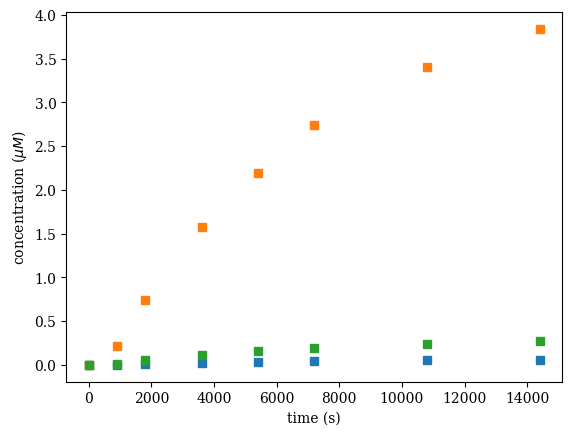

In [4]:
plt.plot(time_experiment, time_course_data_mean_numpy[:,1:], "s", linewidth=1)
plt.xlabel("time (s)")
plt.ylabel("concentration ($\mu M$)")

In [5]:
data = time_course_data_mean_numpy[:,1:]


# Fuction for simulations 

In [6]:
def multi_plot_time_course(
    groups: list[list],
    func: callable,
    model: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=False,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    group = group of compounds to be plotted (just giving the oportunityto plot them together)
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))
   

    nrows = ceil(len(groups) / ncols)


    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )

    for ax, group in zip(axs.flatten(), groups):
        data.reindex(columns=group).plot(ax=ax, linewidth=3)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=16.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=16.0)
    fig.patch.set_alpha(0.0)  # to make the axis transparent
    fig.suptitle(title, fontsize=16.0)

    fig.tight_layout()
    return fig, axs

In [7]:
def multi_plot_fluxes(
    fluxes_list: list[list[str]],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
      flux_groups = list of list of  fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))
    nrows = ceil(len(fluxes_list) / ncols)
    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    axes = axs.flat
    for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
            size=20, weight='bold')
    for ax, group in zip(axs.flatten(), fluxes_list):
        fluxes.reindex(columns=group).plot(
            ax=ax, fontsize=16, linewidth=3,
        )
        ax.legend(prop=dict(size=14))
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=20.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=20.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=14)
    fig.suptitle(title, fontsize=20.0)
    fig.tight_layout()
    return fig, axs


In [8]:
def plot_fluxes_individually(
    list_fluxes: list[str],
    model: callable,
    rates: callable,
    y0: list[float],
    par: dict[str, float],
    max_time: float,
    ncp_list: list[float],
    ncols: int,
    resizer=4,
    sharey=False,
    sharex=True,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):

    """
    required library: pandas, matplotlib, assimulo
    list_fluxes = list of fluxes to be plotted, indeed the entrees should match the list of
    keys in the rates dictionnary
    model = system of ODE to be integrated(this function is dependent of the rate )
    rates = funtion that define the rates
    y0 = list/np.1D.array  of initial conditions
    par = dictionnary of parameters( dictionnay of string to float)
    max_time =  maximum time for simulation
    ncp_list = number of communication points to be passed to the integrator
    ncols  = number of colums for the subplots


    """

    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )

    y = y.T
    fluxes = pd.DataFrame(rates(y, par))
    fluxes =fluxes.rename(dict(enumerate(time)))

    nrows = ceil(len(list_fluxes) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharey=sharey,
        sharex=sharex,
        squeeze=False,
    )
    axes = axs.flat
    for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
            size=20, weight='bold')
    for ax, group in zip(axs.flatten(), list_fluxes):
        fluxes.loc[:, group].plot(ax=ax, linewidth=3)
        ax.set_title(group, fontsize=20.0)

    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=20.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=20.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=14)
    fig.suptitle(title, fontsize=20.0)
    fig.tight_layout()
    return fig, axs


In [9]:
def plot_individual_time_course(
    compounds_to_plot: list[str],
    func: callable,
    model: callable,
    y0: list[float],
    max_time: float,
    ncp_list: list[float],
    par: dict[str, float],
    compounds: list[str],
    ncols: int,
    resizer=4,
    sharex=True,
    sharey=False,
    title: str = None,
    xlabel: str = None,
    ylabel: str = None,
):
    """
    required library: pandas, matplotlib, assimulo
    func = function that simulate the time course
    model =  system of differential equation to be integrated
    y0 = initial condition it can be either a list of float or np.1D.array
    max_time =  maximum time for simulation
    ncp_list = number of communication points
    compounds =  list of compounds to be plotted
    par =  dictionnay of string to float

    """
    time, y = simulate_time_course(
        model=system, par=par, y0=y0, max_time=max_time, ncp_list=ncp_list
    )
    y = y.T
    Comp = dict(zip(compounds, y))
    data = pd.DataFrame(Comp)
    data =data.rename(dict(enumerate(time)))

    nrows = ceil(len(compounds_to_plot) / ncols)

    fig, axs = plt.subplots(
        nrows,
        ncols,
        figsize=(resizer * ncols, resizer * nrows),
        sharex=sharex,
        sharey=sharey,
        squeeze=False,
    )
    axes = axs.flat
    for n , ax in enumerate(axes):
        ax.text(-0.1, 1.1, string.ascii_uppercase[n], transform=ax.transAxes, 
            size=20, weight='bold')

    for ax, group in zip(axs.flatten(), compounds_to_plot):
        data.loc[:, group].plot(ax=ax, linewidth=3)
        ax.set_title(group, fontsize=20.0)
    #         ax.set_ylabel(ylabel, fontsize=20)
    #         ax.set_xlabel(xlabel, fontsize=20.0)
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel, fontsize=20.0)
    for ax in axs[-1, :]:
        ax.set_xlabel(xlabel, fontsize=20.0)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=14)
    fig.suptitle(title, fontsize=20.0)

    fig.tight_layout()

    return fig, axs



# Simulation of the model 

## First choice parameters 
We consider the scenario in which only three type of fatty acids could be produced, those are C14, C16 and C18. Therefore, all the $ka_i = 0$, $kd_1$ to $kd_5$ are all 0. The value of $\kappa$ was calculated by considering the quasi steady state of all enzyme species and the initial phase data from *Topolska et al*. 2020.

In [10]:
par = {
    "beta": 1e-1,
    "kappa": 3e-6,
    "delta":4.7e-6,  #
    "nu":1,
    "std":1,
    "kd1": 0,
    "kd2": 0,
    "kd3": 0,
    "kd4": 0,
    "kd5": 0,
    "kd6": 0.000003,
    "kd7": 1.18,  # calculated
    "kd8":1,
    "kf_CoA":1e-3,
     "kb_CoA":1e-3,
    
   
}


## The initial conditions 

In the tracer experiment by *Topolska et al. 2020* to measure the t

According to *Topolska et al. 2020* A the malonyl-CoA that was used for this experiment was contaminated by acetyl-CoA and there we have to make the corrections for the right amount of each substrates used in this experiment. 
The main product of the de novo fatty acids synthesis which is C16:0 
The correction for the initial conditions for acetyl-CoA and malonyl-CoA was first tried by 

In [11]:
# list of time points to be considered by the integrator
ncp_list1 = [i for i in range(0, 14400, 1)]
ncp_list2 = [i for i in range(0, 14400)]
max_time1 = ncp_list1[-1]
max_time2 = ncp_list2[-1]
init = np.zeros(n_compounds)
# init = 10*np.random.uniform(0,1,n_compounds)
time_simulations = time_experiment.copy()
y0_dict = dict(zip(compounds, init))

# modifying initial conditions
y0_dict["E"] =0.00049
y0_dict["AcetylCoA"] =80
y0_dict["NADPH"] = 450
y0_dict["MalonylCoA"] = 75
y0_dict["C14FA"] = 0.0
y0_dict["C16FA"] = 0
y0_dict["C18FA"] = 0
y0_dict["ECoA"] =0
y0 = np.fromiter(y0_dict.values(), dtype=float)


In [12]:
compounds

['AcetylCoA',
 'MalonylCoA',
 'C14FA',
 'C16FA',
 'C18FA',
 'CoA',
 'E',
 'EC2',
 'EC4',
 'EC6',
 'EC8',
 'EC10',
 'EC12',
 'EC14',
 'EC16',
 'EC18',
 'ECoA',
 'NADPH']

# Check the fluxes 

### Plot fluxes by group

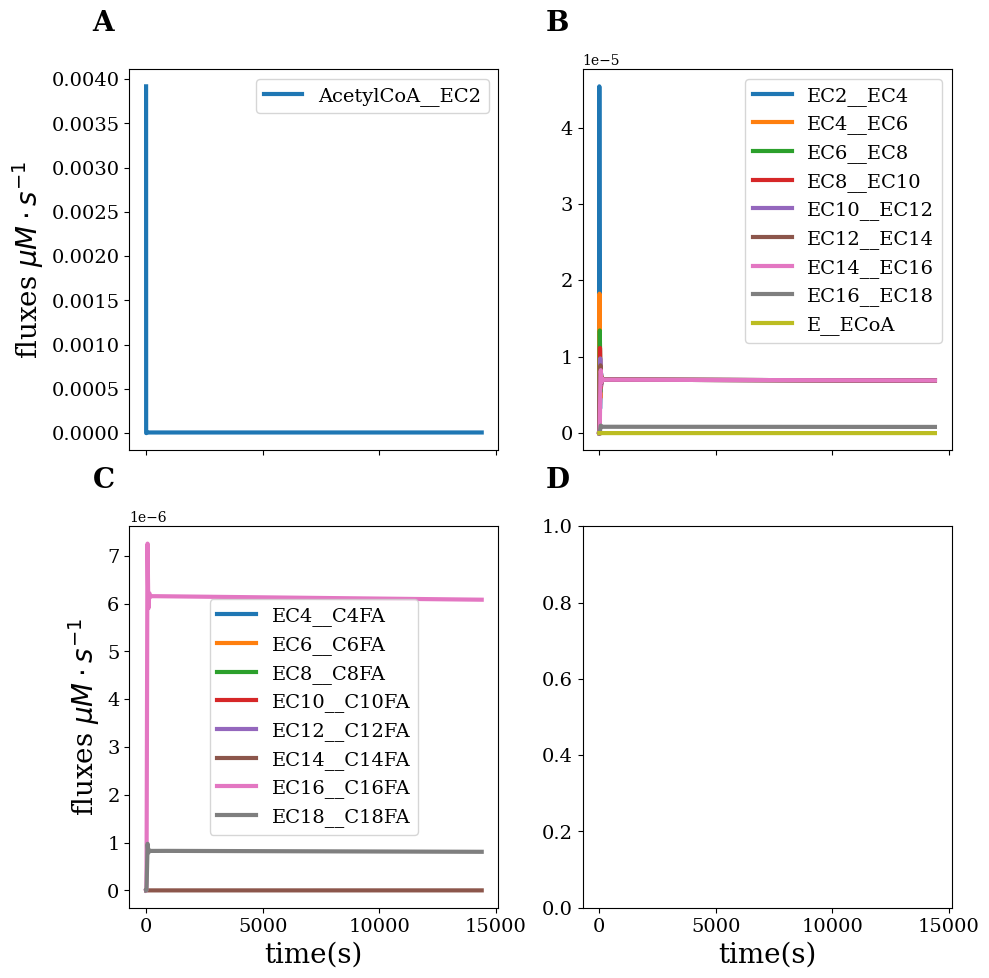

In [13]:
flux_groups = [
    ["AcetylCoA__EC2"],
    [
        "EC2__EC4",
        "EC4__EC6",
        "EC6__EC8",
        "EC8__EC10",
        "EC10__EC12",
        "EC12__EC14",
        "EC14__EC16",
        "EC16__EC18",
        "E__ECoA"
    ],
    [
        "EC4__C4FA",
        "EC6__C6FA",
        "EC8__C8FA",
        "EC10__C10FA",
        "EC12__C12FA",
        "EC14__C14FA",
        "EC16__C16FA",
        "EC18__C18FA",
    ],
    
]


fig, axs = multi_plot_fluxes(
    fluxes_list=flux_groups,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=2,
    resizer=5,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="fluxes $\mu M \cdot s^{-1}$",
)


In [14]:
rates(y0, par)

{'AcetylCoA__EC2': 0.00392,
 'EC2__EC4': 0.0,
 'EC4__EC6': 0.0,
 'EC6__EC8': 0.0,
 'EC8__EC10': 0.0,
 'EC10__EC12': 0.0,
 'EC12__EC14': 0.0,
 'EC14__EC16': 0.0,
 'EC16__EC18': 0.0,
 'EC14__C14FA': 0.0,
 'EC16__C16FA': 0.0,
 'EC18__C18FA': 0.0,
 'E__ECoA': 0.0}

### Elongation individual fluxes 

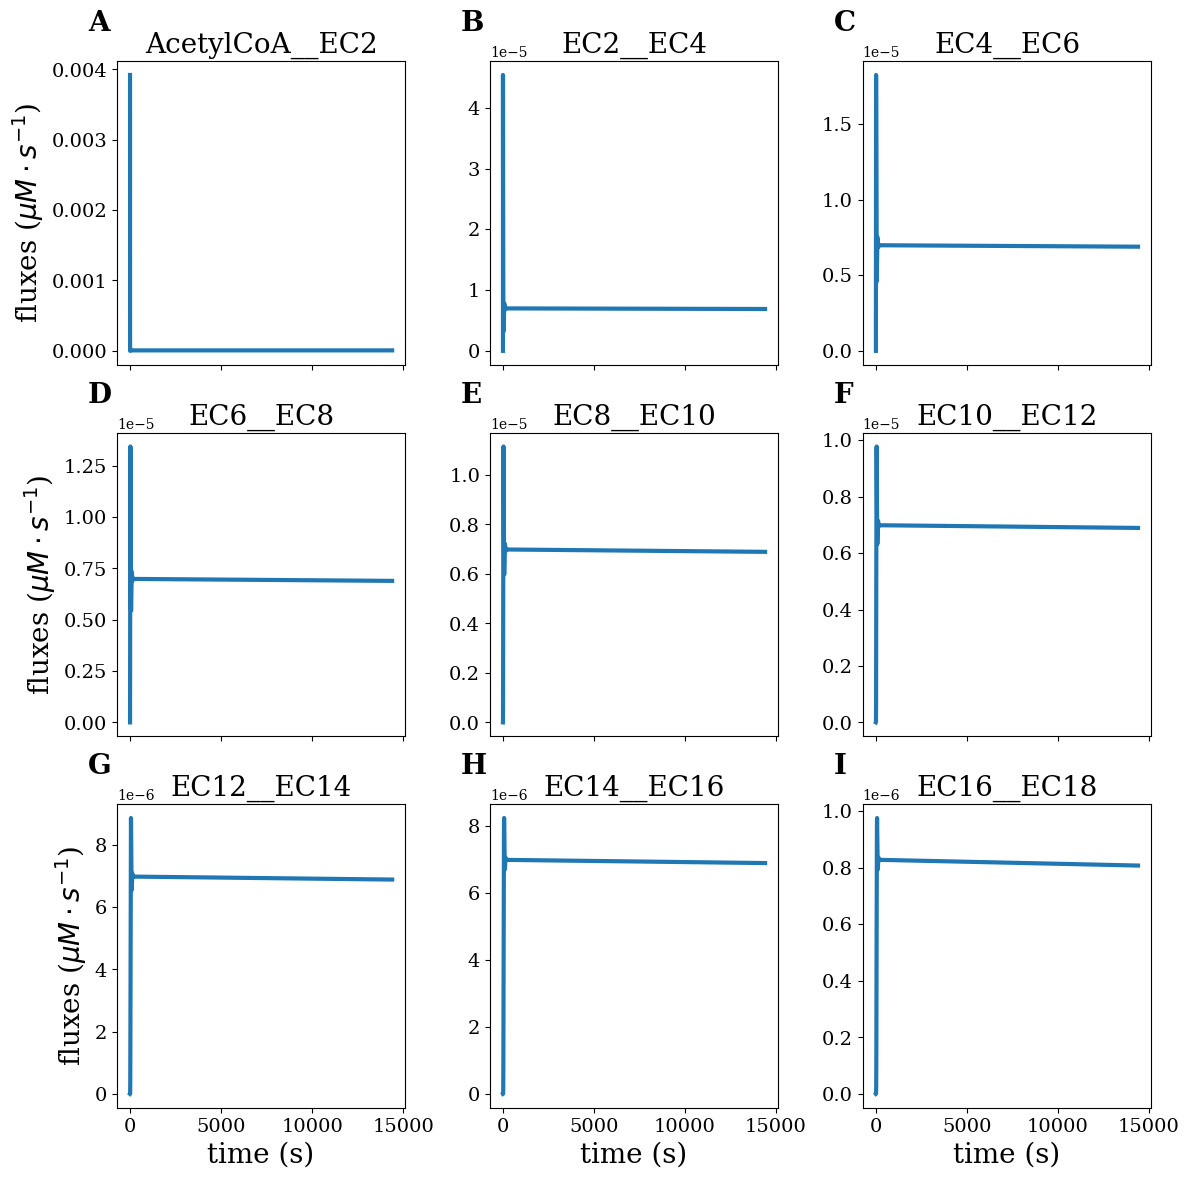

In [15]:
elongation_fluxes = [
    "AcetylCoA__EC2",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
    "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
]

fig, axs = plot_fluxes_individually(
    list_fluxes=elongation_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=3,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)


### production individual fluxes 

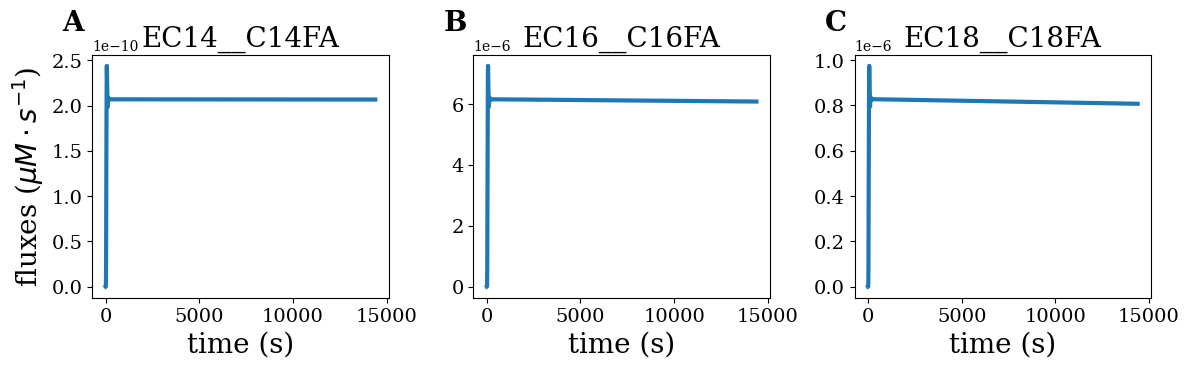

In [16]:
production_fluxes = [

    "EC14__C14FA",
    "EC16__C16FA",
    "EC18__C18FA",
]


fig, axs = plot_fluxes_individually(
    list_fluxes=production_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=par,
    max_time=max_time1,
    ncp_list=ncp_list1,
    ncols=3,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)


# Plot the time course 

### Plot time course by group

To Estimate the value of parameters that reproduce Topolska and al. data, we first consider the rapid binding given that the subtrates are in excess.Furthermore we consider that production of short and meduim chain fatty acid are negligeable compare to to those of LCFAS as shown by experimental data.On this assumptions, instantaneously the concentration of the total enzyme is sensibly equal to the cocentrattion of $EC_{16}$. From this concentration of the enzyme we can estimate $k_{d7}$ and $\delta$. For the estimation of the later, we additionnally assume that the flux into $EC_{18}$ are equal to the flux of production of of $C18:0$ FA.

under this assumptions, we have $$k_{d7} = 0.028, \qquad  \delta= 2.9e-07$$


We choose the value of $\beta$ and $\kappa$

In [17]:
par = {
    "beta": 1e-1,
    "kappa": 3e-6,
    "delta":4.7e-6,  #
    "kd5": 0,
    "kd6": 0.000003,
    "kd7": 1.18,  # calculated
    "kd8":1,
    "kf_CoA":1e-3,
     "kb_CoA":1e-3,
    
   
}


In [18]:
rates(y0, par)

{'AcetylCoA__EC2': 0.00392,
 'EC2__EC4': 0.0,
 'EC4__EC6': 0.0,
 'EC6__EC8': 0.0,
 'EC8__EC10': 0.0,
 'EC10__EC12': 0.0,
 'EC12__EC14': 0.0,
 'EC14__EC16': 0.0,
 'EC16__EC18': 0.0,
 'EC14__C14FA': 0.0,
 'EC16__C16FA': 0.0,
 'EC18__C18FA': 0.0,
 'E__ECoA': 0.0}

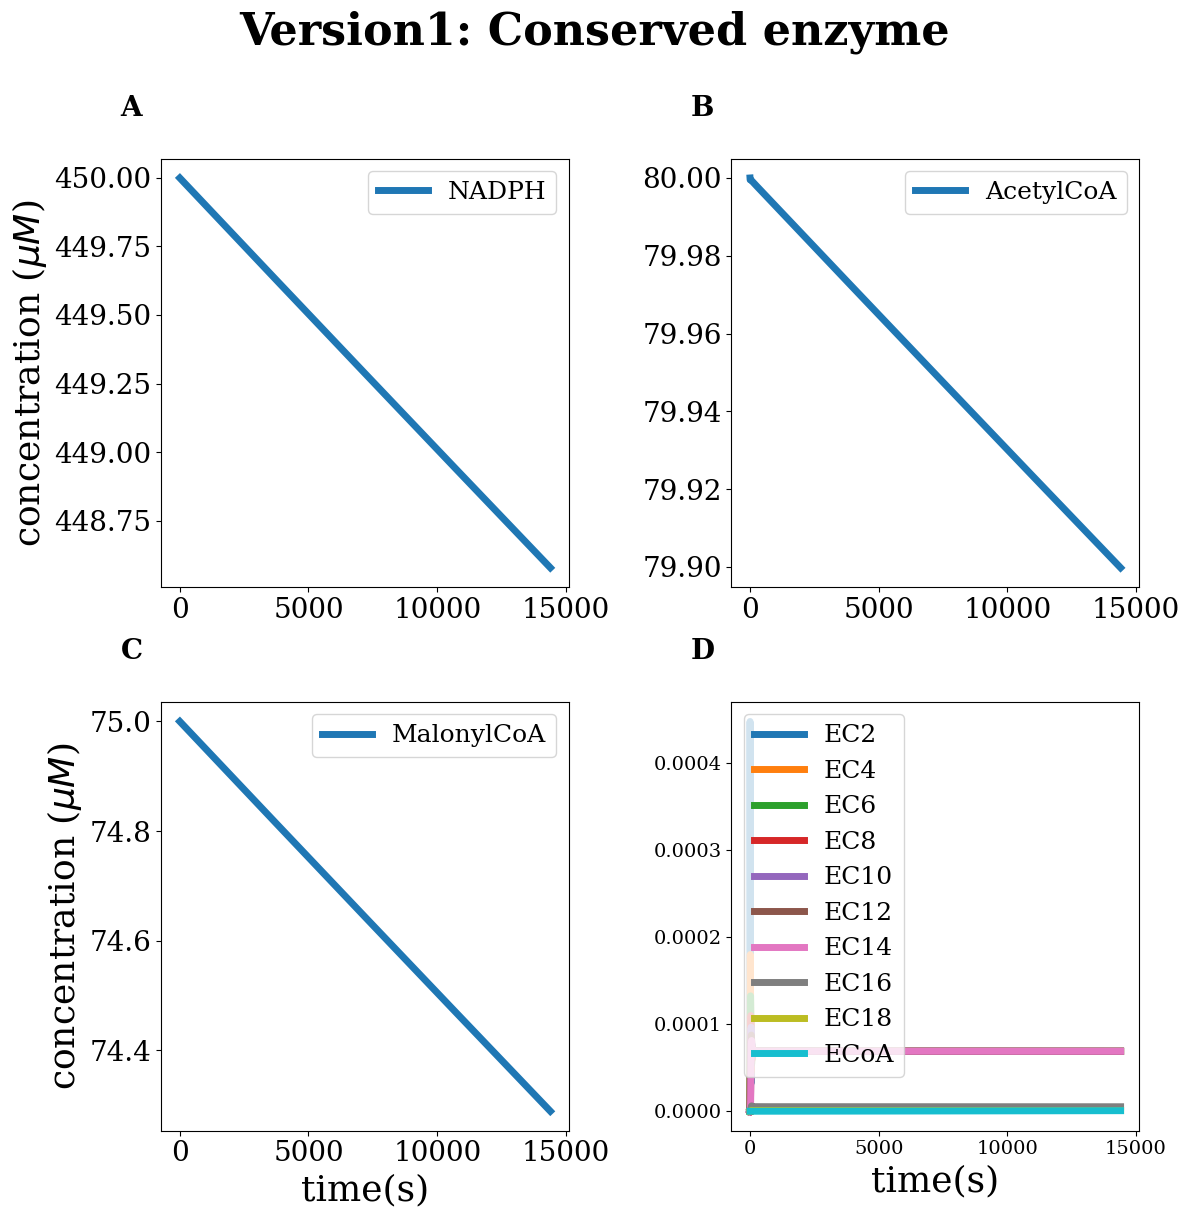

In [19]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
     ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18", "ECoA"],
    
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=2,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph
# for i in range(3):
#        axs[1, 1].plot(time_initial_phase, initial_phase_data1[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR /"init12.pdf", dpi=300)


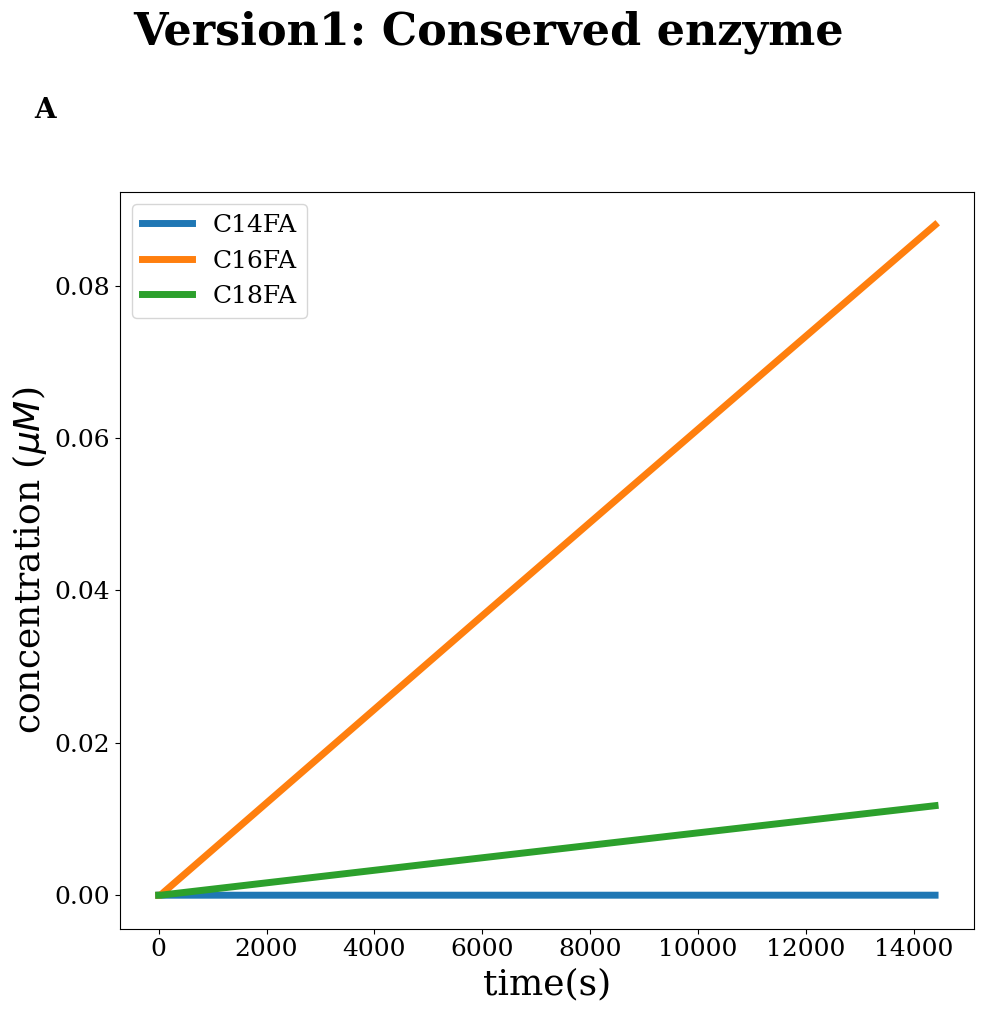

In [20]:
time_courseA =[["C14FA", "C16FA", "C18FA",],
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_courseA,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=1,
    resizer=10,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=18)
# adding data to a particular graph
# for i in range(3):
#        axs[1, 1].plot(time_initial_phase, initial_phase_data1[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR /"init12.pdf", dpi=300)


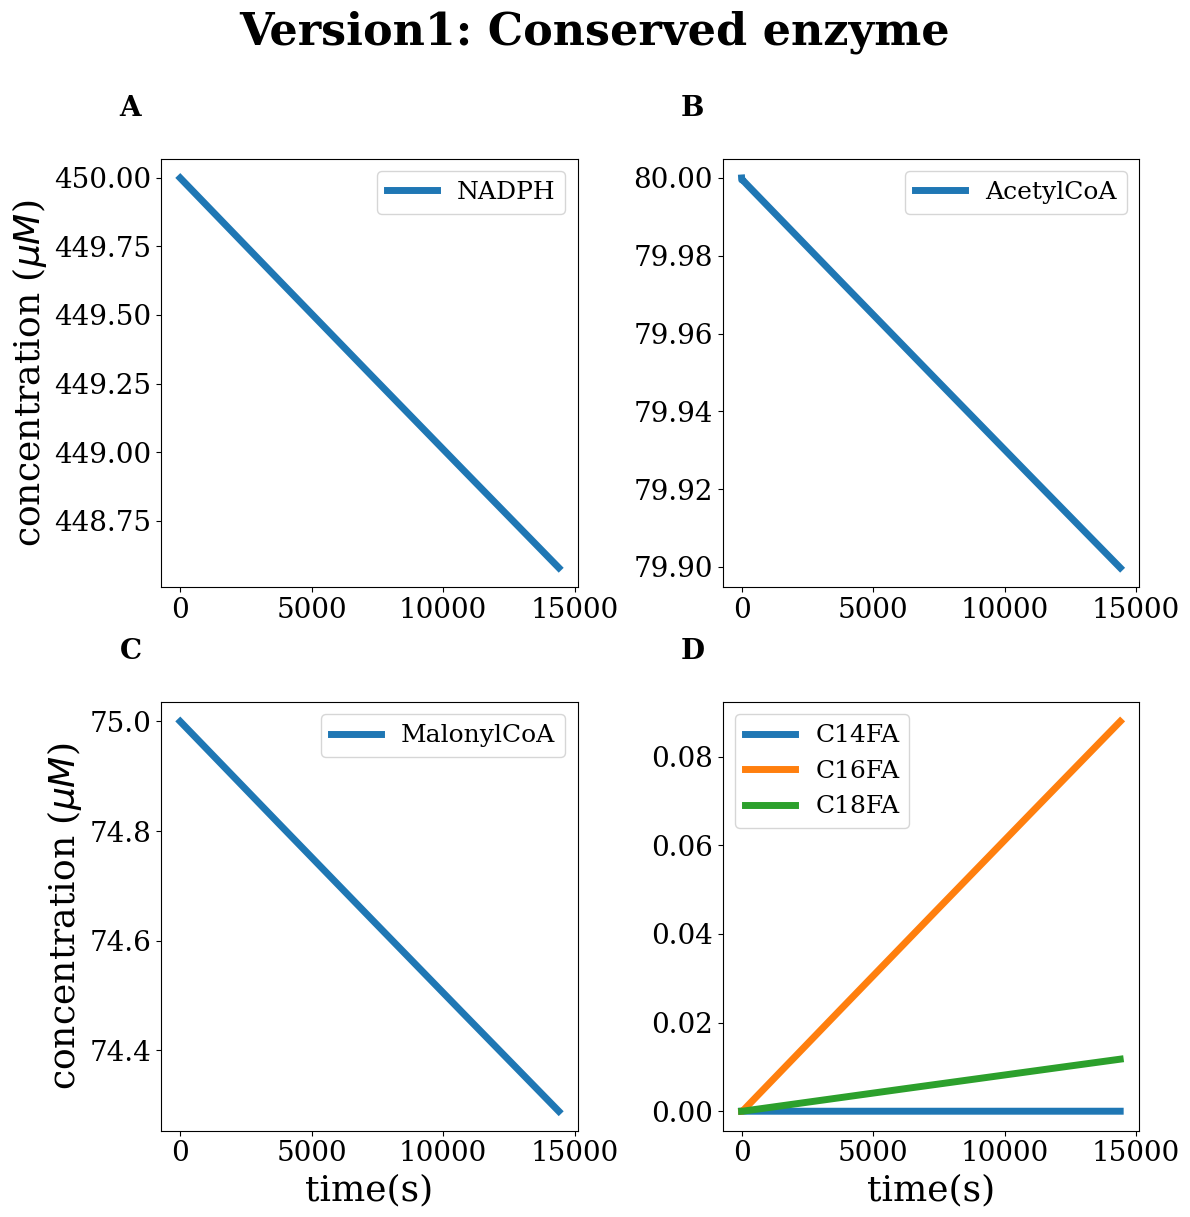

In [21]:
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    #["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    [
        "C14FA",
        "C16FA",
        "C18FA",
    ],
]


colors = ["#1f77b4", "orange", "green"]


fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    
    ncols=2,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)

# adding data to a particular graph
# for i in range(3):
#     axs[1, 1].plot(time_initial_phase, initial_phase_data1[:, i], "o", color=colors[i])

# plt.tick_params(axis="both", labelsize=18)
# plt.savefig(RESULTS_DIR /"init1.pdf", dpi=300)



In [22]:
par = {
    "beta": 1e-1,
    "kappa": 3e-6,
    "delta":4.7e-6,  #
    "kd1": 0,
    "kd2": 0,
    "kd3": 0,
    "kd4": 0,
    "kd5": 0,
    "kd6": 0.000003,
    "kd7": 1.18,  # calculated
    "kd8":1,
    "kf_CoA":1e-3,
     "kb_CoA":1e-3,
    
   
}


In [23]:
simulated_nefas =  fatty_acid_of_interest(par=par, y0= y0, max_time=max_time2, system=system, ncp_list=ncp_list2)

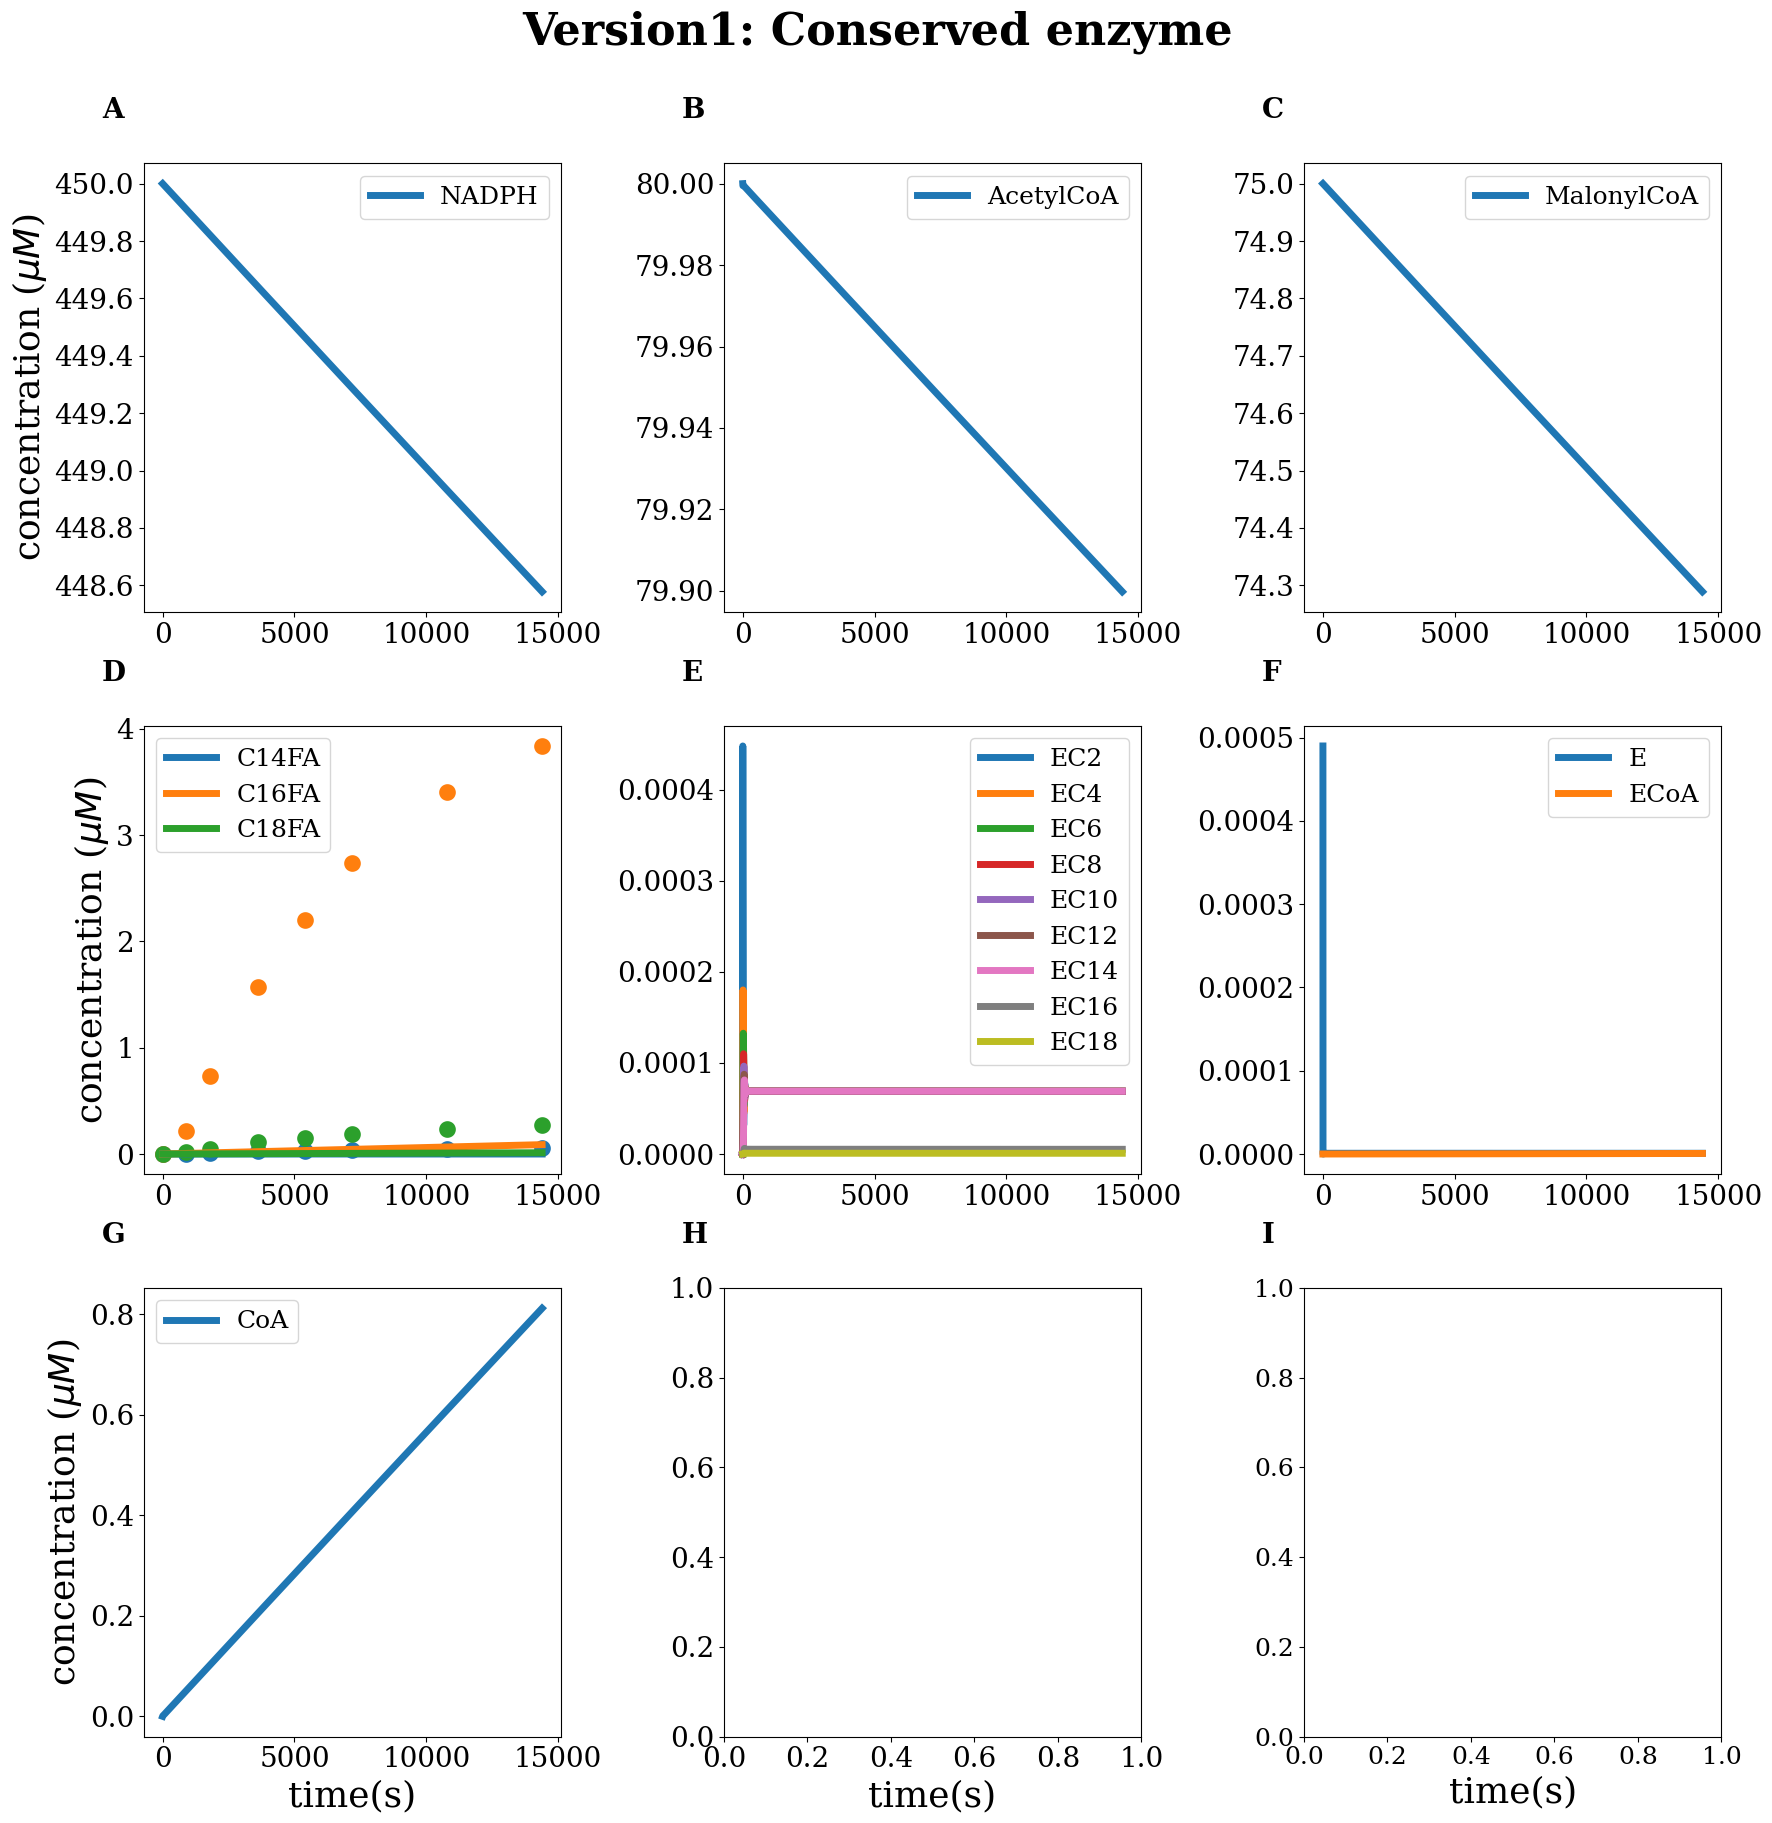

In [24]:
from pathlib import Path
time_course = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["C14FA", "C16FA", "C18FA",],
     ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18", ],
     ["E", "ECoA"],
     ["CoA"],
    
]


colors = ["#1f77b4", "orange", "green"]

fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="Version1: Conserved enzyme",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
plt.tick_params(axis="both", labelsize=14)
# adding data to a particular graph
for i in range(3):
    axs[1, 0].scatter(time_simulations, time_course_data_mean_numpy[ :, i+1], marker= "o", linewidths =6)

# for i in range(3):
    #axs[1, 1].plot(time_initial_phase, initial_phase_data1[:, i], "o", color=colors[i])
    #axs[1, 1].plot(ncp_list2, simulated_nefas[:, i] , "-", linewidth =4, color=colors[i])
# axs[1, 1].legend(
#     [
#     "C14",
#     "C16",
#     "C18"
#     ],
# )
plt.tick_params(axis="both", labelsize=18)
plt.savefig(RESULTS_DIR /"weiss.pdf", dpi=300)


In [25]:
par = {
    "beta": 1e-1,
    "kappa": 3e-6,
    "delta":4.7e-6,  
    "kd6": 0.000003,
    "kd7": 1.18,  # calculated
    "kd8":1,
    "kf_CoA":1e-3,
    "kb_CoA":1e-3,
    
   
}


## Range in which some parameters can be found

we vary the value of $\beta$ and $\kappa$ to see how the fit is sensitive to the value of these parameters.

- varying $\beta$ betwwen $1e-2$ and $1e3$, we can conclude that any value of $\beta$ in this range give a good fit. The same constat applies the value of $\kappa$ between $5e-3$ and $1e2$.
- We therefore choose the value of $\beta$ and $\kappa$ to be respectively $1e-1$ and $1e-2$



# Measure of the goodness of the fit 

In [26]:
result_model = fatty_acid_of_interest(
    system=system, par=par, y0=y0, max_time=max_time1, ncp_list=time_simulations
)


In [27]:
result_model

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.80253945e-07, 5.35613786e-03, 7.18892146e-04],
       [3.66571429e-07, 1.08933848e-02, 1.46236664e-03],
       [7.39169360e-07, 2.19551396e-02, 2.94583505e-03],
       [1.11171076e-06, 3.29997259e-02, 4.42464881e-03],
       [1.48419387e-06, 4.40271270e-02, 5.89881854e-03],
       [2.22898537e-06, 6.60305199e-02, 8.83329666e-03],
       [2.97354578e-06, 8.79656576e-02, 1.17494164e-02]])

In [28]:
goodness_of_fit(data, result_model)


1.2969094437244097

findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


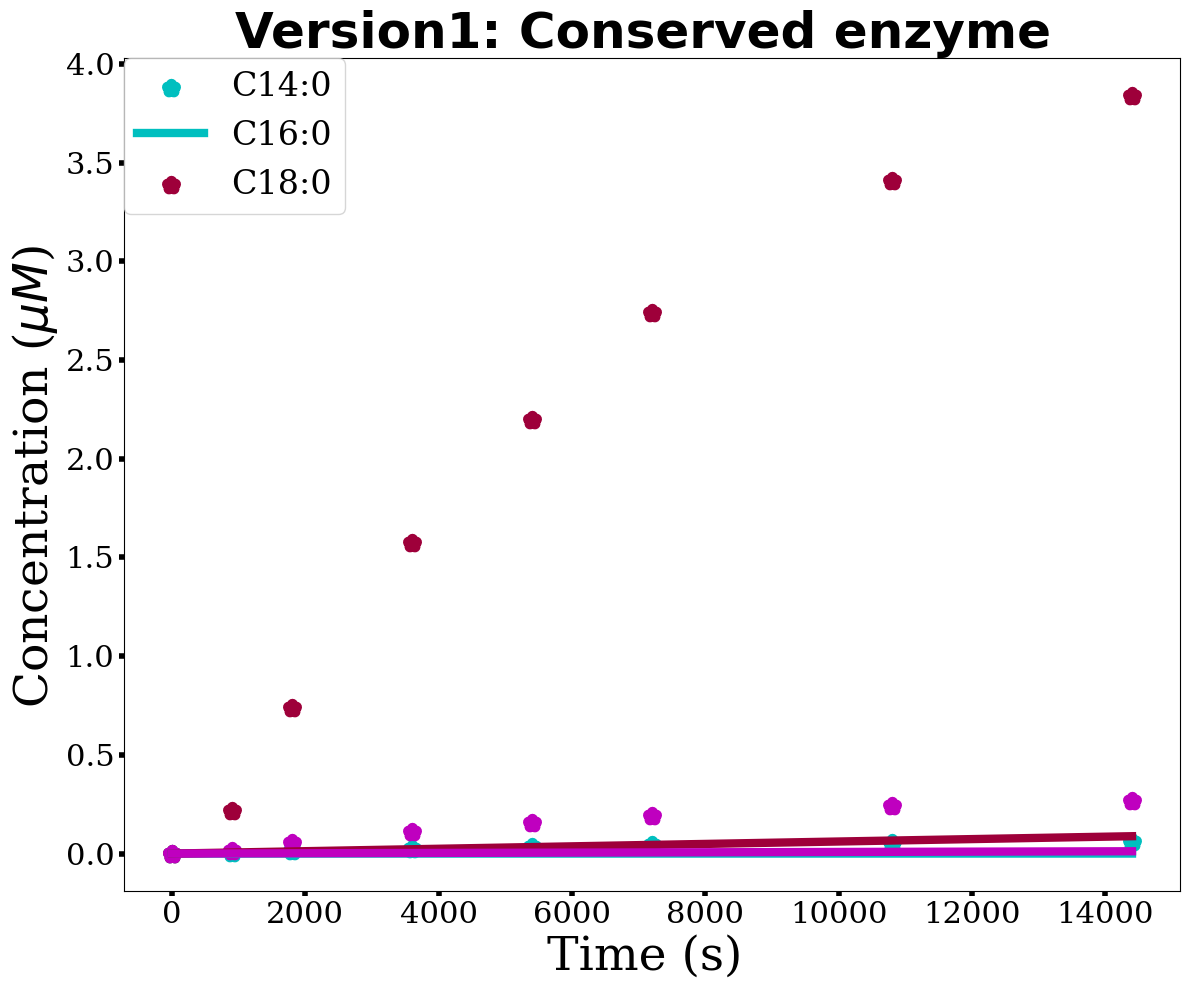

In [29]:
fig, ax = plt.subplots(figsize=(12, 10))

for i in range(1,4):
    ax.scatter(
        time_experiment, time_course_data_mean_numpy[:, i], color=color[i][0], marker="*",  linewidth=8
    )
    ax.plot(time_experiment, result_model[:, i-1], color=color[i][0], linewidth=6)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=34)
plt.ylabel("Concentration ($\mu M$) ", fontsize=34)
plt.title("Version1: Conserved enzyme ",  fontname="Times New Roman", size=36,fontweight="bold")
plt.xticks(size=22)
plt.yticks(size=22)
plt.tick_params(width=4)

# plt.yscale("log")
ax.legend(
    ["C14:0", "C16:0", "C18:0"],
    loc="best",
    #bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=24,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"fiting12.pdf", dpi=300, bbox_inches="tight")
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


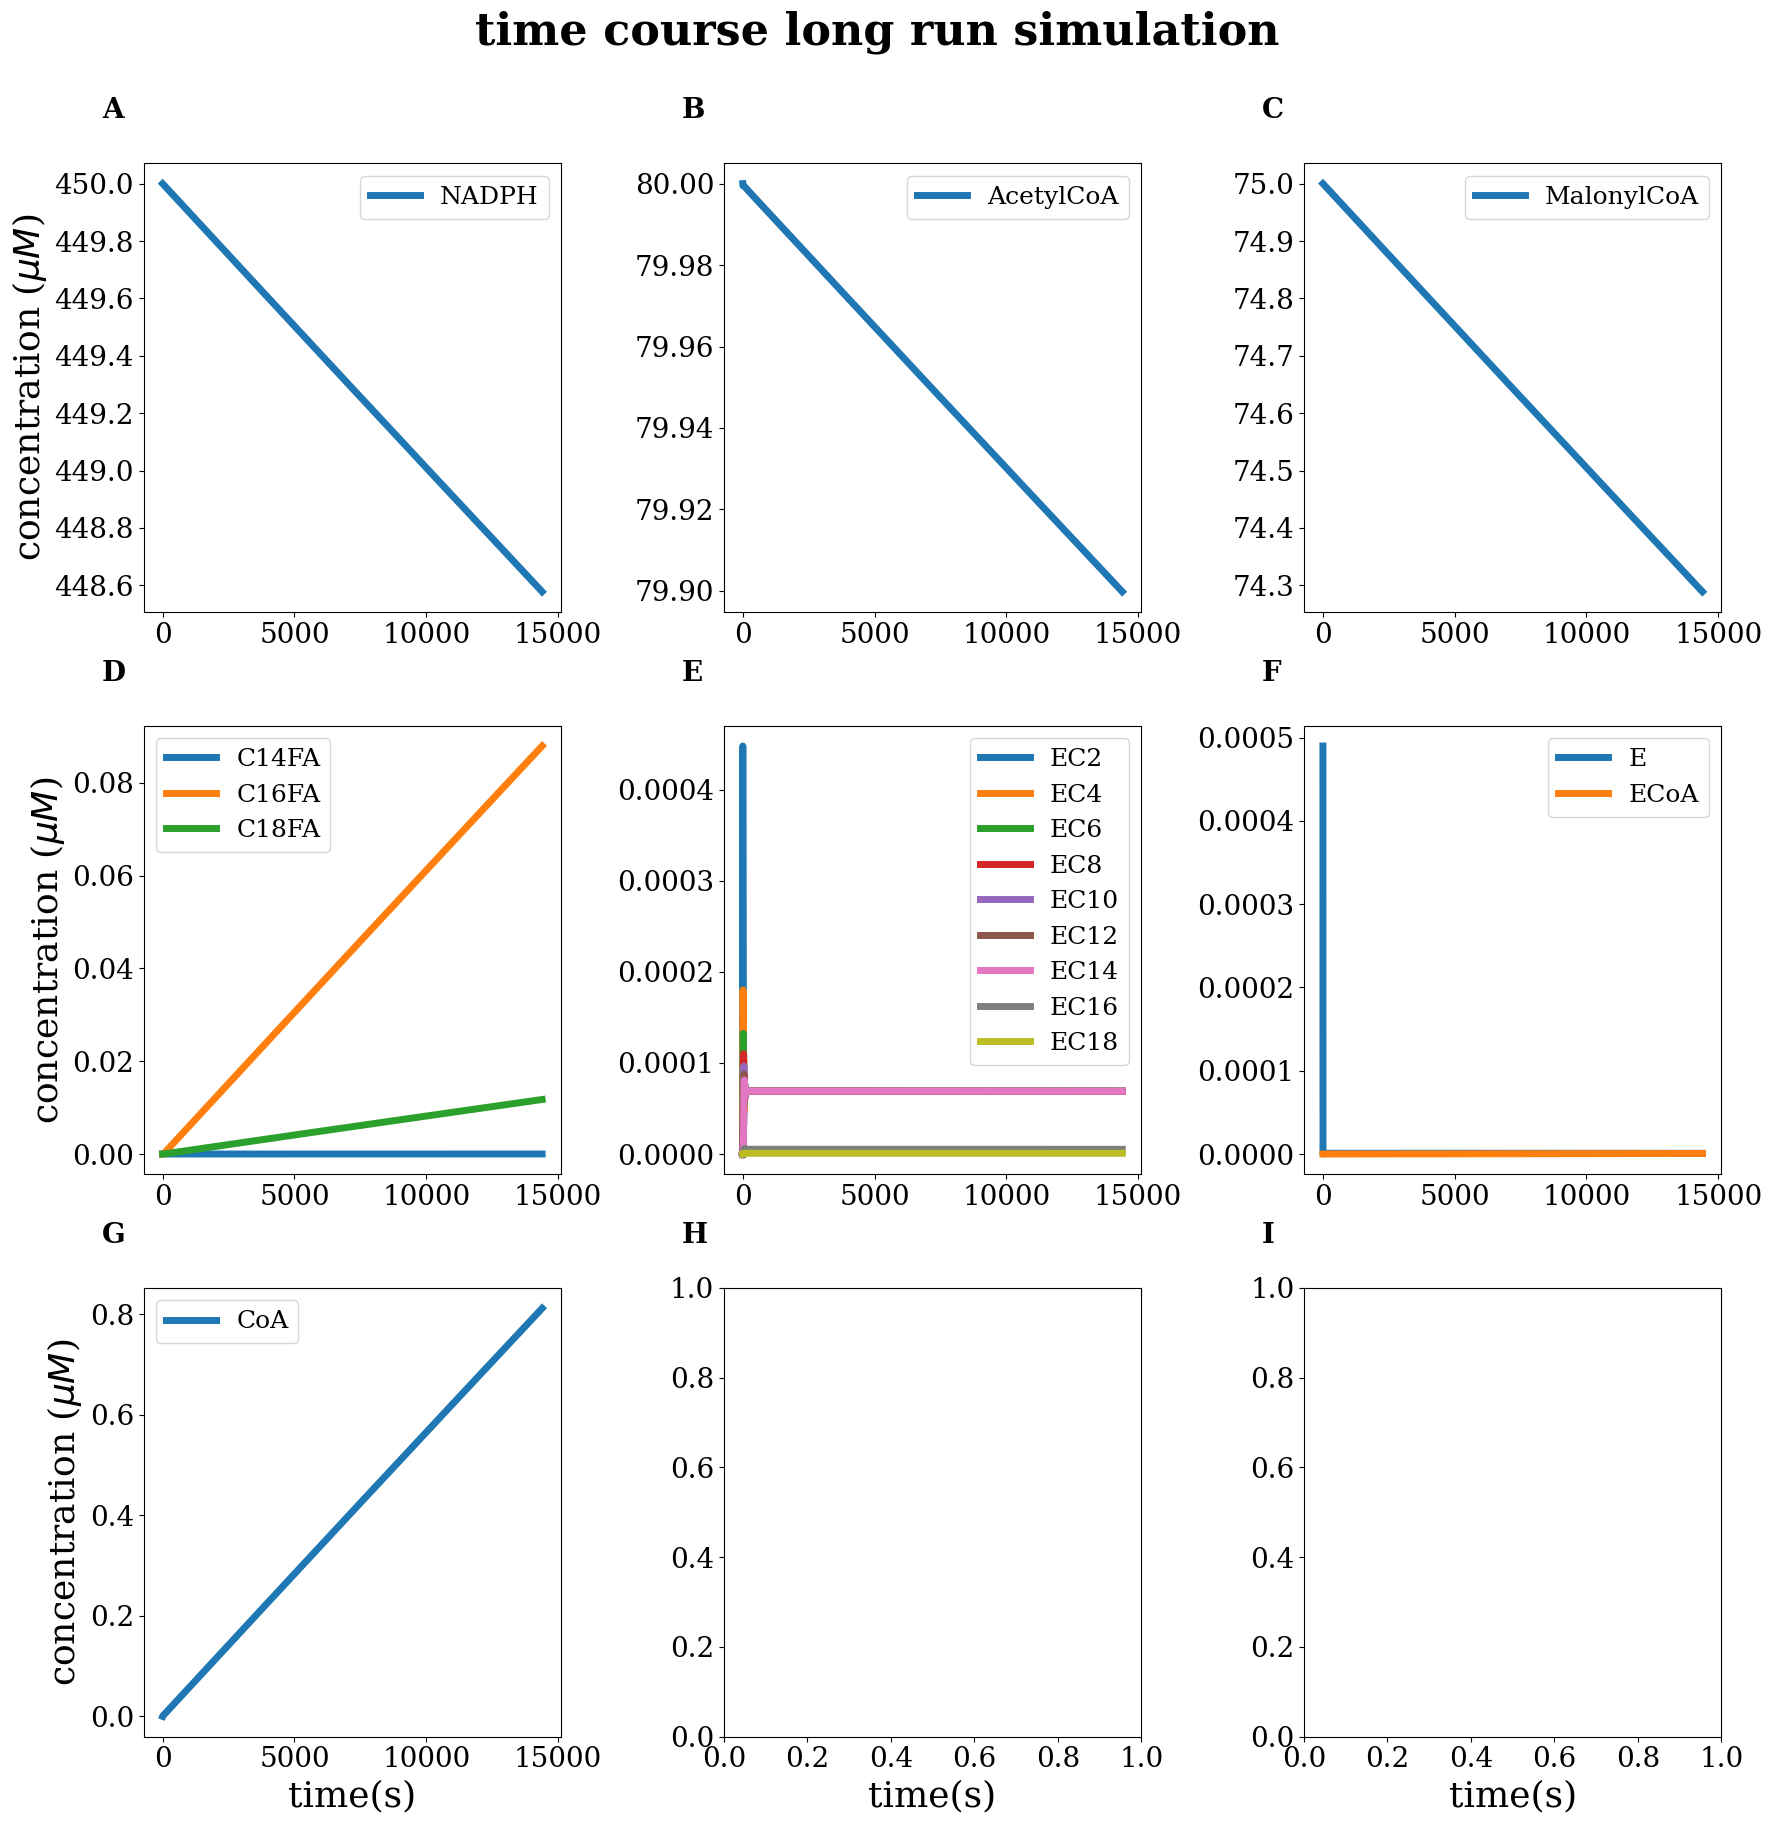

In [30]:
fig, axs = multi_plot_time_course(
    groups=time_course,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time1,
    ncp_list=ncp_list1,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="time course long run simulation",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
all_fatty_acids = total_fatty_acid(
    system, par, y0, max_time=time_simulations, ncp_list=ncp_list1
)

# axs[1, 2].plot(time_simulations, total_nefas1, "o")
# axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
# axs[1, 2].legend(["Data total NEFAs", "simulated"],)

plt.savefig(RESULTS_DIR /"initial.eps",  dpi=300)

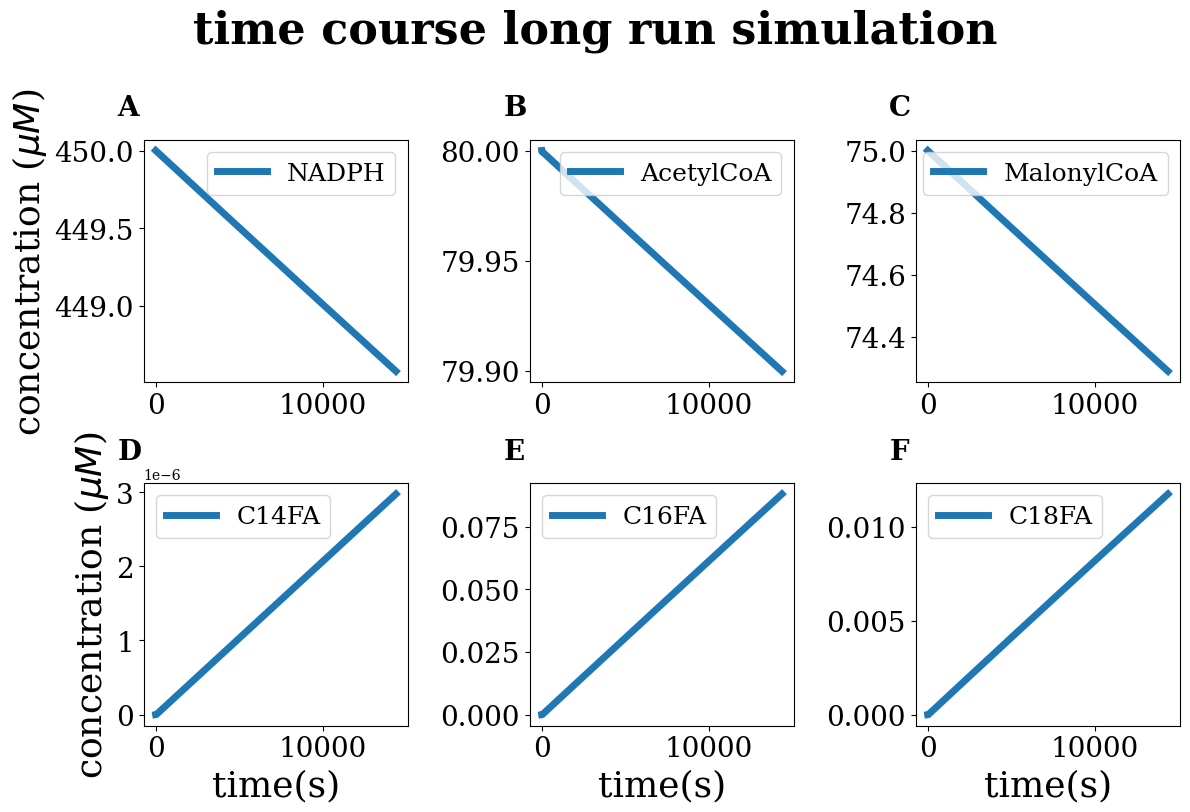

In [31]:
long_run = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["C14FA"],
    ["C16FA"],
    
    ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="time course long run simulation",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
# adding data to a particular graph
# all_fatty_acids= total_fatty_acid(system, par, y0, max_time = time_simulations, ncp_list = ncp_list2)

# axs[1, 2].plot(time_simulations, total_nefas1,  "o-", color=colors[i])
# axs[1, 2].plot(ncp_list2, all_fatty_acids, linewidth=4)
# axs[1, 2].legend(
#     [
#     "Data total NEFAs",
#     "simulated"
#     ],

# )
#plt.tick_params(axis="both", labelsize=14)
plt.savefig(RESULTS_DIR /"long_run.png")


### Plot time course individually 

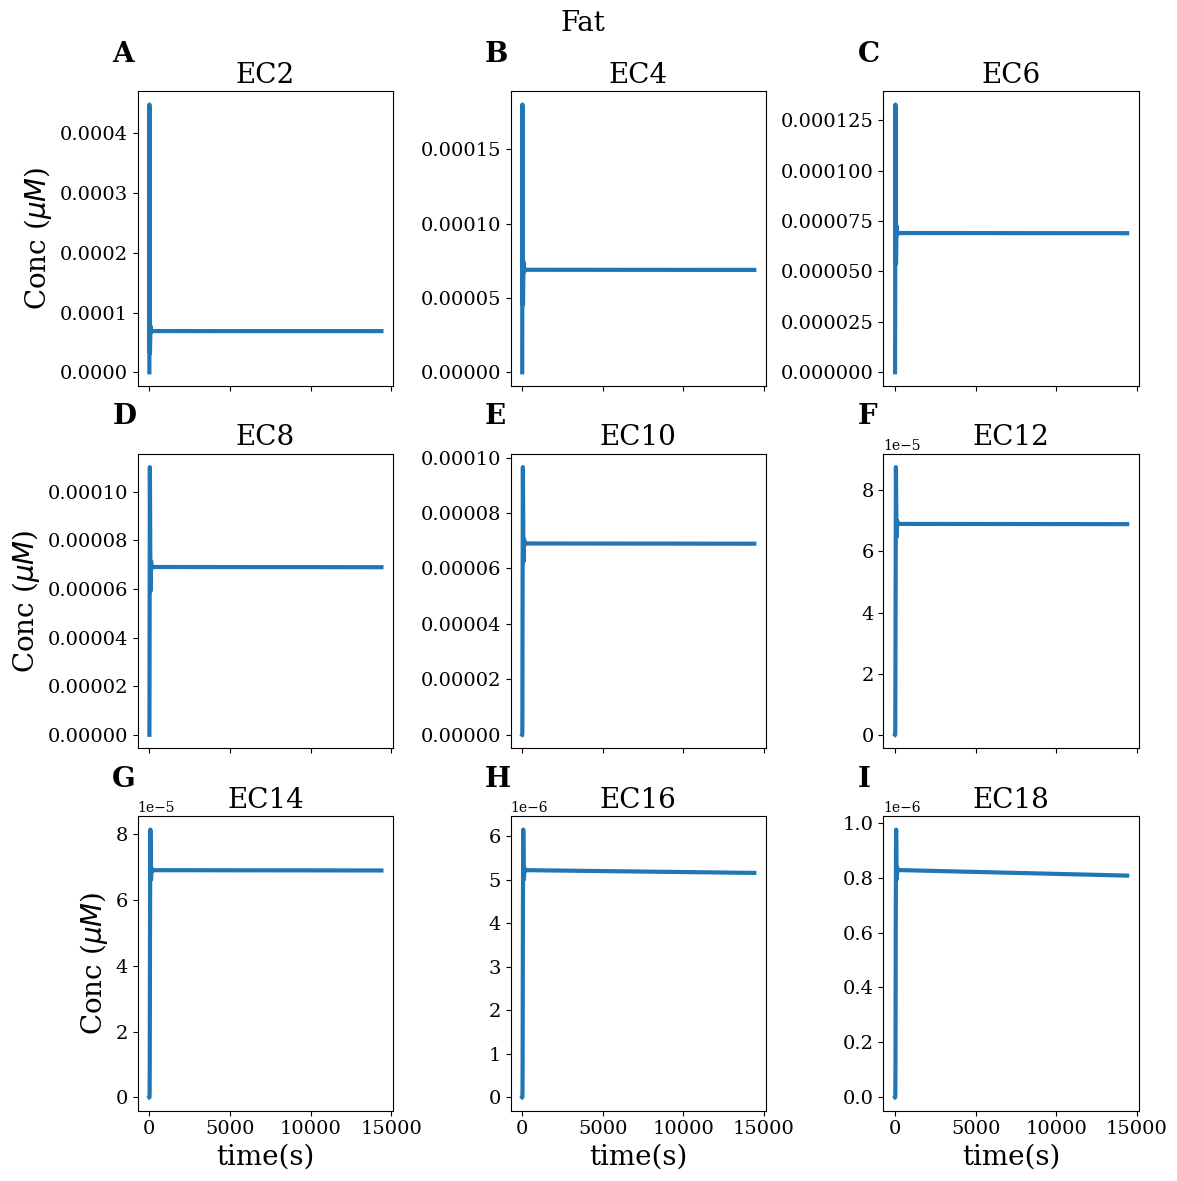

In [32]:
fat = [
    "EC2",
    "EC4",
    "EC6",
    "EC8",
    "EC10",
    "EC12",
    "EC14",
    "EC16",
    "EC18",
]
fig, axs = plot_individual_time_course(
    compounds_to_plot=fat,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par,
    compounds=compounds,
    ncols=3,
    resizer=4,
    sharey=False,
    title="Fat",
    xlabel="time(s)",
    ylabel="Conc ($\mu M$)",
)


In [33]:
par

{'beta': 0.1,
 'kappa': 3e-06,
 'delta': 4.7e-06,
 'kd6': 3e-06,
 'kd7': 1.18,
 'kd8': 1,
 'kf_CoA': 0.001,
 'kb_CoA': 0.001}

## Remarks
The above plots justify the quasi steady state that we considered fir the initial phase. Indeed one can see that all the enzyme species are almost 0 and all the enzyme is converted to EC16 (recalling the conservation relation and the total concentration of the enzyme is 0.306 $\mu M$)

# Fitting  for the three different types of NEFAs
Giving that we calculated the value of  some parameters from experimental data, notably the value of $K_{d7}$, $\delta$ under rapid binding considerations(Indeed the substrates are in excess). We now fit others parameters to initial phase data. 

# Interpolation to have  more points 

#

In [34]:
time_interp = np.linspace(
    0, time_simulations[-1], 7
)  # 50 data points between 0 and 120 secs.

time_interp

array([    0.,  2400.,  4800.,  7200.,  9600., 12000., 14400.])

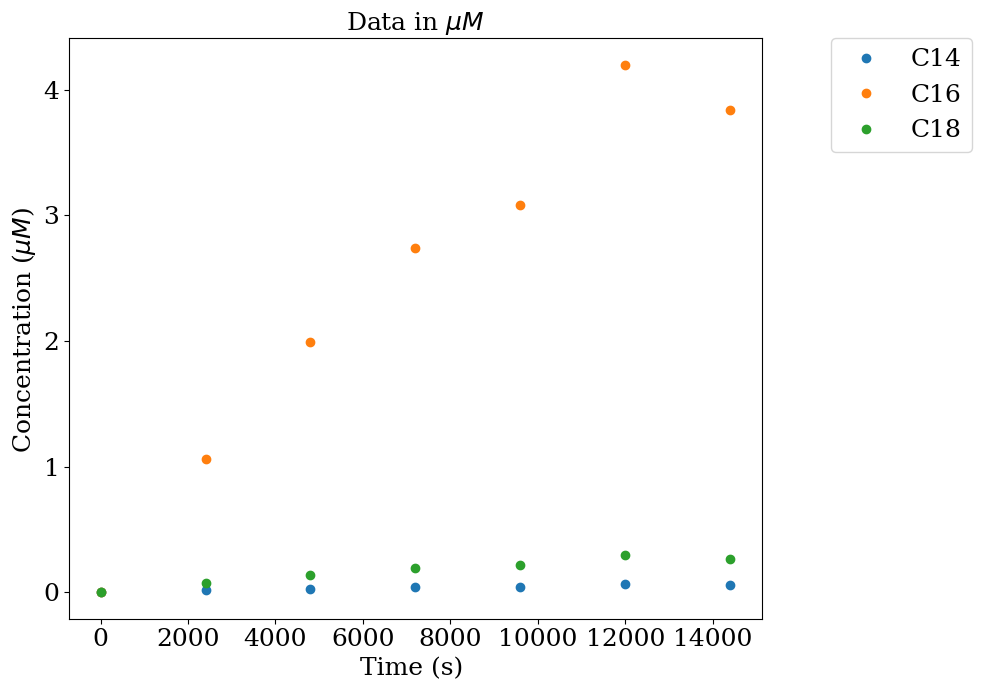

In [35]:
# use of lagrange interporlation to create more data point linearly

lagrange_interpolation_C14 = lagrange(time_simulations, data[:, 0])
lagrange_interpolation_C16 = lagrange(time_simulations, data[:, 1])
lagrange_interpolation_C18 = lagrange(time_simulations, data[:, 2])

C14_data = lagrange_interpolation_C14(time_interp)
C16_data = lagrange_interpolation_C16(time_interp)
C18_data = lagrange_interpolation_C18(time_interp)

data_to_fit = np.array([C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time_interp, data_to_fit, "o", linewidth=1)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concentration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()


# Warning !!!
If the interpolation is not needed for more data, comment the cell below 

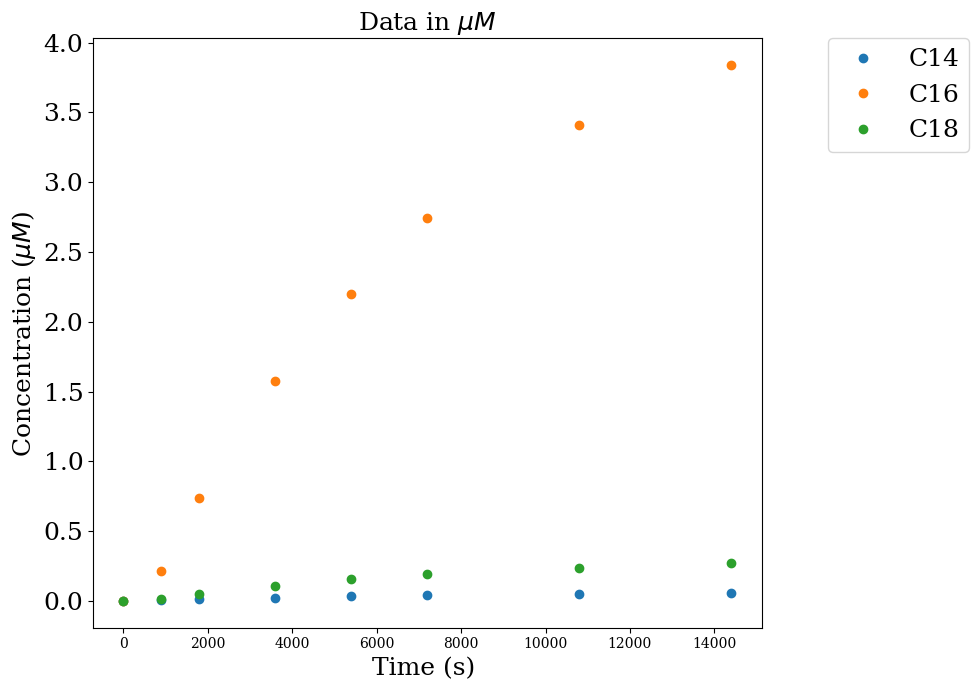

In [36]:
time_interp = time_experiment.copy()
# in the case where lagrange interpolation is not needed 

C14_data = data[:, 0]
C16_data = data[:, 1]
C18_data = data[:, 2]

data_to_fit = np.array([C14_data, C16_data, C18_data]).T


fig, ax = plt.subplots(figsize=(10, 7))
plt.plot(time_interp, data_to_fit, "o", linewidth=1)

plt.xlabel("Time (s) ", fontsize=18)
plt.ylabel("Concentration ($\mu M$) ", fontsize=18)
plt.title("Data in $\mu M$ ", fontsize=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")

In [37]:
data_to_fit

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.24801762e-03, 2.16534508e-01, 1.51574156e-02],
       [1.10570485e-02, 7.37136564e-01, 5.15995595e-02],
       [2.36191630e-02, 1.57461087e+00, 1.10222761e-01],
       [3.29559471e-02, 2.19706314e+00, 1.53794420e-01],
       [4.11044053e-02, 2.74029369e+00, 1.91820558e-01],
       [5.11204846e-02, 3.40803231e+00, 2.38562261e-01],
       [5.75711454e-02, 3.83807636e+00, 2.68665345e-01]])

In [38]:
# residual function to be passed to lmfit library
# The function *fatty_acid_of_interest* solves the system and only returns  C14, C16 and C18.

# This residual function can oly be used for fitting the inital phase


def residual(parameters, max_time, time, data):
    #y0[1] = parameters["y0_mal"].value
    # print(y0)
    #y0[11] = parameters["E"].value
    model = fatty_acid_of_interest(
        system, parameters, y0, max_time=max_time, ncp_list=time
    )
    res = (model - data).ravel()

    return res



In [39]:
par_to_fit = Parameters()
par_to_fit.add("beta", value=0.1, min= 0, )
par_to_fit.add("kappa", value=3e-1, min =0)
par_to_fit.add("delta", value=6.5e-5,min =0)
par_to_fit.add("kd6", value=0.01, min =0)
par_to_fit.add("kd7", value=0.032, vary =False)
par_to_fit.add("kd8", value=1, min =0)
par_to_fit.add("kf_CoA", value=1e-1, min =0, max =1)
par_to_fit.add("kb_CoA", value=1e-1, min =0, max =1)
par_to_fit.add("E", value=0.00049, vary = False)


   


In [40]:
result = minimize(
    residual,
    par_to_fit,
    args=(time_interp[-1], time_interp, data_to_fit),
    method="leastsquare",
)
final = data_to_fit + result.residual.reshape(data_to_fit.shape)
final.shape


(8, 3)

In [41]:
result 

In [42]:
best_par =  dict(result.params.valuesdict())
best_par 

{'beta': 1.5641863710725734,
 'kappa': 178.65085620179687,
 'delta': 1.3217524201802888e-06,
 'kd6': 70.04998681640899,
 'kd7': 0.032,
 'kd8': 18.530909178682624,
 'kf_CoA': 0.004975645584129551,
 'kb_CoA': 0.0718515507971959,
 'E': 0.00049}

In [43]:
# best_par["kappa"] =1e-3
# best_par["kd6"] = 3e-1

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


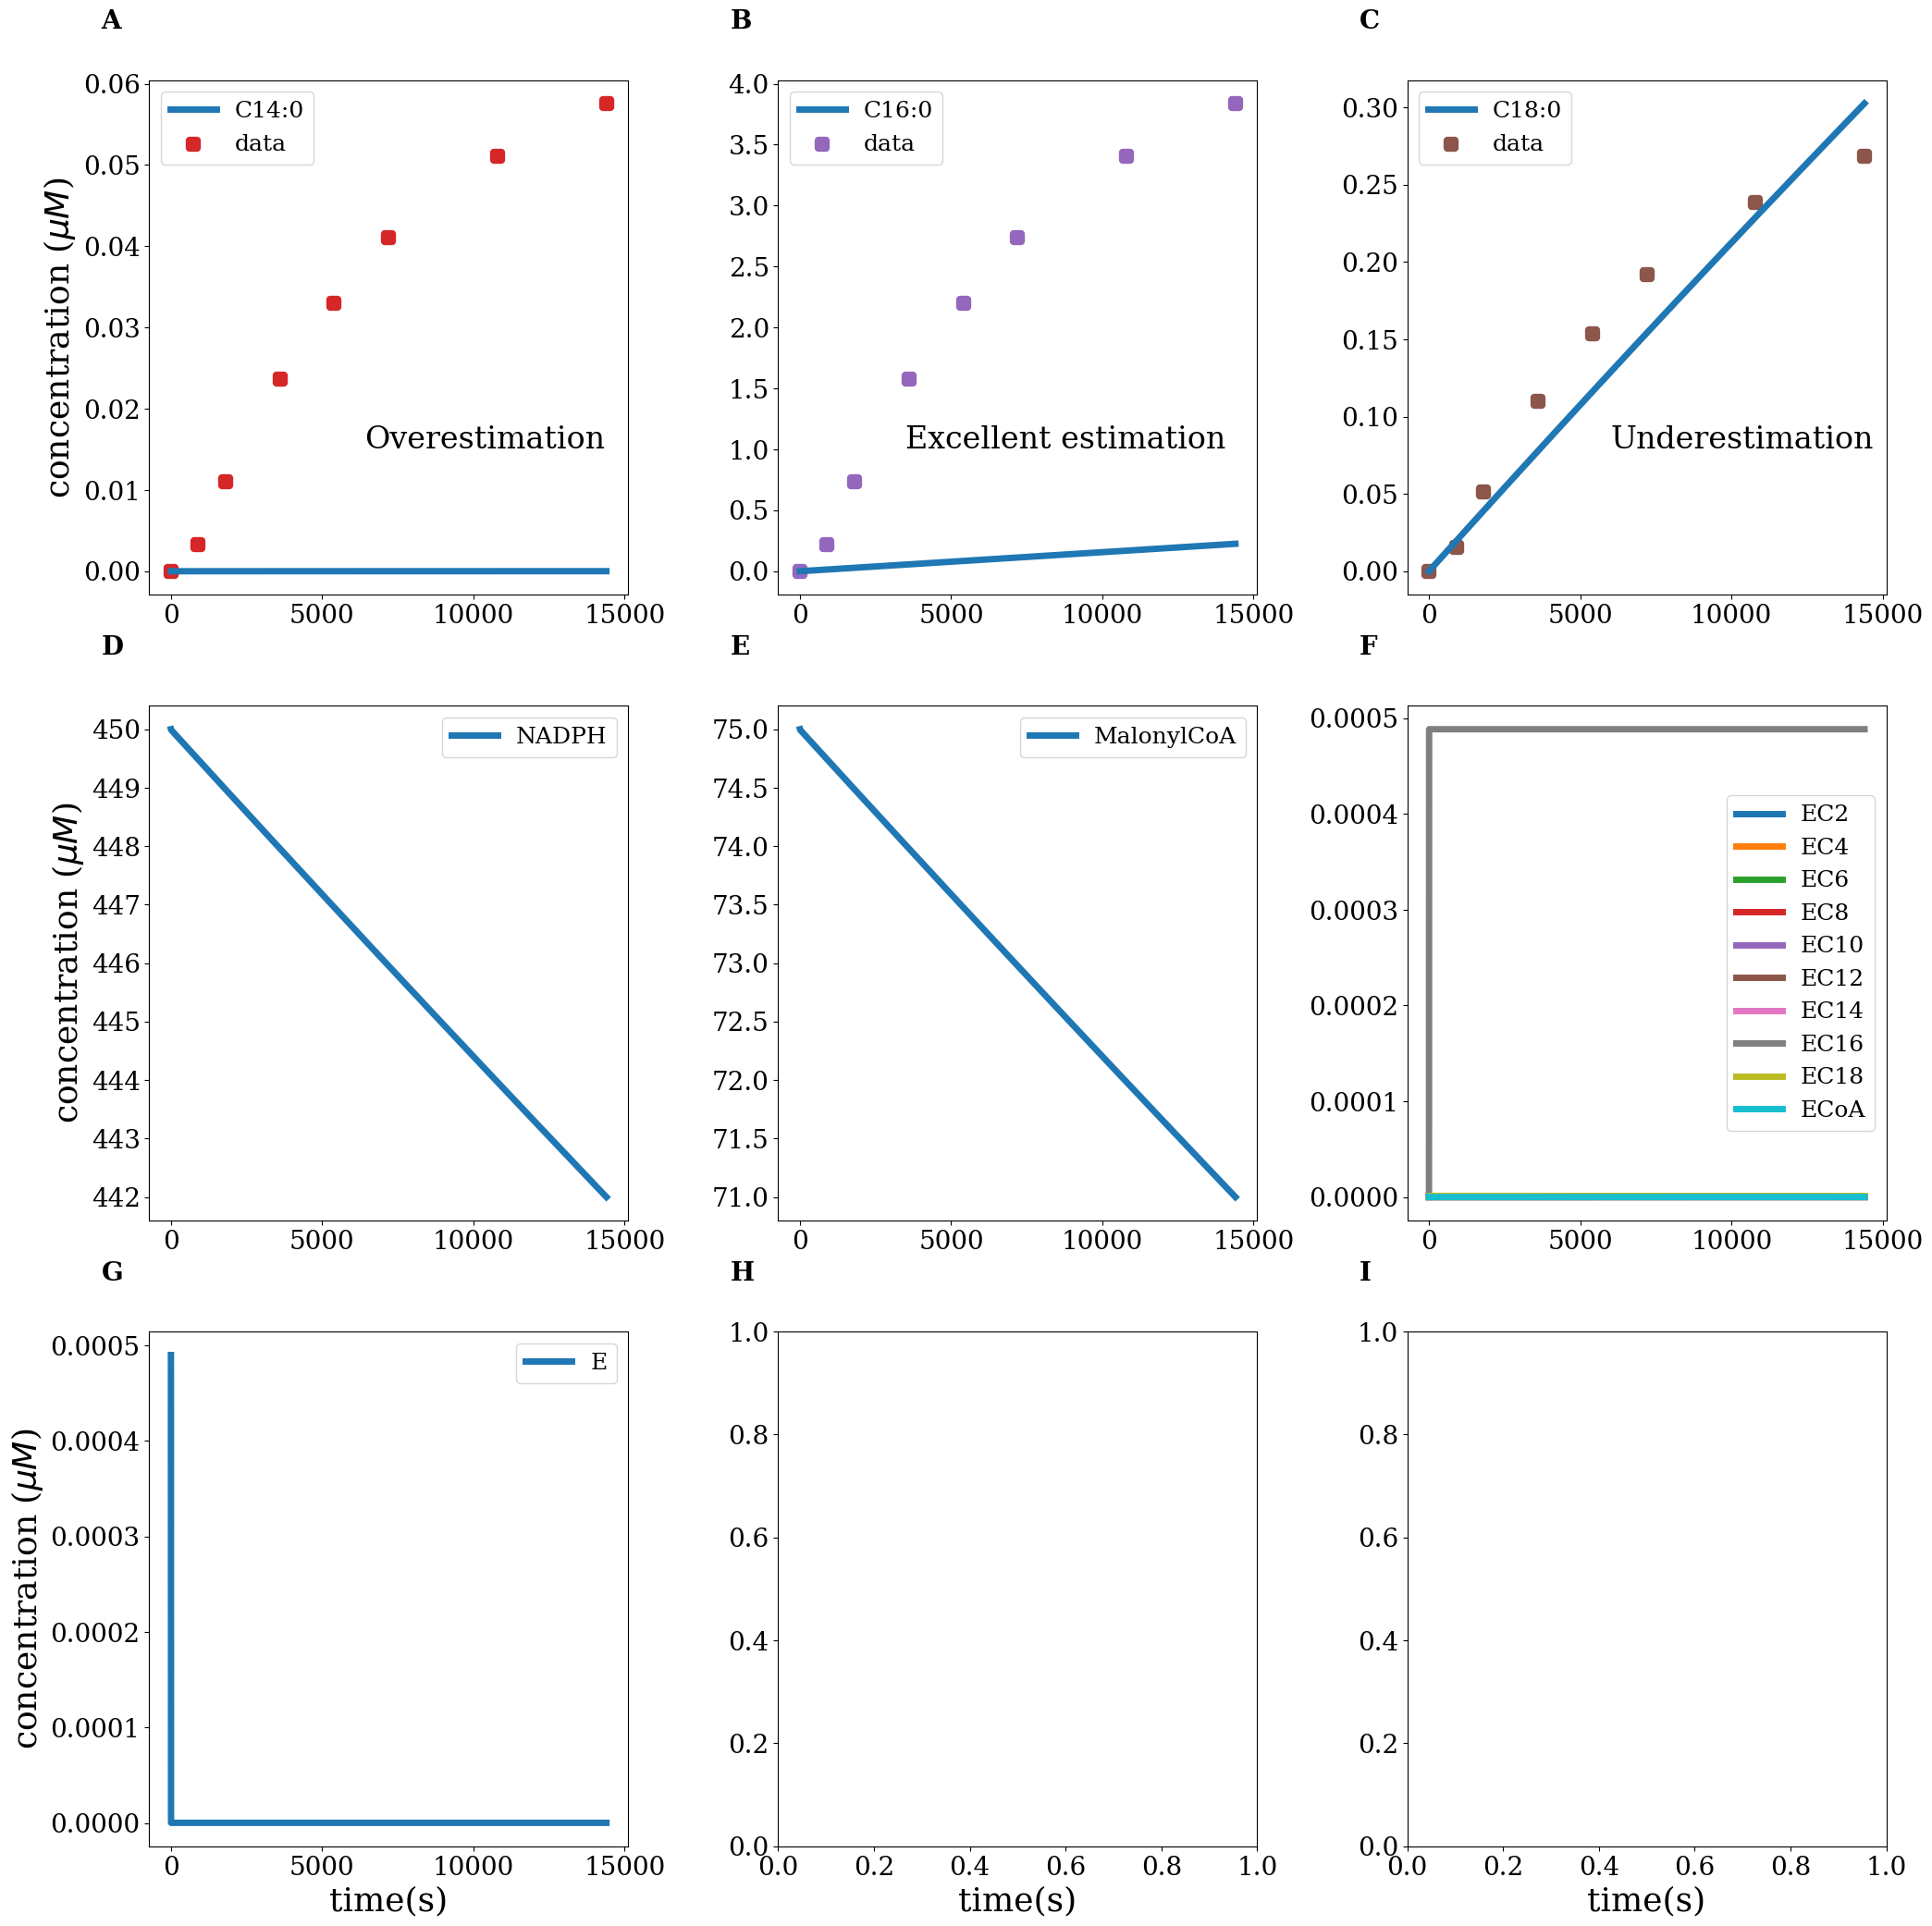

In [44]:
long_run = [
        ["C14FA"],
    ["C16FA"],
    ["C18FA"],
     ["NADPH"],
    # ["AcetylCoA"],
     ["MalonylCoA" ],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
     ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18", "ECoA"],
     ["E"]
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

# for i in list_best_parameters:
#     par_test =eval(i)
#     print((par_test))
#     rates(y0, par_test)
#     print()
fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=best_par ,
    compounds=compounds,
    ncols=3,
    resizer=7,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:, 0][0] = 0
data_to_fit[:, 1][0] = 0
data_to_fit[:, 2][0] = 0
for i in range(3):
    axs[0, i].scatter(
        time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
    )
    axs[0, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})
    
axs[0, 0].text(0.7, 0.3, 'Overestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 0].transAxes, fontsize =24)
axs[0, 1].text(0.6, 0.3, 'Excellent estimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 1].transAxes, fontsize =24)   
axs[0, 2].text(0.7, 0.3, 'Underestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 2].transAxes, fontsize =24)     
plt.savefig(RESULTS_DIR /"individual_fit_best3.eps", dpi=300, bbox_inches="tight")


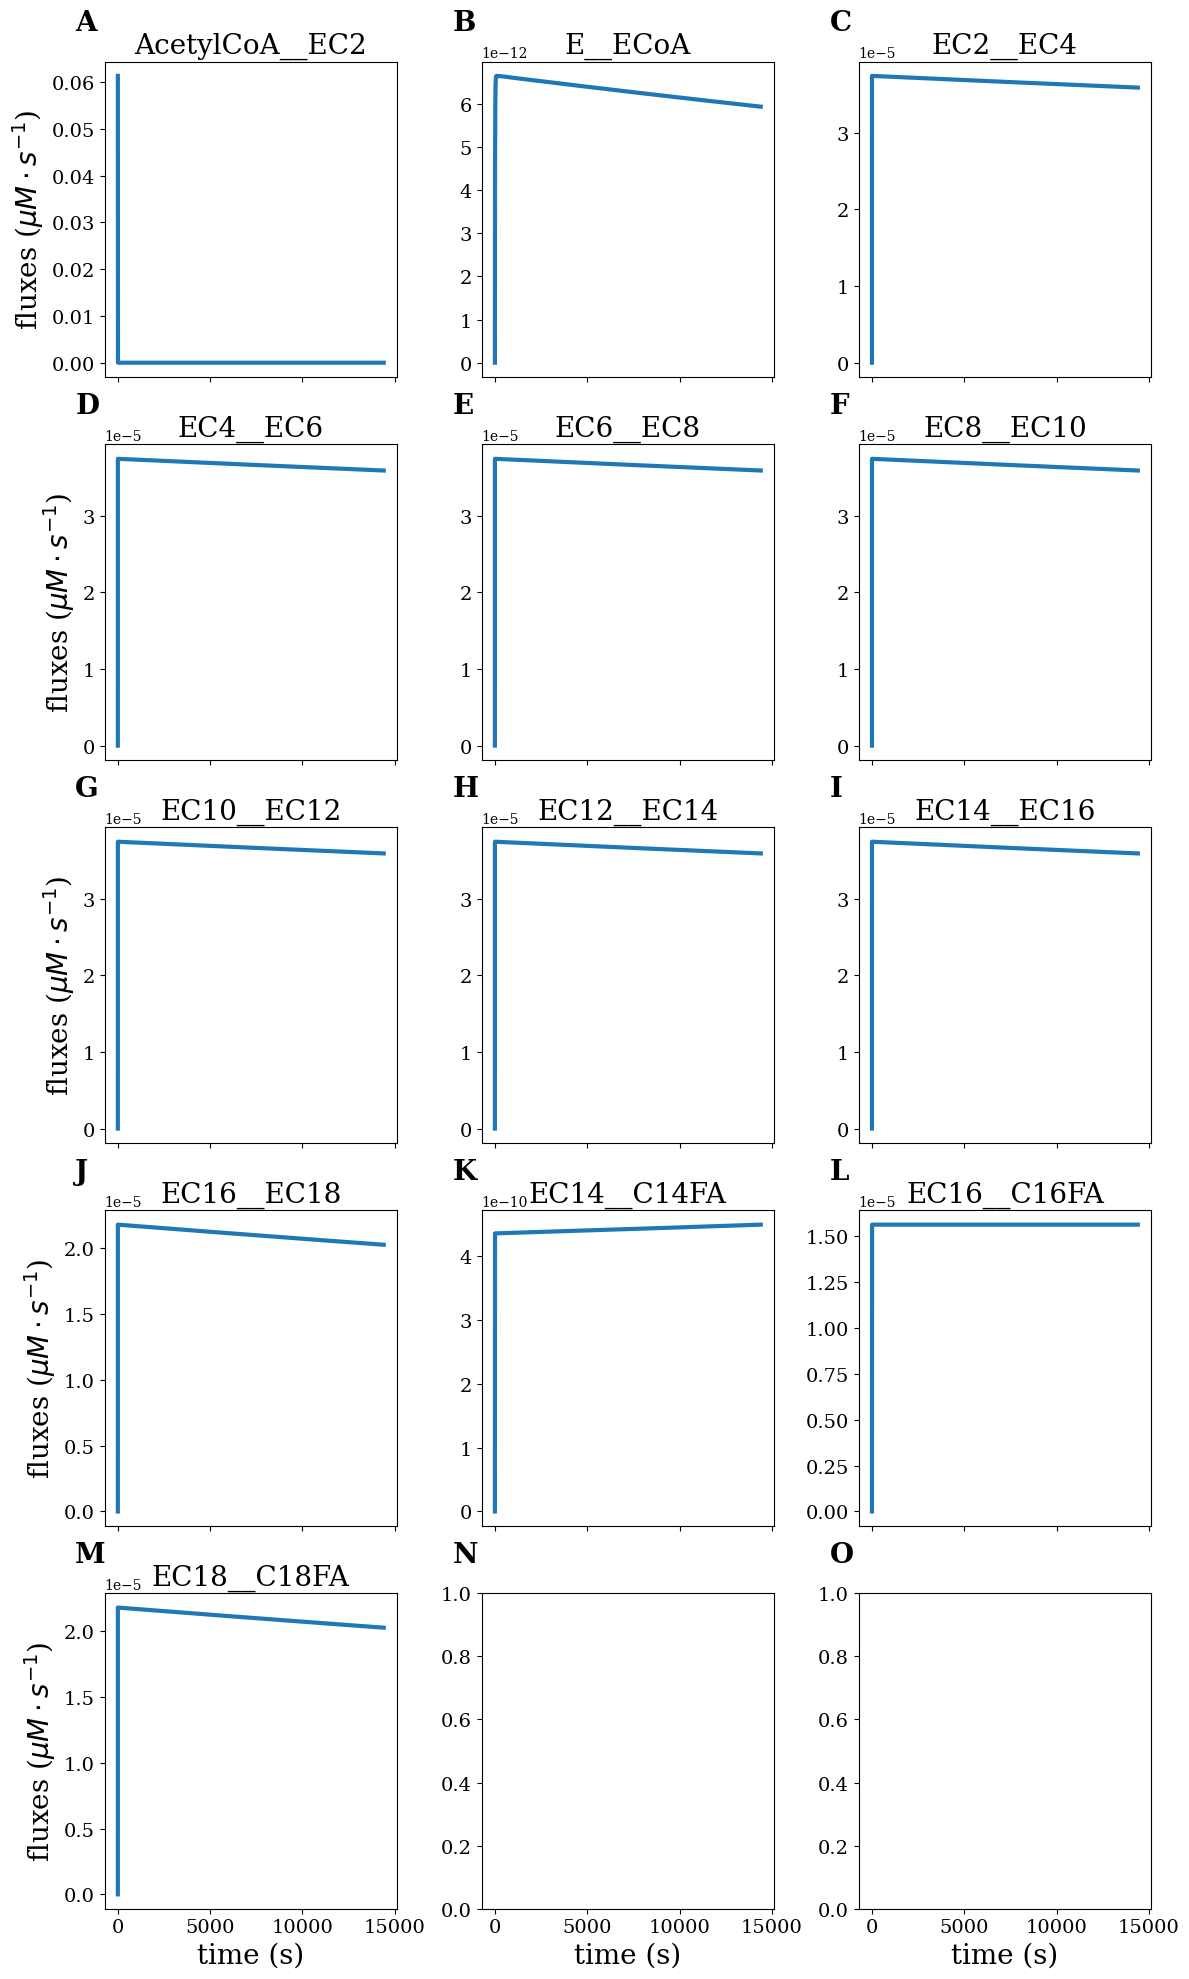

In [45]:
production_fluxes = ["AcetylCoA__EC2","E__ECoA",
    "EC2__EC4",
    "EC4__EC6",
    "EC6__EC8",
    "EC8__EC10",
     "EC10__EC12",
    "EC12__EC14",
    "EC14__EC16",
    "EC16__EC18",
    "EC14__C14FA",
        "EC16__C16FA",
        "EC18__C18FA",
    

]


fig, axs = plot_fluxes_individually(
    list_fluxes=production_fluxes,
    model=system,
    rates=rates,
    y0=y0,
    par=best_par,
    max_time=max_time2,
    ncp_list=ncp_list2,
    ncols=3,
    resizer=4,
    sharey=False,
    #         title: str = None,
    xlabel="time (s)",
    ylabel="fluxes ($\mu M \cdot s^{-1}$)",
)

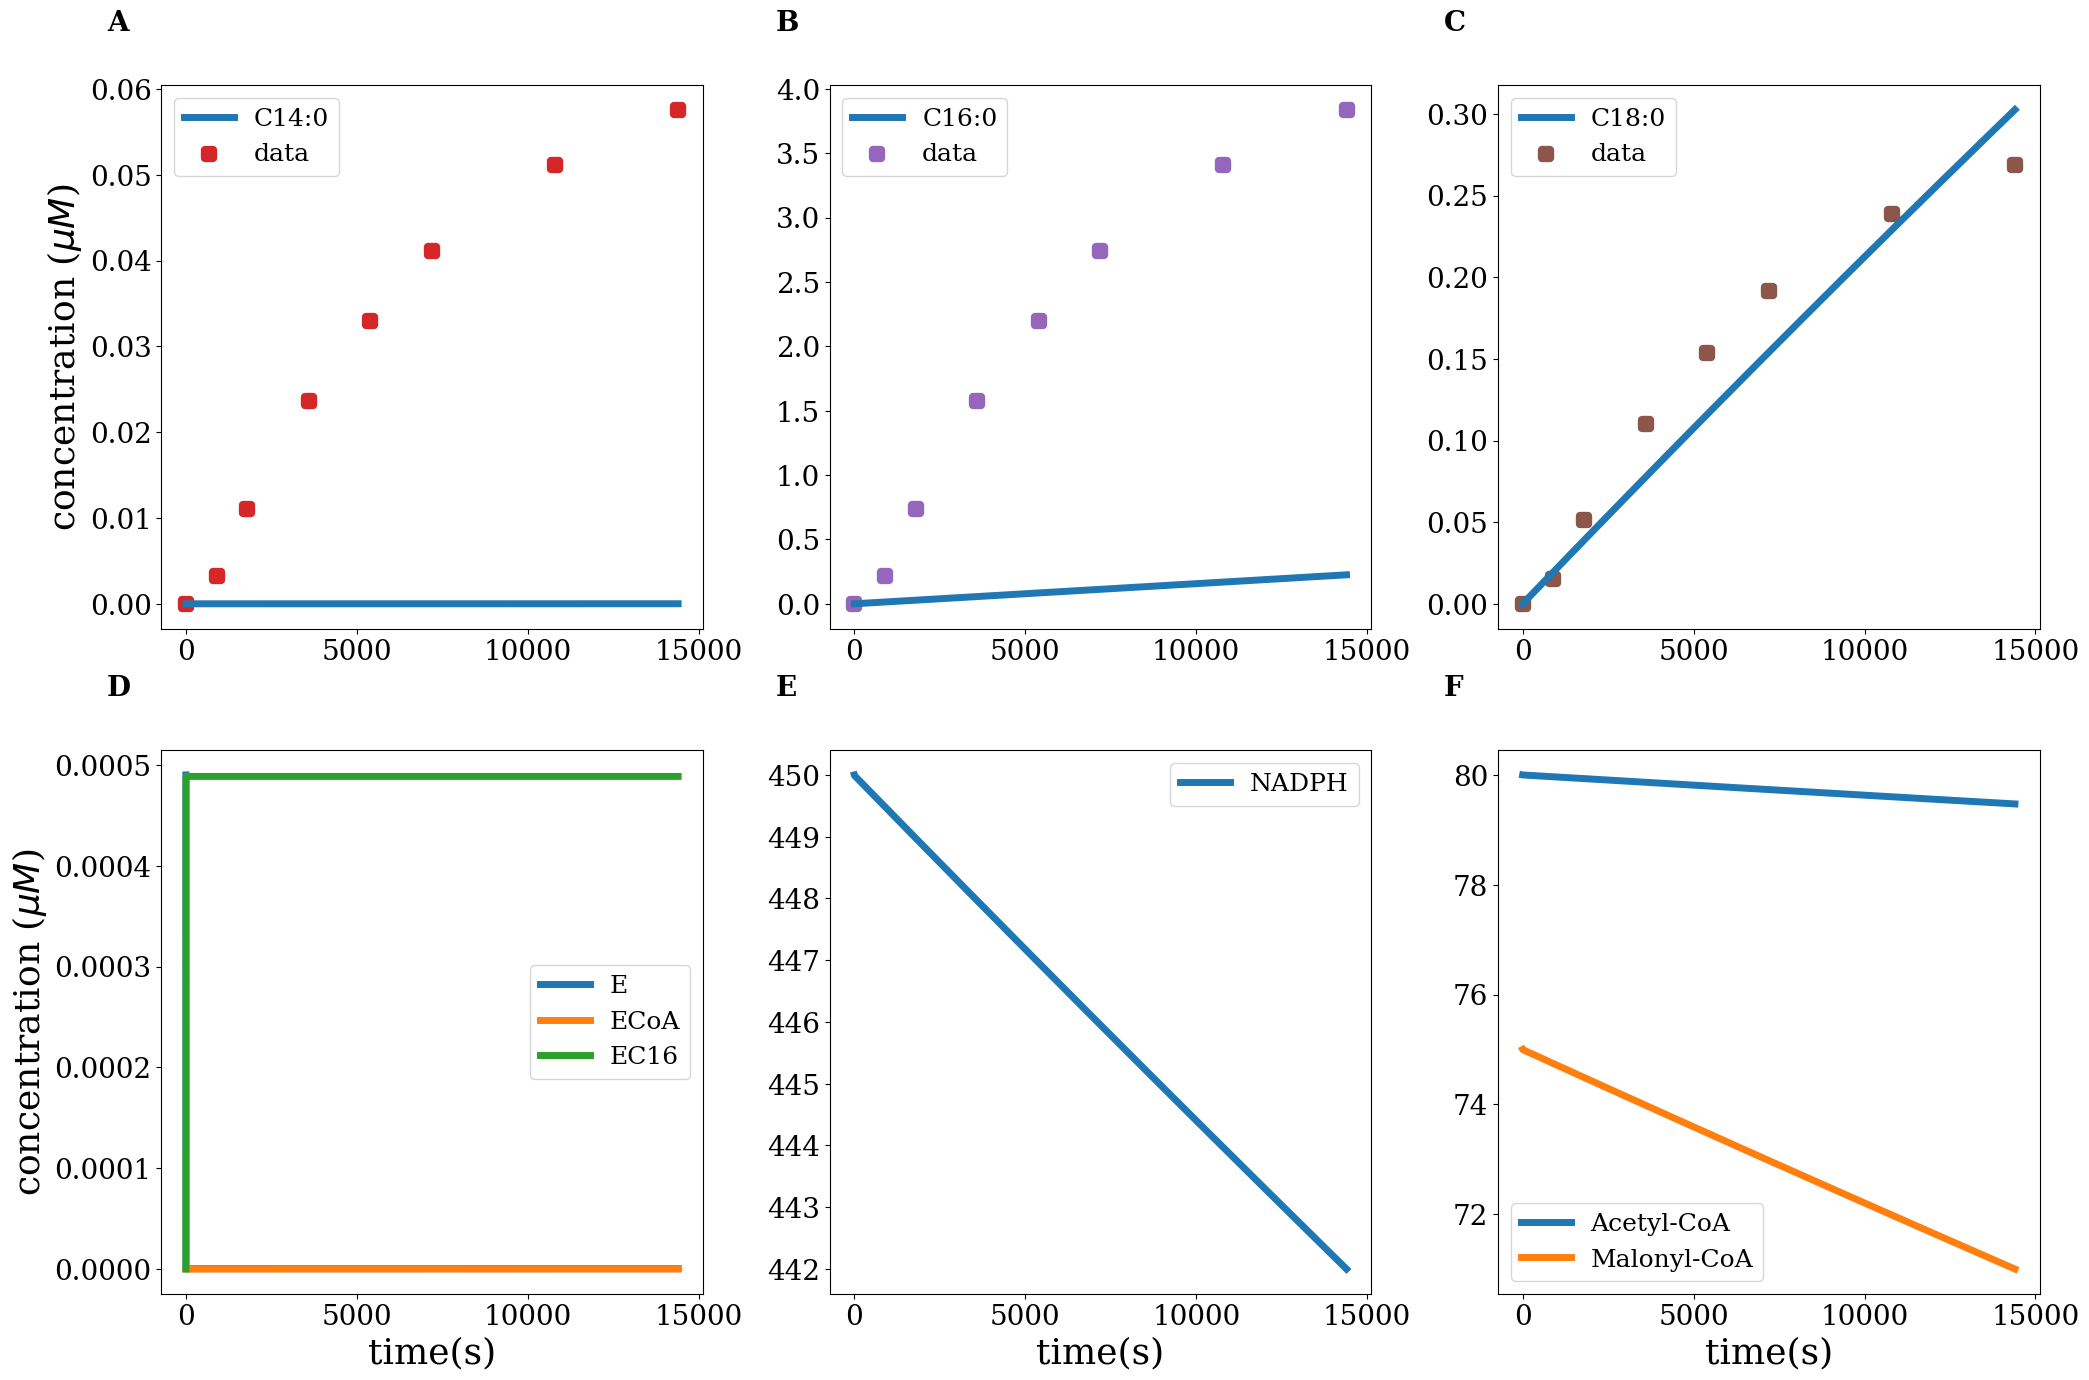

In [46]:
long_run1 = [
        ["C14FA"],
    ["C16FA"],
    ["C18FA"],
     ["E", "ECoA", "EC16"],
     ["NADPH"],
     #["E", "ECoA", "EC16"],
     
    #["NADPH"],
     ["AcetylCoA",
    "MalonylCoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

# for i in list_best_parameters:
#     par_test =eval(i)
#     print((par_test))
#     rates(y0, par_test)
#     print()
fig, axs = multi_plot_time_course(
    groups=long_run1,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=best_par ,
    compounds=compounds,
    ncols=3,
    resizer=7,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:, 0][0] = 0
data_to_fit[:, 1][0] = 0
data_to_fit[:, 2][0] = 0
axs[1, 2].legend(["Acetyl-CoA", "Malonyl-CoA"], prop={"size": 18})
for i in range(3):
    axs[0, i].scatter(
        time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
    )
    axs[0, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})
    
# axs[0, 0].text(0.7, 0.3, 'Overestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 0].transAxes, fontsize =24)
# axs[0, 1].text(0.6, 0.3, 'Excellent estimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 1].transAxes, fontsize =24)   
# axs[0, 2].text(0.7, 0.3, 'Underestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 2].transAxes, fontsize =24)     
plt.savefig("individual_fit_best31.pdf", dpi=300, bbox_inches="tight")


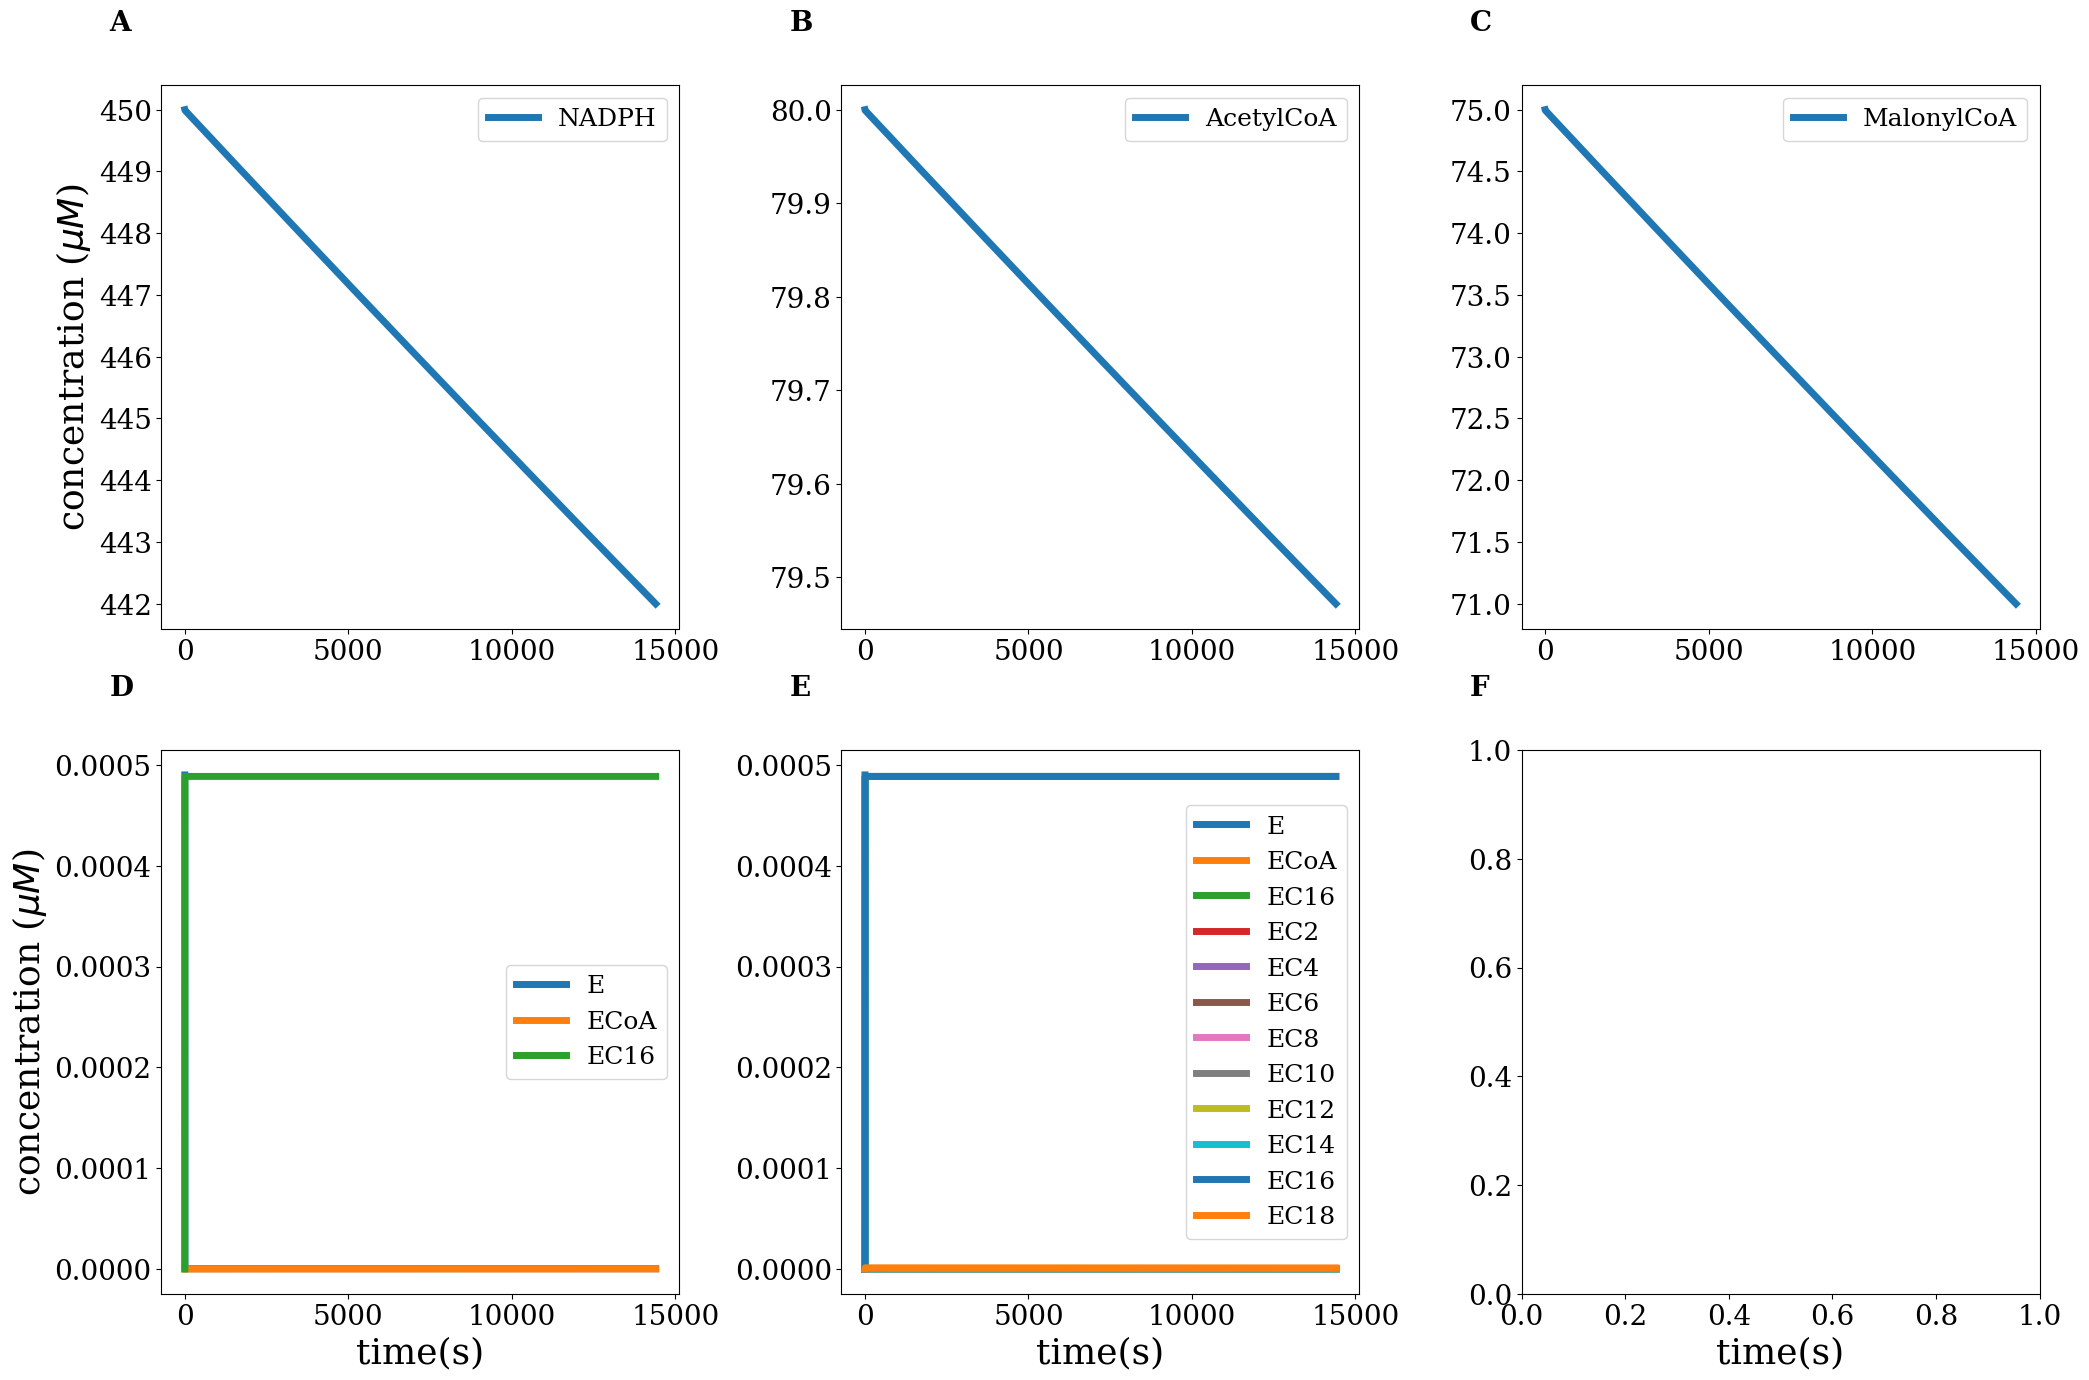

In [47]:
long_run2 = [
      
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    # ["C14FA"],
    # ["C16FA"],
    # ["C18FA"],
     #["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC18"],
     ["E", "ECoA", "EC16"], 
     ["E", "ECoA", "EC16", "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"]
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

# for i in list_best_parameters:
#     par_test =eval(i)
#     print((par_test))
#     rates(y0, par_test)
#     print()
fig, axs = multi_plot_time_course(
    groups=long_run2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=best_par ,
    compounds=compounds,
    ncols=3,
    resizer=7,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:, 0][0] = 0
data_to_fit[:, 1][0] = 0
data_to_fit[:, 2][0] = 0
# for i in range(3):
#     axs[0, i].scatter(
#         time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
#     )
#     axs[0, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})
    
# axs[0, 0].text(0.7, 0.3, 'Overestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 0].transAxes, fontsize =24)
# axs[0, 1].text(0.6, 0.3, 'Excellent estimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 1].transAxes, fontsize =24)   
# axs[0, 2].text(0.7, 0.3, 'Underestimation', horizontalalignment='center', verticalalignment='center', transform=axs[0, 2].transAxes, fontsize =24)     
#plt.savefig("individual_fit_best3.eps", dpi=300, bbox_inches="tight")


In [128]:
import random as rd
import json

list_par = [
    "beta",
    "gamma",
    "kappa",
    "delta",
    # "kd1",
    # "kd2",
    # "kd3",
    # "kd4",
    # "kd5",
    "kd6",
    "kd7",
    "kd8",
    "kf_CoA",
    "kb_CoA",
]
biggest_value = 50
upper_bound1 = [j/biggest_value for j in range(1, biggest_value)]
upper_bound2 = [j for j in range(1, biggest_value)]
upper_bound =upper_bound1+ upper_bound2

json_dict = {}
# the number of time to sample the parameters from a particular distribution
number_of_draw = 100
# Create a file  in which the paramters value and the goodness of the fit will be stored
json_dict = {}

dict_chi_square = {}  # the dictionnary where the chi square values are stored
list_index_failure =[]
for i in range(number_of_draw):
    try:
        

        beta = rd.uniform(0, rd.choice(upper_bound))
        kappa = rd.uniform(0, rd.choice(upper_bound))
        delta = 1.17e-06#rd.uniform(0, rd.choice(upper_bound))
        # kd1 = rd.uniform(0, 1e-5)
        # kd2 = rd.uniform(0, 1e-5)
        # kd3 = rd.uniform(0, 1e-5)
        # kd4 = rd.uniform(0, 1e-5)
        # kd5 = rd.uniform(0, 1e-4)
        kd6 = rd.uniform(0, rd.choice(upper_bound))
        kd7 = 0.03 #rd.uniform(1, rd.choice(upper_bound))
        kd8 =90 #rd.uniform(0, rd.choice(upper_bound))
        kf_CoA = rd.uniform(0, rd.choice(upper_bound))
        kb_CoA = 0.00024#rd.uniform(0, rd.choice(upper_bound))

        list_values = [
            beta,
            kappa,
            delta,
            # kd1,
            # kd2,
            # kd3,
            # kd4,
            # kd5,
            kd6,
            kd7,
            kd8,
            kf_CoA,
            kb_CoA,
        ]

        initial_parameters = dict(zip(list_par, list_values))
        initial_parameters = repr(initial_parameters)
        json_dict[f"initial_val_{i}"] = initial_parameters
        ##########################################################
        par_fit = Parameters()
        par_fit.add("beta", value=beta, min=0)
        par_fit.add("kappa", value=kappa, min =0)
        par_fit.add("delta", value=delta, min =0)
        # par_fit.add("kd1", value=kd1,vary =False)
        # par_fit.add("kd2", value=kd2,vary =False)
        # par_fit.add("kd3", value=kd3,vary =False)
        # par_fit.add("kd4", value=kd4,vary =False)
        # par_fit.add("kd5", value=kd5,vary =False)
        par_fit.add("kd6", value=kd6, min=0)
        par_fit.add("kd7",  value=kd7, min =0)
        par_fit.add("kd8", value=kd8, vary= False)
        par_fit.add("kf_CoA", value=kf_CoA,min = 0)
        par_fit.add("kb_CoA", value=kb_CoA, vary= False)

        ########################################################

        resulta = minimize(
            residual,
            par_fit,
            args=(time_interp[-1], time_interp, data_to_fit),
            method="leastsquare",
        )
        par_fit_result = dict(resulta.params.valuesdict())
        chi_fit_result = resulta.chisqr
        par_fit_result = repr(par_fit_result)
        chi_fit_result = repr(chi_fit_result)
        json_dict[f"par_fit_{i}"] = par_fit_result
        json_dict[f"chi_square_{i}"] = float(chi_fit_result)
        
    except  CVodeError :
        list_index_failure.append(i)
        

    #print(json_dict)

with open("parameters_scan.json", "w") as file:
    json.dump(json_dict, file)

# with open("parameters_scan.json", "r") as file:
#     print(json.load(file))



In [134]:
with open("parameters_scan.json", "r") as file:
    output_dictionnary  = json.load(file)
    
    
list_chi_square = []
list_succesful_index = []

for i in range(number_of_draw):
    if i not in list_index_failure:
        #print(f"The the sampling {i} is succesful")
        list_chi_square.append(output_dictionnary[f"chi_square_{i}"])
        list_succesful_index.append(i)

    else:
        index = 1e10
        #print(f"The the sampling {i} has failed: ", index)

min_chi_square = min(list_chi_square)
list_min_index = []
list_min_chi_square = []
list_best_parameters = []
for l in list_succesful_index:
    if output_dictionnary[f"chi_square_{l}"] == min_chi_square:
        list_min_index.append(l)
        list_min_chi_square.append(output_dictionnary[f"chi_square_{l}"])
        list_best_parameters.append(output_dictionnary[f"par_fit_{l}"])
        


print(
    "\n\n \n\n \n\n",
    list_min_index,
    "\n\n \n\n \n\n",
    list_min_chi_square,
    "\n\n \n\n \n\n",
    list_best_parameters,
)
par_to_use_for_trial = eval( list_best_parameters[0])
par_to_use_for_trial



 

 

 [66] 

 

 

 [0.09460106514500052] 

 

 

 ["{'beta': 607.029678470759, 'kappa': 6.454916504356338, 'delta': 2.549993818545815e-06, 'kd6': 2440.386872806438, 'kd7': 0.9907747233206914, 'kd8': 90, 'kf_CoA': 0.6792225021464224, 'kb_CoA': 0.00024}"]


{'beta': 607.029678470759,
 'kappa': 6.454916504356338,
 'delta': 2.549993818545815e-06,
 'kd6': 2440.386872806438,
 'kd7': 0.9907747233206914,
 'kd8': 90,
 'kf_CoA': 0.6792225021464224,
 'kb_CoA': 0.00024}

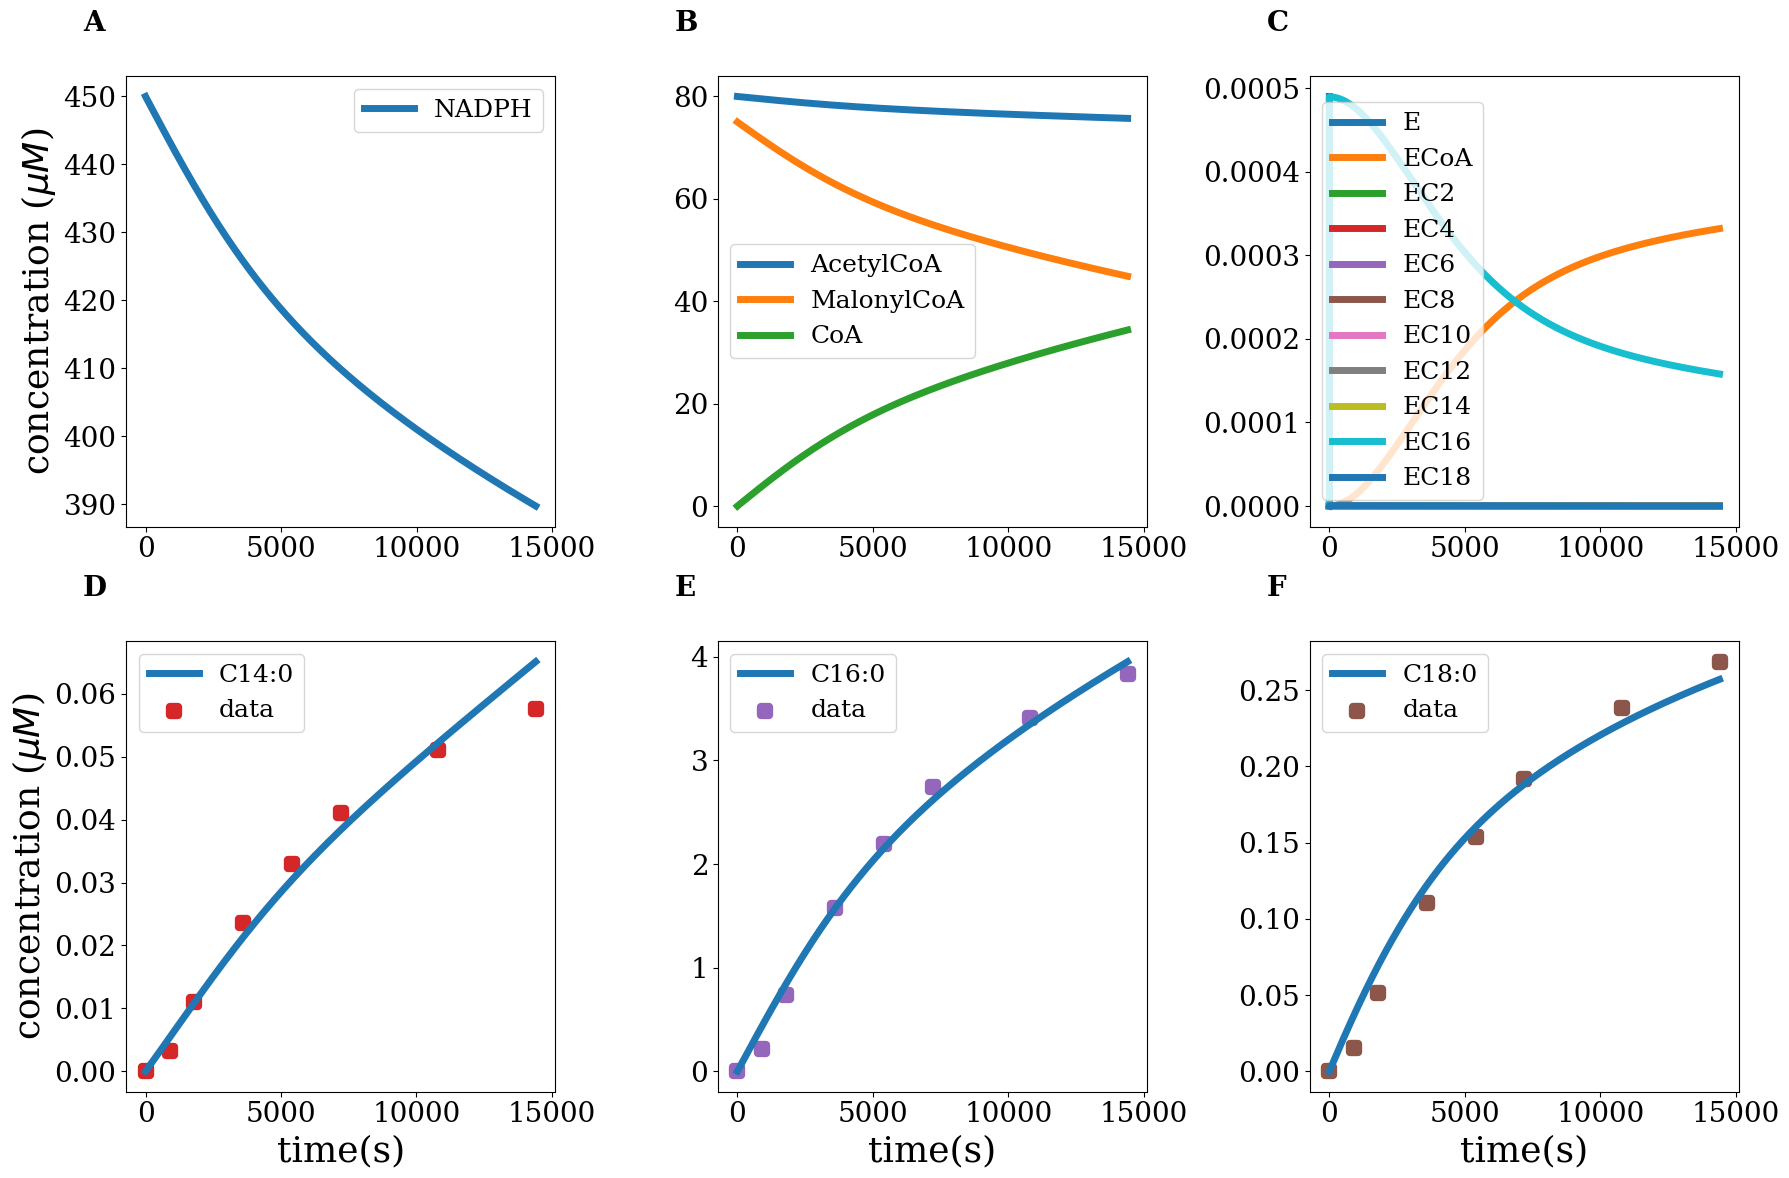

In [139]:
long_run = [
    ["NADPH"],
    ["AcetylCoA","MalonylCoA", "CoA"],
    ["E","ECoA","EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
   
  
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

# for i in list_best_parameters:
#     par_test =eval(i)
#     print((par_test))
#     rates(y0, par_test)
#     print()
fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par =par_to_use_for_trial,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:, 0][0] = 0
data_to_fit[:, 1][0] = 0
data_to_fit[:, 2][0] = 0
for i in range(3):
    axs[1, i].scatter(
        time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
    )
    axs[1, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})
plt.savefig(RESULTS_DIR /"individual_fit_best3.pdf", dpi=300, bbox_inches="tight")



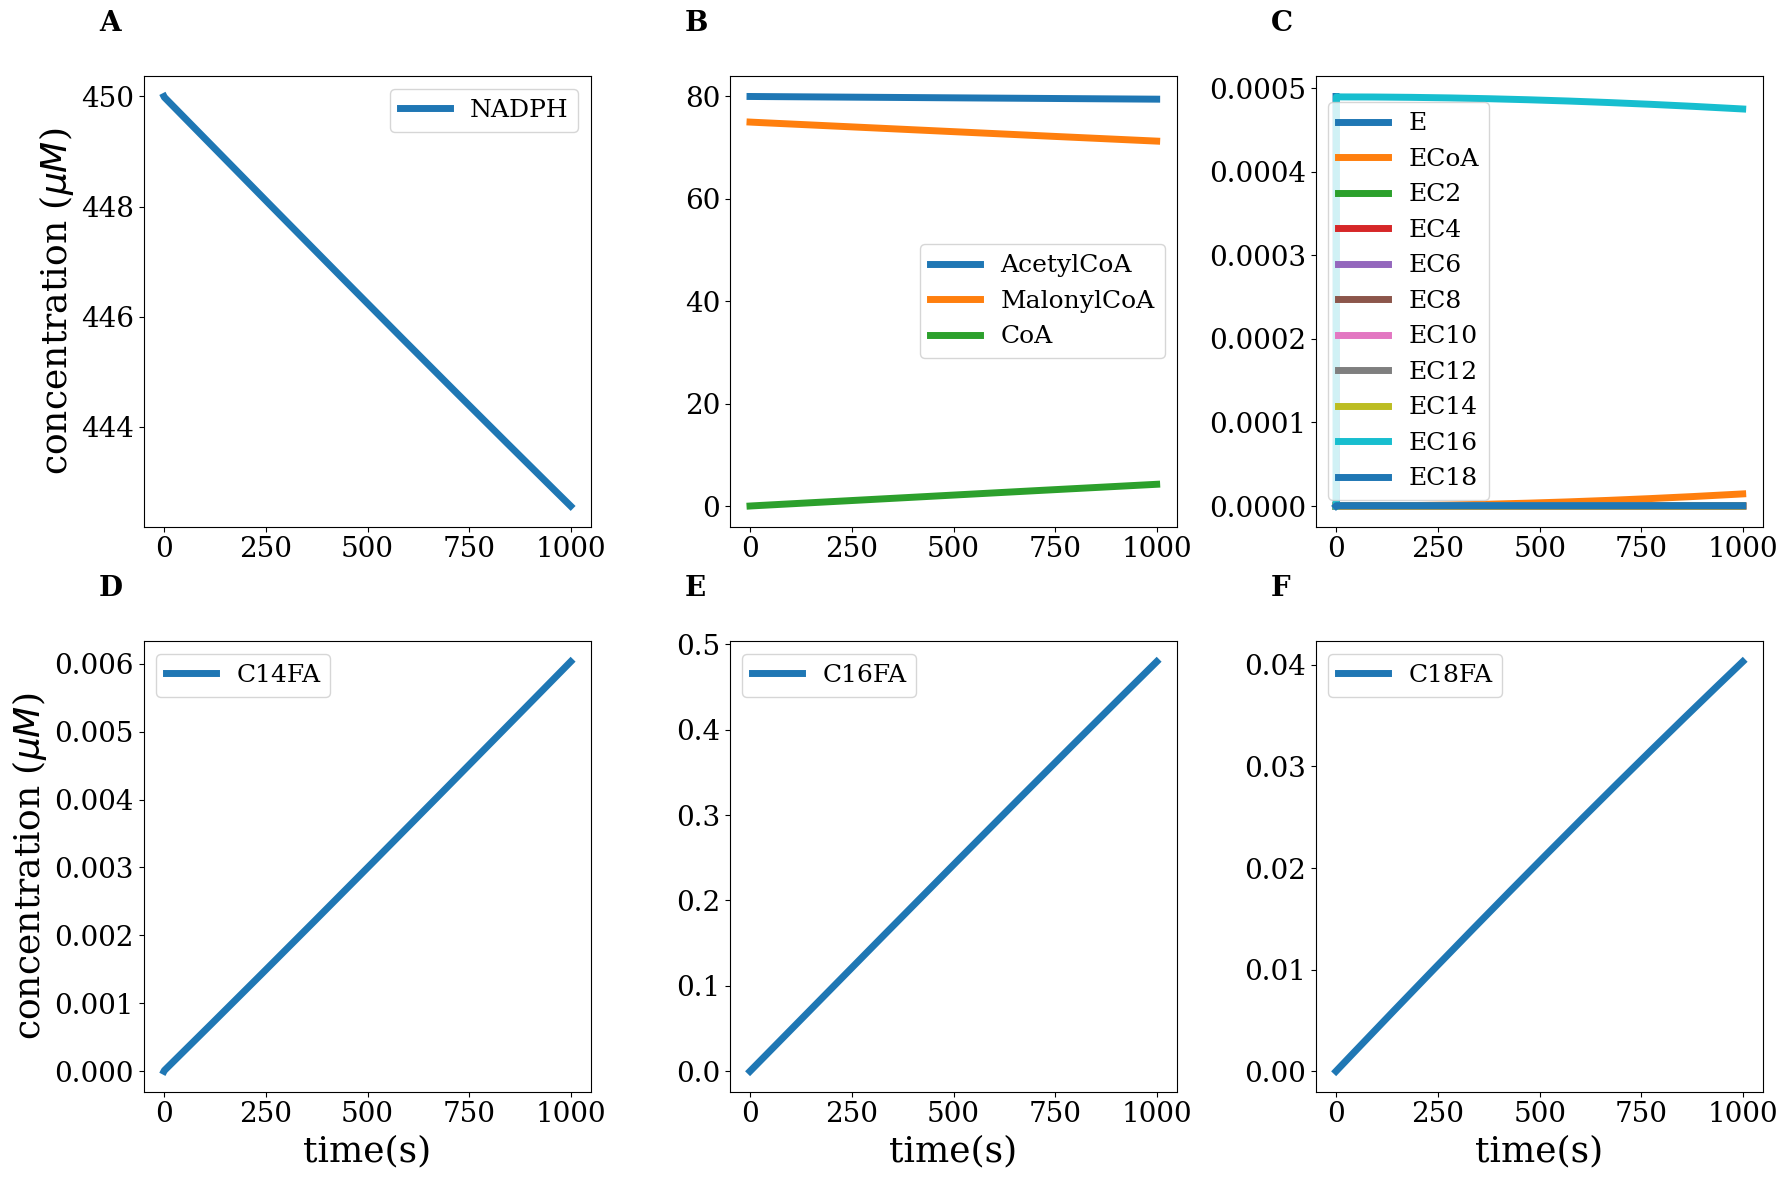

In [140]:
ncp_list4 = [i for i in range(1000)]
max_time4 =ncp_list4[-1]
fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time4,
    ncp_list=ncp_list4,
    par =par_to_use_for_trial,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title=None,
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)

# for i in range(3):
#     axs[1, i].scatter(
#         time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
#     )
#     axs[1, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})

plt.savefig(RESULTS_DIR /"initial_phase_weiss.pdf", dpi=300, bbox_inches="tight")

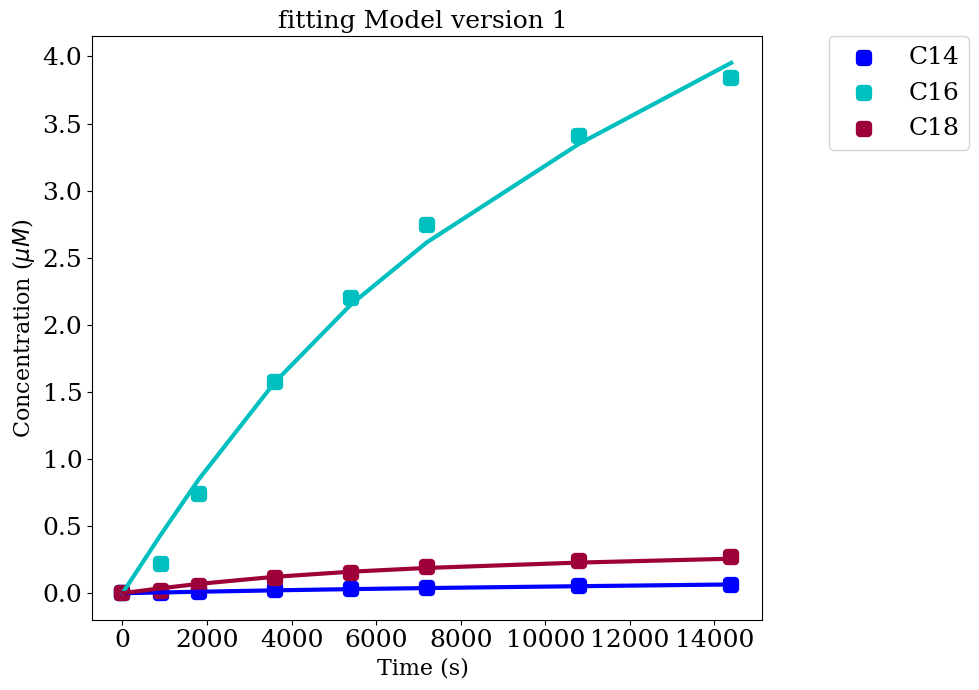

In [141]:
simul_FA = fatty_acid_of_interest(system, par_to_use_for_trial, y0,time_interp[-1], time_interp)


labels = ["C14", "C16", "C18"]
fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker="s", linewidths = 6, label = labels[i])
    ax.plot(time_interp, simul_FA[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"best_fit_2.png", bbox_inches="tight")
plt.show()


In [143]:
goodness_of_fit(data_to_fit, simul_FA)


0.06278304745477362

In [415]:
par_fit_intial_phase = dict(result.params.valuesdict())

par_fit_intial_phase 

{'beta': 8.199794165966335,
 'kappa': 0.0003061199938128034,
 'delta': 3.26330519226925e-05,
 'kd6': 0.12625650695447632,
 'kd7': 12.551275012768873,
 'kd8': 54.45295745089155,
 'kf_CoA': 0.9724603358917416,
 'kb_CoA': 0.04515502559939899,
 'E': 0.00049}

In [416]:
param = pd.DataFrame(
    {"Name ":par_fit_intial_phase.keys(), " value": par_fit_intial_phase.values()}
)
param

,Name,value
0,beta,8.199794
1,kappa,0.000306
2,delta,0.000033
3,kd6,0.126257
4,kd7,12.551275
5,kd8,54.452957
6,kf_CoA,0.972460
7,kb_CoA,0.045155
8,E,0.000490


## Remark 
The result of the fitting confirms the value of $k_{7}$ and that we can keep the precedent value of $\kappa$ . Furthermore it shows that the the value of $k_{d6}$ and $k_{d8}$  can be fixed in the large range. 

kd6:     171.519211 +/- 44331.2201 (25846.21%) (init = 1)

kd7:     0.01476275 +/- 8.0771e-05 (0.55%) (init = 0.014)

kd8:     1491.05791 +/- 802377.302 (53812.62%) (init = 1)

Therefore the new parameters values that are alrealdy validated are 

$\beta = 0.1$,  $\kappa = 1e-2$, $\delta =2.9e-07 $, 
 




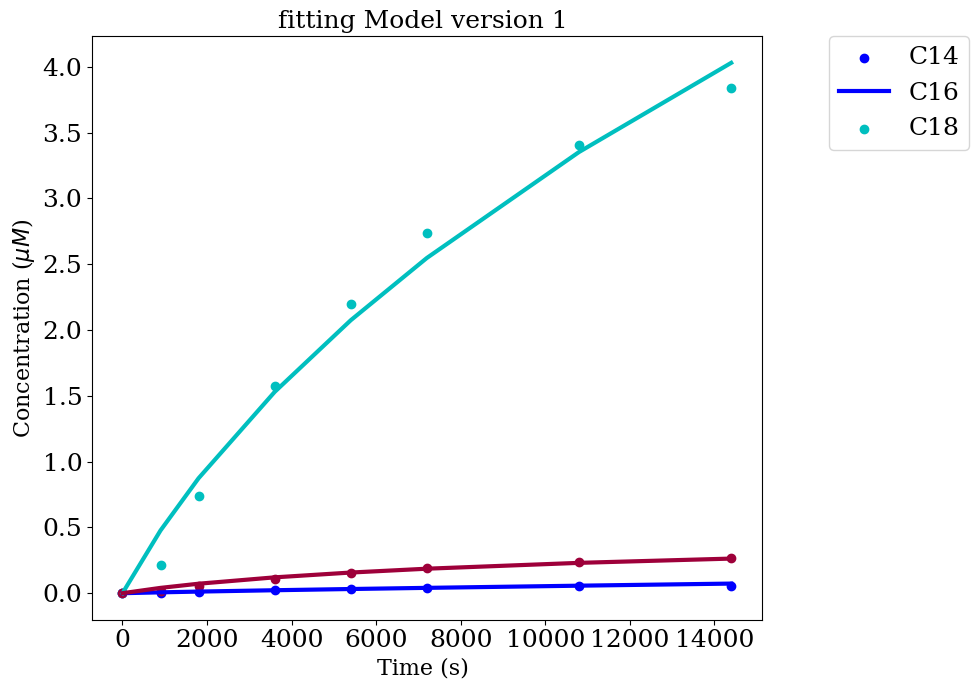

In [417]:
# plotting the results of the simulation


fig, ax = plt.subplots(figsize=(10, 7))

for i in range(3):
    ax.scatter(time_interp, data_to_fit[:, i], color=color[i][0], marker="o")
    ax.plot(time_interp, final[:, i], color=color[i][0], linewidth=3)

# plt.plot(time1, final, '-', linewidth=2);
plt.xlabel("Time (s) ", fontsize=16)
plt.ylabel("Concentration ($\mu M$) ", fontsize=16)
plt.title("fitting Model version 1 ", fontsize=18)
plt.xticks(size=18)
plt.yticks(size=18)
# plt.yscale("log")
ax.legend(
    ["C14", "C16", "C18"],
    loc="upper left",
    bbox_to_anchor=(1.1, 1),
    borderaxespad=0,
    fontsize=18,
)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"Concentrations.png", bbox_inches="tight")
plt.show()



###  Simulate for a long run the type of fatty acids produce with the Parameters obtained from fitting of the intial phase 

This is to see how the parameters from the initail phase impact the long run simulation 

In [423]:
time_course2 = [
    ["NADPH"],
    ["AcetylCoA","MalonylCoA", "CoA"],

    [ "E","ECoA", "EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14","EC16",  "EC18"],
    
   ["C14FA"], ["C16FA"], ["C18FA"]
    
]

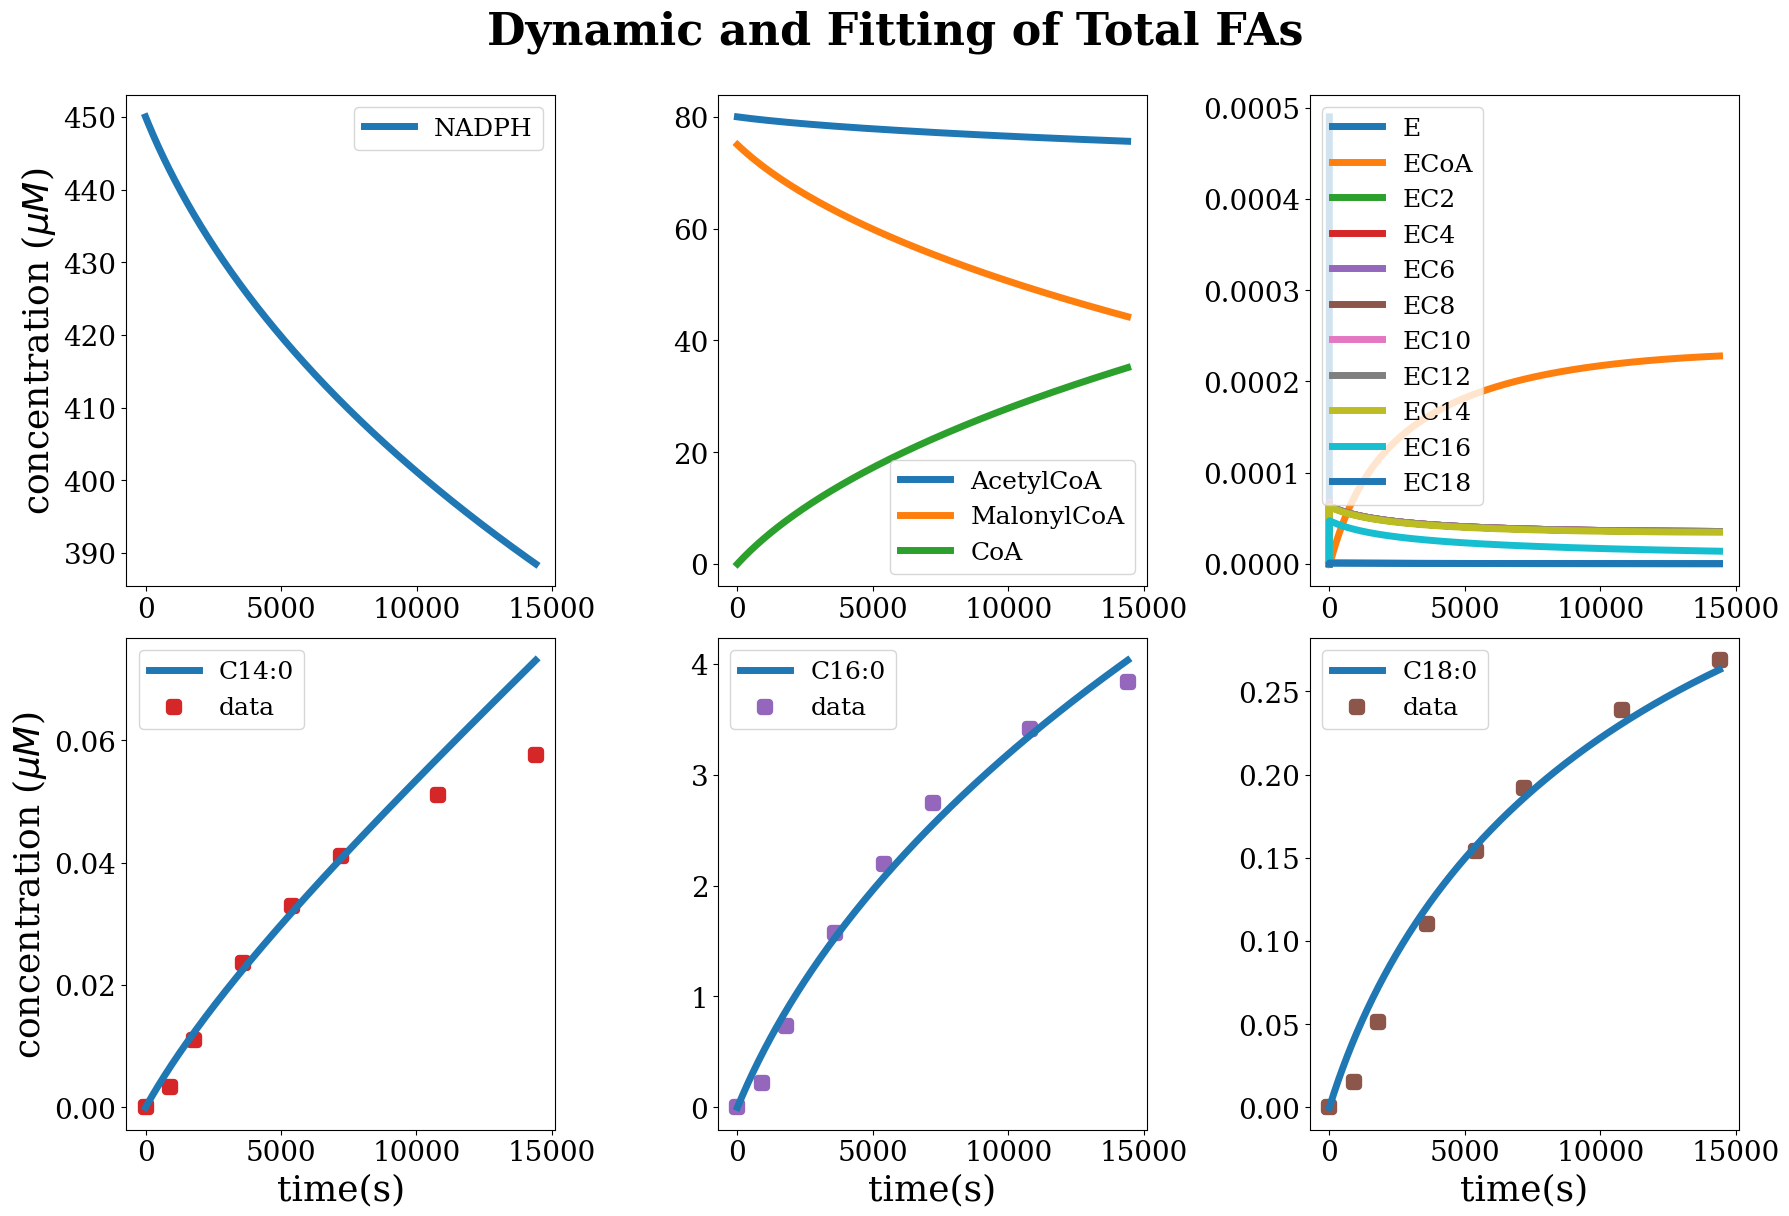

In [425]:
fig, axs = multi_plot_time_course(
    groups=time_course2,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fit_intial_phase,
    compounds=compounds,
    ncols=3,
    resizer=6,
    sharey=False,
    title="Dynamic and Fitting of Total FAs",
    xlabel="time(s)",
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:, 0][0] = 0
data_to_fit[:, 1][0] = 0
data_to_fit[:, 2][0] = 0
for i in range(3):
    axs[1, i].scatter(
        time_interp, data_to_fit[:, i], color=cols[i + 3], marker="s", linewidths=6
    )
    axs[1, i].legend([f"C{14+2*i}:0", "data"], prop={"size": 18})
plt.savefig(RESULTS_DIR /"individual_fit_best3.pdf", dpi=300, bbox_inches="tight")

## Conclusion 

We need a different strategy to fit the transient and the steady state data. We suggest to explore three strategy 

- The solubility 
- The sinking enzyme(no longer the conservation relation for the enzymes ) 
- Or the reversing binding for malanyl-coA


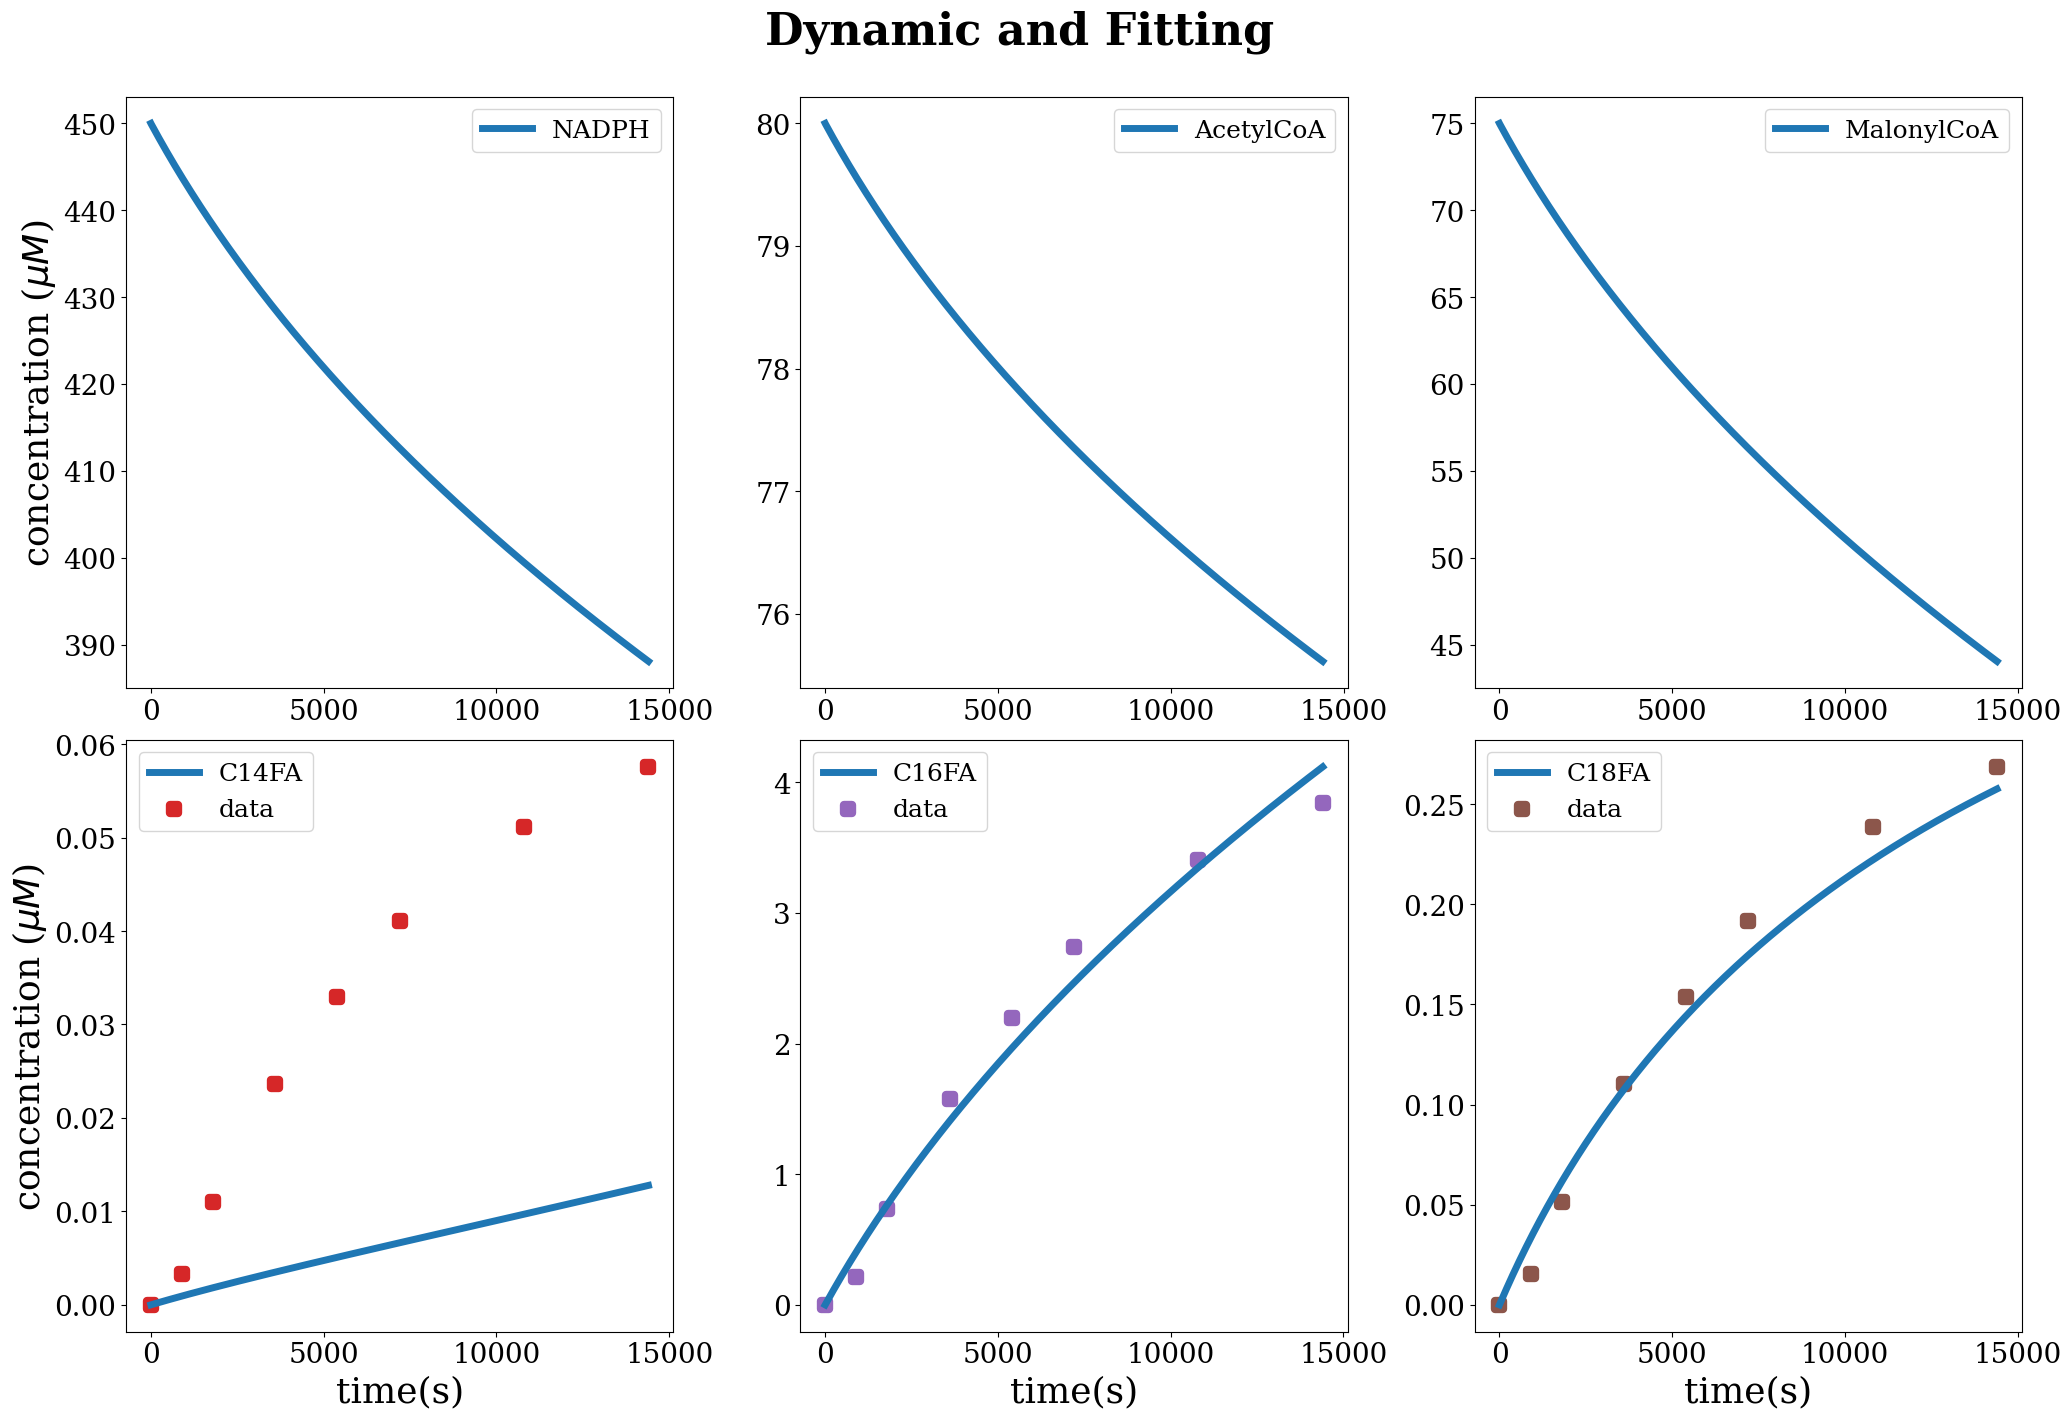

In [224]:
long_run = [
    ["NADPH"],
    ["AcetylCoA"],
    ["MalonylCoA"],
    ["C14FA"],
    ["C16FA"],
    
    ["C18FA"],
    # ["EC2", "EC4", "EC6", "EC8", "EC10", "EC12", "EC14", "EC16", "EC18"],
    # [
    #     "C14FA",
    #     "C16FA",
    #     "C18FA",
    # ],
]

fig, axs = multi_plot_time_course(
    groups=long_run,
    func=simulate_time_course,
    model=system,
    y0=y0,
    max_time=max_time2,
    ncp_list=ncp_list2,
    par=par_fit_intial_phase,
    compounds=compounds,
    ncols=3,
    resizer=7,
    sharey=False,
    title="Dynamic and Fitting ",
    xlabel="time(s)", 
    ylabel="concentration ($\mu M$)",
)
data_to_fit[:,0][0] = 0
data_to_fit[:,1][0] =0
data_to_fit[:,2][0] =0
for i in range(3):
    axs[1,i].scatter(time_interp, data_to_fit[:, i], color=cols[i+3], marker="s", linewidths = 6)
    axs[1,i].legend([f"C{14+2*i}FA", "data"],  prop={'size': 18})
    
plt.savefig(RESULTS_DIR /"individual_fit_best3.pdf", dpi =300,  bbox_inches='tight')
    
    


In [225]:
data_to_fit[:,0][0] =0
data_to_fit[:,1][0] =0
data_to_fit[:,2][0] = 0

In [226]:
all_fatty_acids= fatty_acid_of_interest(system, par_fit_intial_phase  , y0, max_time = time_simulations, ncp_list = time_simulations)
all_fatty_acids


array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.42623573e-04, 4.04861025e-01, 3.32000934e-02],
       [1.83006765e-03, 7.67741125e-01, 6.13926692e-02],
       [3.50255935e-03, 1.40644250e+00, 1.07524019e-01],
       [5.09411633e-03, 1.96444471e+00, 1.44303935e-01],
       [6.64299044e-03, 2.46568114e+00, 1.74643394e-01],
       [9.69760570e-03, 3.34851915e+00, 2.22131858e-01],
       [1.27811468e-02, 4.11845130e+00, 2.57646849e-01]])

In [227]:
goodness_of_fit(all_fatty_acids[:,1], data_to_fit[:,1])

0.1858626590399459

# To Do
1. Write the procedure which consist of varying individual parameters and see how the baseline solution are affected
2. See how I can use Salib library for sentivity ananlysis 
3. Local sensitivity analysis vs Global sensitivity analysis (sobol decomposition )
4.  The contribution of each parameter to the overall model 

In [228]:
base_line_parameters = par_fit_intial_phase.copy()
param = pd.DataFrame(
    {"Name ":par_fit_intial_phase.keys(), " value": par_fit_intial_phase.values()}
)
param

,Name,value
0,beta,1.999971
1,kappa,0.001359
2,delta,0.000003
3,kd6,0.095877
4,kd7,1.180000
5,kd8,30.038653
6,kf_CoA,3.211964
7,kb_CoA,0.623941
8,E,0.000490


In [229]:
{'beta': 0.05916222463698628,
 'kappa': 0.9850436984516543,
 'delta': 6.5e-06,
 'kd1': 0,
 'kd2': 0,
 'kd3': 0,
 'kd4': 0,
 'kd5': 0,
 'kd6': 333.08376125345046,
 'kd7': 1.18,
 'kd8': 181.48854589143144,
 'kf_CoA': 2.314111537460306e-05,
 'kb_CoA': 3.188610464555097e-08}

{'beta': 0.05916222463698628,
 'kappa': 0.9850436984516543,
 'delta': 6.5e-06,
 'kd1': 0,
 'kd2': 0,
 'kd3': 0,
 'kd4': 0,
 'kd5': 0,
 'kd6': 333.08376125345046,
 'kd7': 1.18,
 'kd8': 181.48854589143144,
 'kf_CoA': 2.314111537460306e-05,
 'kb_CoA': 3.188610464555097e-08}

In [230]:
fat_track =[
    ["C14FA"],
    ["C16FA"],
    ["C18FA"],
  
]

def fititing_var(par,par_interest, n_instance, var_percent, transp =0.02): 
    par1 =  par.copy()

    best_par =  par1[par_interest]
    lower_bound = best_par - best_par*var_percent
    upper_bound = best_par + best_par*var_percent
    par_range = np.linspace(lower_bound, upper_bound, n_instance)
    best_line = fatty_acid_of_interest(system, base_line_parameters  , y0, max_time = time_simulations, ncp_list = time_simulations)
    
 
    fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
    
    for j in par_range:
        par1[par_interest] = j
        y = fatty_acid_of_interest(system, par1  , y0, max_time = time_simulations, ncp_list = time_simulations)
        for i in range(3):
            axs[i].plot(time_interp, y[:, i], linewidth = 6,  alpha=transp, label = f"{par_interest} = {j}")
    for l in range(3):
            axs[l].plot(time_interp, best_line[:, l], color="b", linewidth = 6, label = f"{par_interest} = { par[par_interest]} )")
    
    for k in range(3):
            axs[k].scatter(time_interp, data_to_fit[:, k], color="k", marker="s", linewidth = 6, label = f"C{14+2*k}:0 data")
           
    fig.suptitle(f'Impact  of the ${par_interest}$ on the dynamics (x={var_percent *100}%)', fontsize=32.0, fontname="serif", fontweight="bold", y =1.01)
    for ax in axs.flatten():
        ax.tick_params(axis="both", labelsize=20)
    lines_labels = [axs[2].get_legend_handles_labels()]
    lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
    fig.legend(lines, labels, loc="upper left", bbox_to_anchor=(1, 0.5))

        
    fig.patch.set_alpha(0.0)
    # handles, labels = axs.get_legend_handles_labels()
    # fig.legend(handles, labels, loc='upper center')   
        
    fig.tight_layout()
        

        


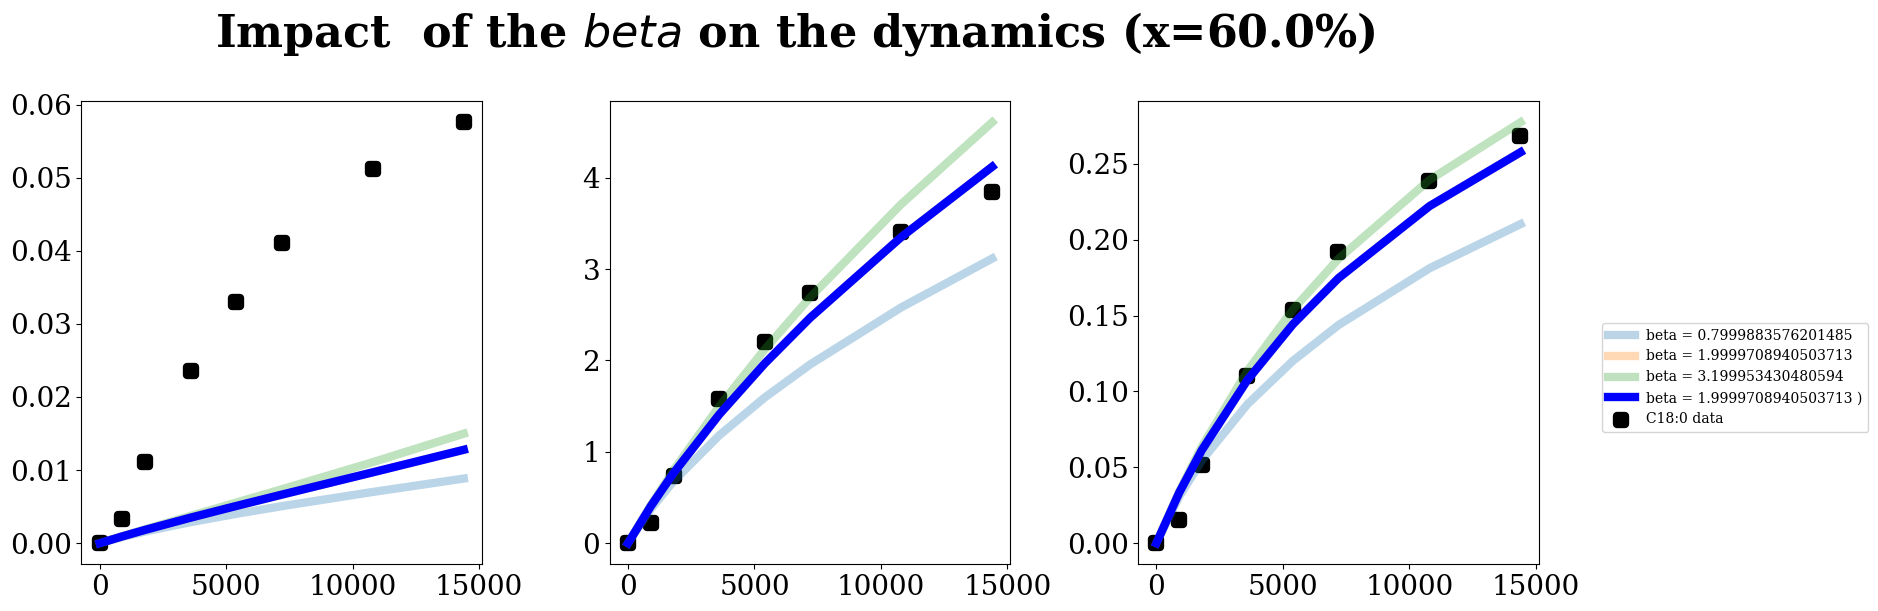

In [231]:
fititing_var(par = base_line_parameters,par_interest = "beta", n_instance=3, var_percent=0.6,transp=0.3)
plt.savefig(RESULTS_DIR /"beta_var", dpi =300,  bbox_inches='tight')

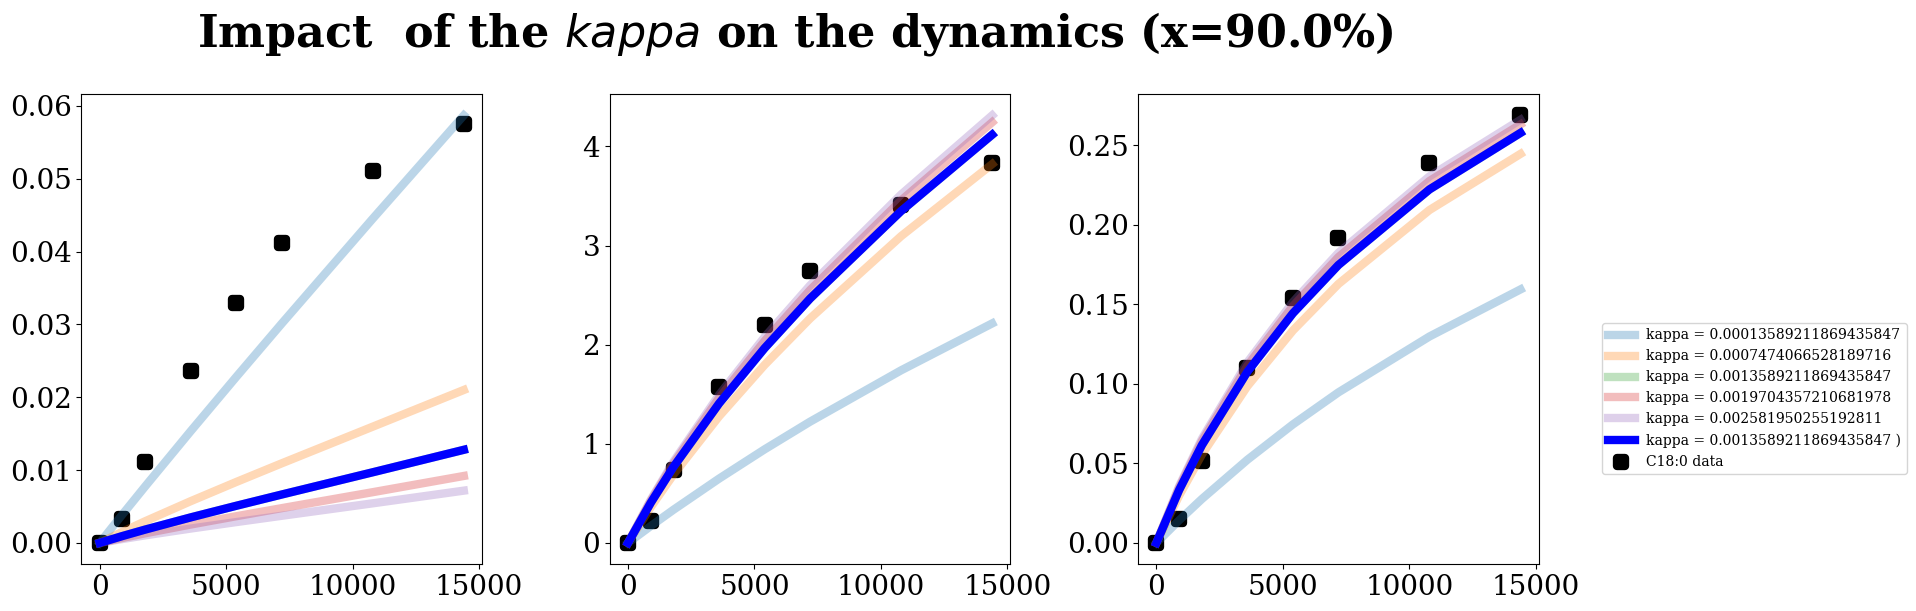

In [232]:
fititing_var(par = base_line_parameters,par_interest = "kappa", n_instance=5, var_percent=0.9,transp=0.3)
plt.savefig(RESULTS_DIR /"kappa_var", dpi =300,  bbox_inches='tight')

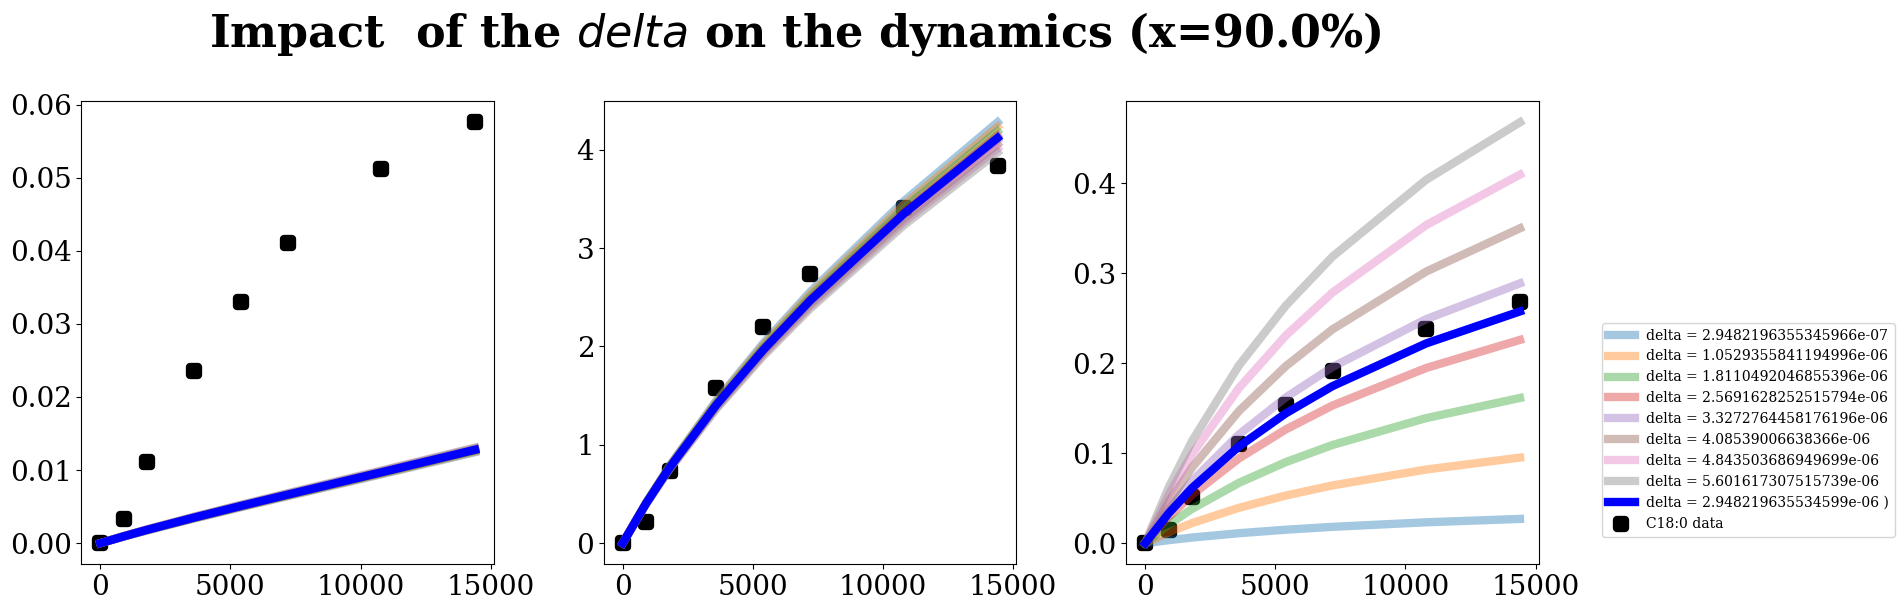

In [233]:
fititing_var(par = base_line_parameters,par_interest = "delta", n_instance=8, var_percent=0.9,transp=0.4)
plt.savefig(RESULTS_DIR /"delta_var", dpi =300,  bbox_inches='tight')

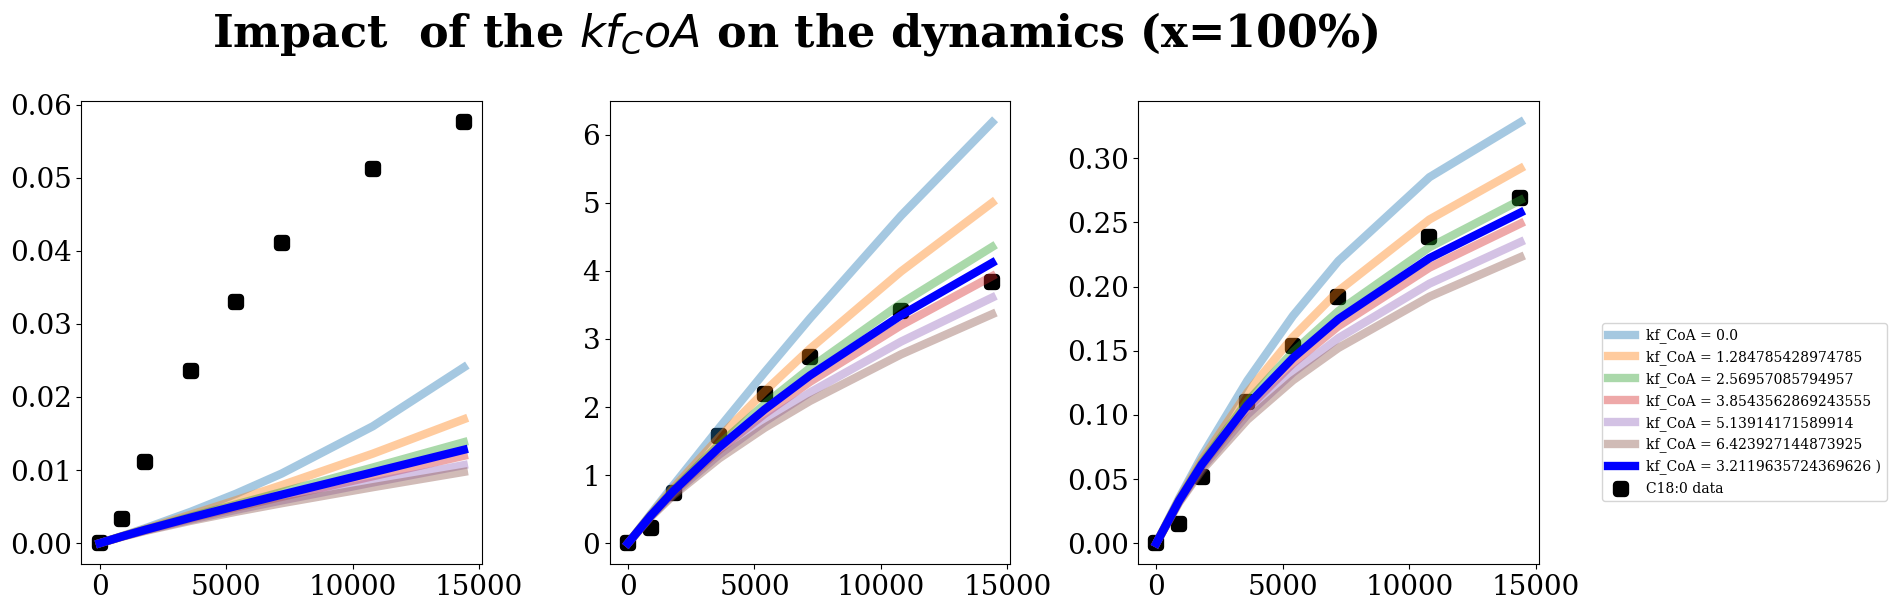

In [234]:
fititing_var(par = base_line_parameters,par_interest = "kf_CoA", n_instance=6, var_percent=1,transp=0.4)
plt.savefig(RESULTS_DIR /"kf_CoA", dpi =300,  bbox_inches='tight')

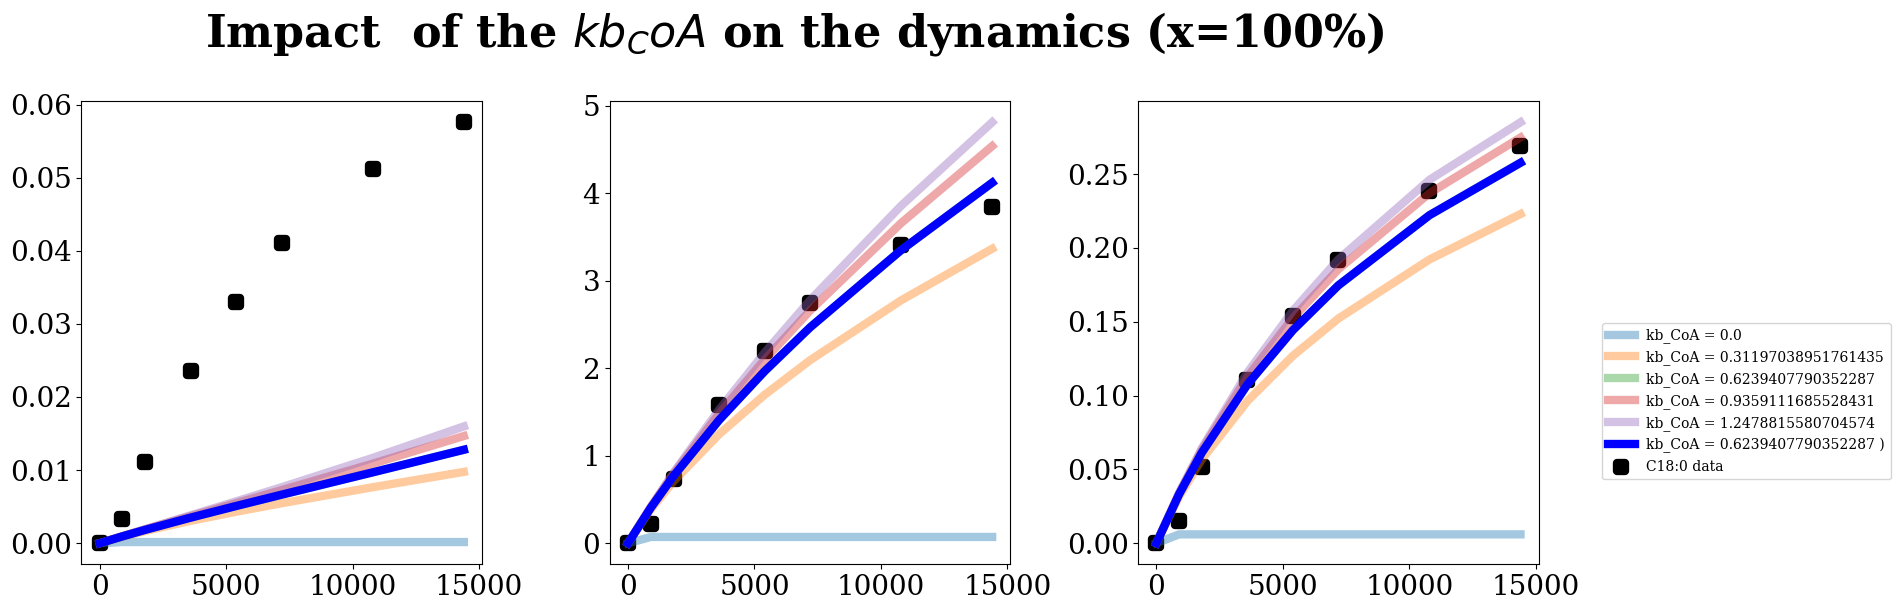

In [235]:
fititing_var(par = base_line_parameters,par_interest = "kb_CoA", n_instance=5, var_percent=1,transp=0.4)
plt.savefig(RESULTS_DIR /"kb_CoA", dpi =300,  bbox_inches='tight')

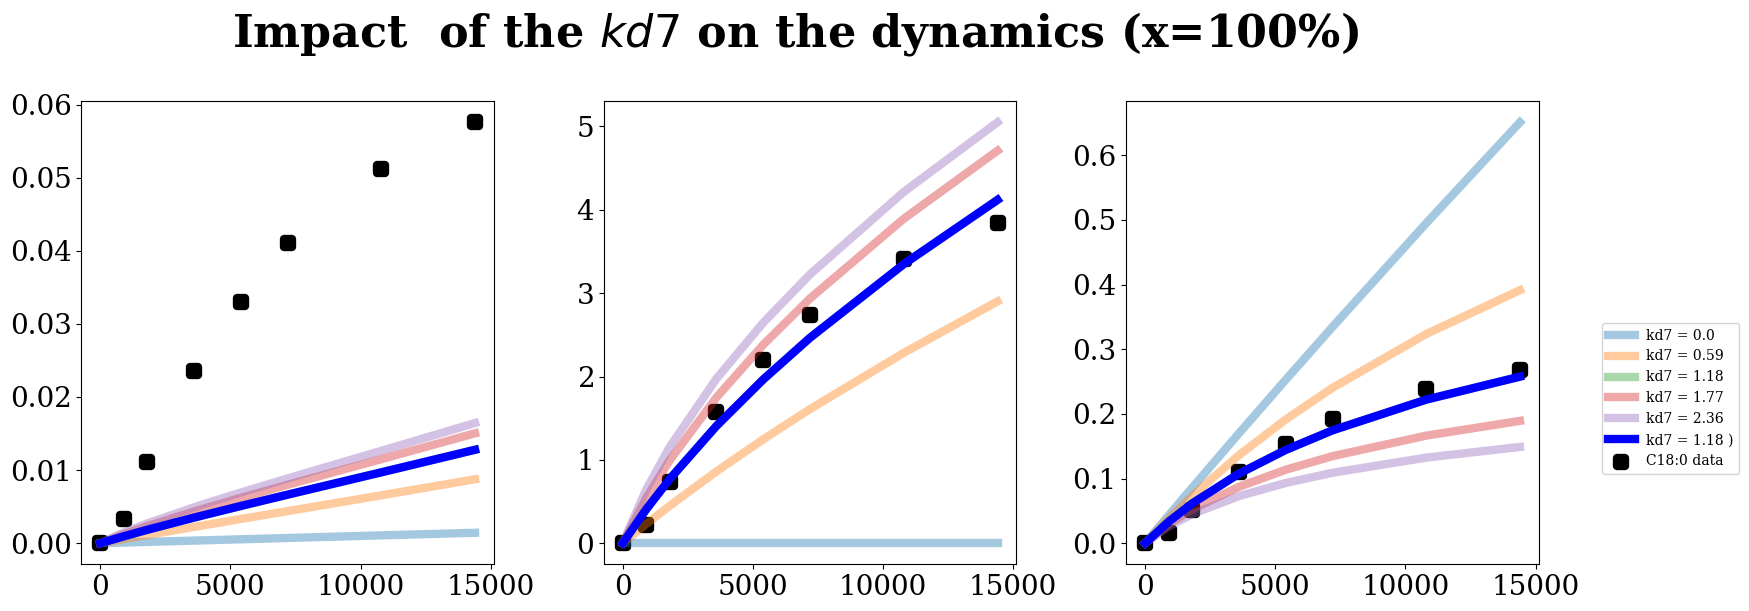

In [236]:
fititing_var(par = base_line_parameters,par_interest = "kd7", n_instance=5, var_percent=1,transp=0.4)
plt.savefig(RESULTS_DIR /"kd7", dpi =300,  bbox_inches='tight')

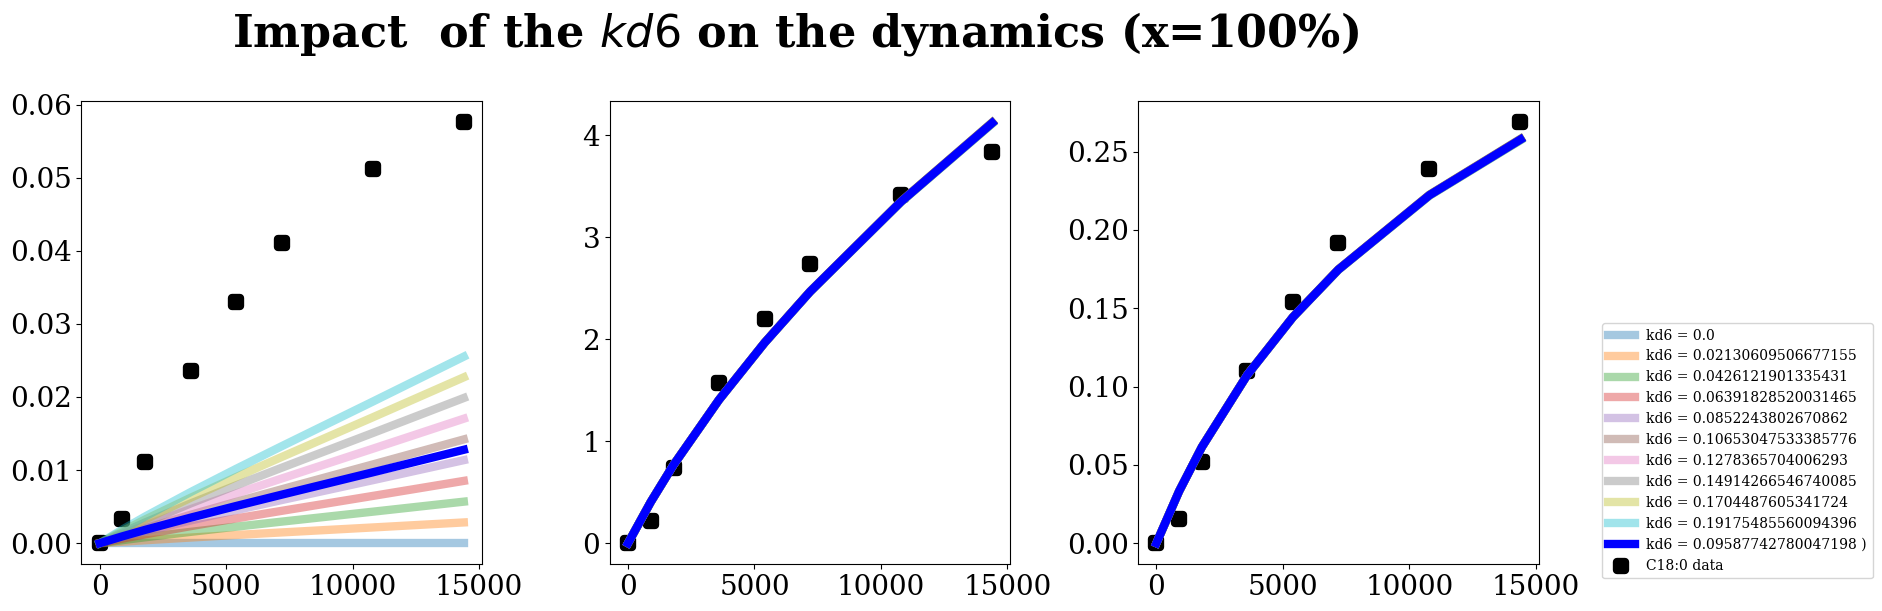

In [237]:
fititing_var(par = base_line_parameters,par_interest = "kd6", n_instance=10, var_percent=1,transp=0.4)
plt.savefig(RESULTS_DIR /"kd6", dpi =300,  bbox_inches='tight')

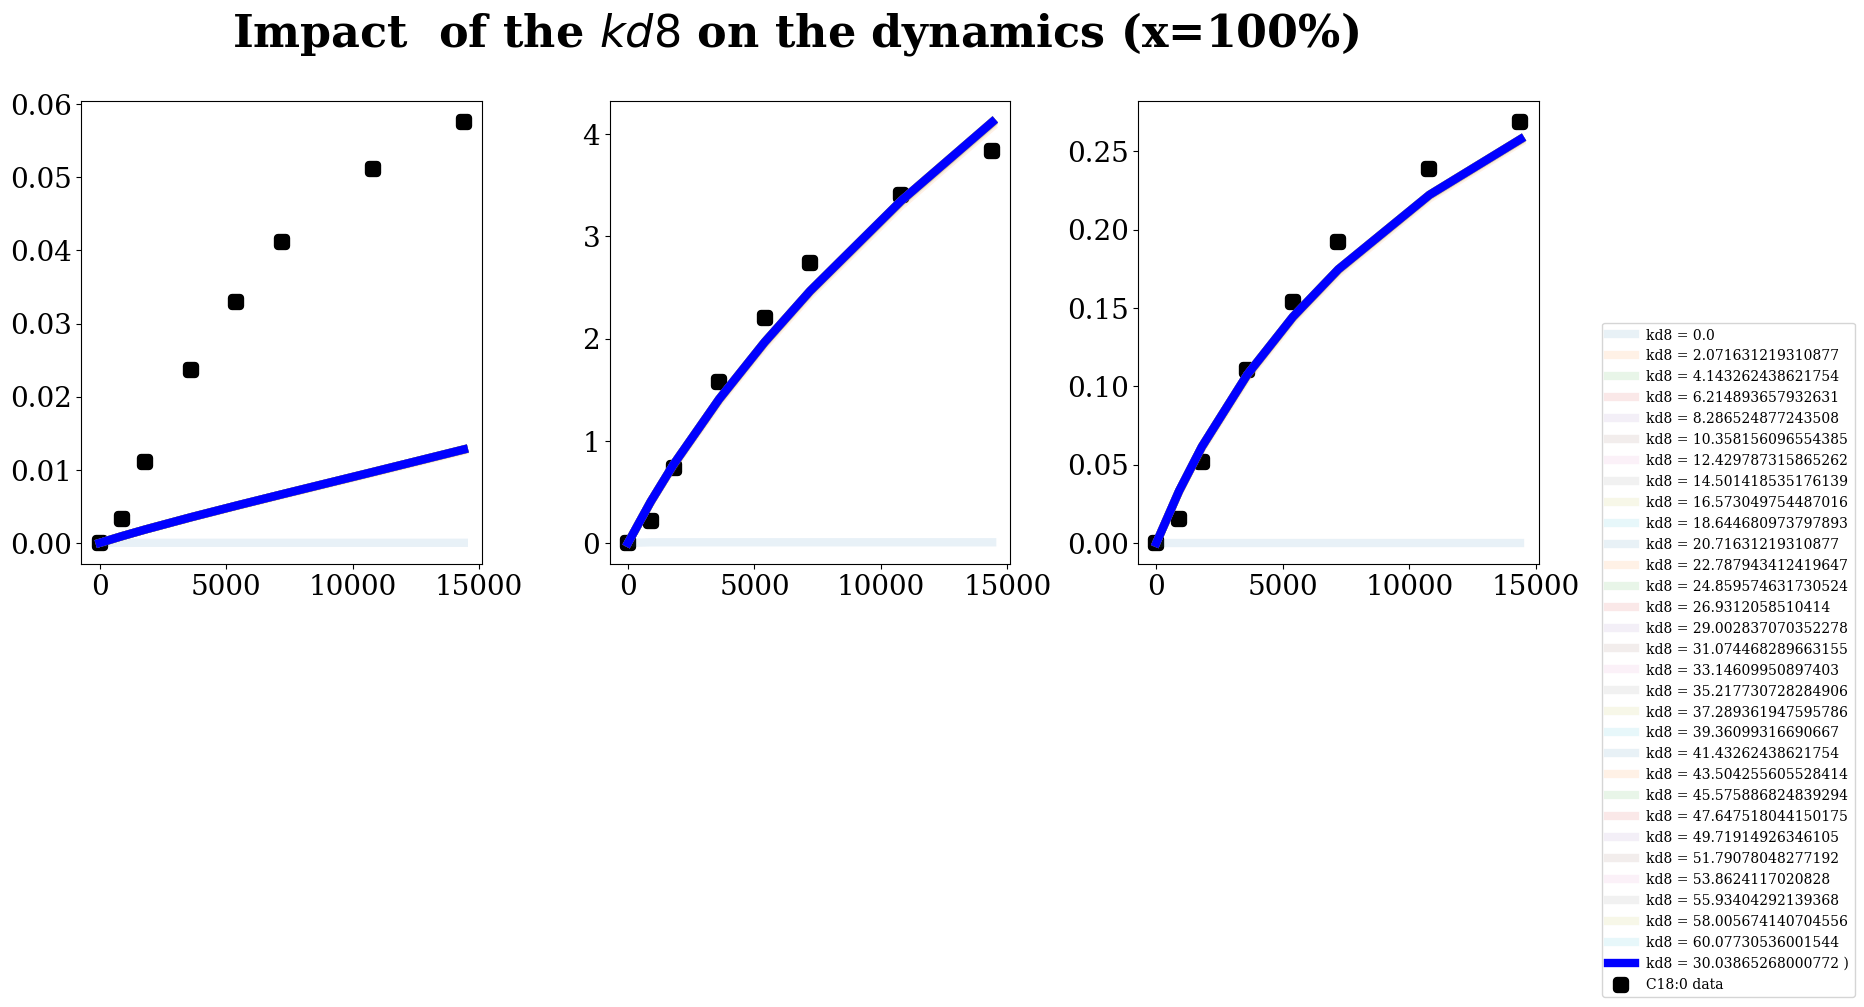

In [238]:
fititing_var(par = base_line_parameters,par_interest = "kd8", n_instance=30, var_percent=1,transp=0.1)
plt.savefig(RESULTS_DIR /"kd8", dpi =300,  bbox_inches='tight')

In [240]:
perc = 1
problem = {
    "num_vars": 8,
    "names": [
        "beta",
        "kappa",
        "delta",
        "kd6",
        "kd7",
        "kd8",
        "kf_CoA",
        "kb_CoA",
    ],
    "bounds": [
        [
            base_line_parameters["beta"] - perc * base_line_parameters["beta"],
            base_line_parameters["beta"] + perc * base_line_parameters["beta"],
        ],
        [
            base_line_parameters["kappa"] - perc * base_line_parameters["kappa"],
            base_line_parameters["kappa"] + perc * base_line_parameters["kappa"],
        ],
        [
            base_line_parameters["delta"] - perc * base_line_parameters["delta"],
            base_line_parameters["delta"] + perc * base_line_parameters["delta"],
        ],
        # [
        #     base_line_parameters["kd1"] - perc * base_line_parameters["kd1"],
        #     base_line_parameters["kd1"] + perc * base_line_parameters["kd1"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd2"] - perc * base_line_parameters["kd2"],
        #     base_line_parameters["kd2"] + perc * base_line_parameters["kd2"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd3"] - perc * base_line_parameters["kd3"],
        #     base_line_parameters["kd3"] + perc * base_line_parameters["kd3"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd4"] - perc * base_line_parameters["kd4"],
        #     base_line_parameters["kd4"] + perc * base_line_parameters["kd4"] + 1e-25,
        # ],
        # [
        #     base_line_parameters["kd5"] - perc * base_line_parameters["kd5"],
        #     base_line_parameters["kd5"] + perc * base_line_parameters["kd5"] + 1e-25,
        # ],
        [
            base_line_parameters["kd6"] - perc * base_line_parameters["kd6"],
            base_line_parameters["kd6"] + perc * base_line_parameters["kd6"],
        ],
        [
            base_line_parameters["kd7"] - perc * base_line_parameters["kd7"],
            base_line_parameters["kd7"] + perc * base_line_parameters["kd7"],
        ],
        [
            base_line_parameters["kd8"] - perc * base_line_parameters["kd8"],
            base_line_parameters["kd8"] + perc * base_line_parameters["kd8"],
        ],
        [
            base_line_parameters["kf_CoA"] - perc * base_line_parameters["kf_CoA"],
            base_line_parameters["kf_CoA"] + perc * base_line_parameters["kf_CoA"],
        ],
        [
            base_line_parameters["kb_CoA"] - perc * base_line_parameters["kb_CoA"],
            base_line_parameters["kb_CoA"] + perc * base_line_parameters["kb_CoA"],
        ],
    ],
}
print(problem["bounds"])
param_values = saltelli.sample(problem, 100, calc_second_order=True)

N = len(param_values)  # number of parameter samples
Y = []
for i in range(N):
    param_dict = dict(zip(problem["names"], param_values[i]))
    Y.append(
        (
            fatty_acid_of_interest(
                system,
                param_dict,
                y0,
                max_time=time_simulations,
                ncp_list=time_simulations,
            )
        )
    )
a = np.concatenate(Y, axis=None)

Si = sobol.analyze(problem, a, print_to_console=False)

print(Si["S1"])



[[0.0, 3.9999417881007426], [0.0, 0.0027178423738871693], [0.0, 5.896439271069198e-06], [0.0, 0.19175485560094396], [0.0, 2.36], [0.0, 60.07730536001544], [0.0, 6.423927144873925], [0.0, 1.2478815580704574]]


/home/chilperic/mambaforge/envs/fatty-acids/lib/python3.10/site-packages/SALib/sample/saltelli.py:94: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (100) is equal to `2^n`.
        
  warnings.warn(msg)


[-2.86130499e+01 -2.04827936e+00 -5.83487411e-02 -3.85769443e+01
 -2.66318739e+00  2.46390759e-03 -2.75461166e+01 -1.74262814e+00]


In [ ]:

def system(time, y, par):
    get_rates = rates(par=par, y=y)
    derivatives = {
        "dAcetylCoA": -get_rates["AcetylCoA__EC2"],
        "dMalonylCoA": -(
            get_rates["EC2__EC4"]
            + get_rates["EC4__EC6"]
            + get_rates["EC6__EC8"]
            + get_rates["EC8__EC10"]
            + get_rates["EC10__EC12"]
            + get_rates["EC12__EC14"]
            + get_rates["EC14__EC16"]
            + get_rates["EC16__EC18"]
        ),
        # "dC4FA": get_rates["EC4__C4FA"] ,
        # "dC6FA": get_rates["EC6__C6FA"] ,
        # "dC8FA": get_rates["EC8__C8FA"] ,
        # "dC10FA": get_rates["EC10__C10FA"],
        # "dC12FA": get_rates["EC12__C12FA"],
        "dC14FA": get_rates["EC14__C14FA"],
        "dC16FA": get_rates["EC16__C16FA"],
        "dC18FA": get_rates["EC18__C18FA"],

        # "dCoA": -get_rates["E__ECoA"]
        # +(get_rates["AcetylCoA__EC2"]
        #   + get_rates["EC2__EC4"] 
        #   + get_rates["EC4__EC6"]
        #   + get_rates["EC6__EC8"]
        #   + get_rates["EC8__EC10"]
        #   + get_rates["EC10__EC12"]
        #   + get_rates["EC12__EC14"]
        #   + get_rates["EC14__EC16"]
        #   + get_rates["EC16__EC18"]),
        "dE": -get_rates["AcetylCoA__EC2"] +
     (
            # get_rates["EC4__C4FA"]
            # + get_rates["EC6__C6FA"]
            # + get_rates["EC8__C8FA"]
            # + get_rates["EC10__C10FA"]
            # + get_rates["EC12__C12FA"]
            + get_rates["EC14__C14FA"]
            + get_rates["EC16__C16FA"]
            + get_rates["EC18__C18FA"]
        ),
        
        "dEC2": get_rates["AcetylCoA__EC2"] - get_rates["EC2__EC4"],
        "dEC4": get_rates["EC2__EC4"]
        - get_rates["EC4__EC6"],
        "dEC6": get_rates["EC4__EC6"]
        - get_rates["EC6__EC8"],
        "dEC8": get_rates["EC6__EC8"]
        - get_rates["EC8__EC10"],
        "dEC10": get_rates["EC8__EC10"]
        - get_rates["EC10__EC12"],
        "dEC12": get_rates["EC10__EC12"]
        - get_rates["EC12__EC14"],
        "dEC14": get_rates["EC12__EC14"]
        - get_rates["EC14__EC16"]
        - get_rates["EC14__C14FA"],
        "dEC16": get_rates["EC14__EC16"]
        - get_rates["EC16__EC18"]
        - get_rates["EC16__C16FA"],
        "dEC18": get_rates["EC16__EC18"]
        - get_rates["EC18__C18FA"],
        # "dECoA": get_rates["E__ECoA"],
        "dNADPH": -2
        * (
            get_rates["EC2__EC4"]
            + get_rates["EC4__EC6"]
            + get_rates["EC6__EC8"]
            + get_rates["EC8__EC10"]
            + get_rates["EC10__EC12"]
            + get_rates["EC12__EC14"]
            + get_rates["EC14__EC16"]
            + get_rates["EC16__EC18"]
        ),
    }
    # da = [derivatives[f"dEC{i}"] for i in range(2, 20, 2)]
    # da.append(derivatives["dECoA"])
    # print(sum(da)+ derivatives["dE"])

    return np.fromiter(derivatives.values(), dtype=float)

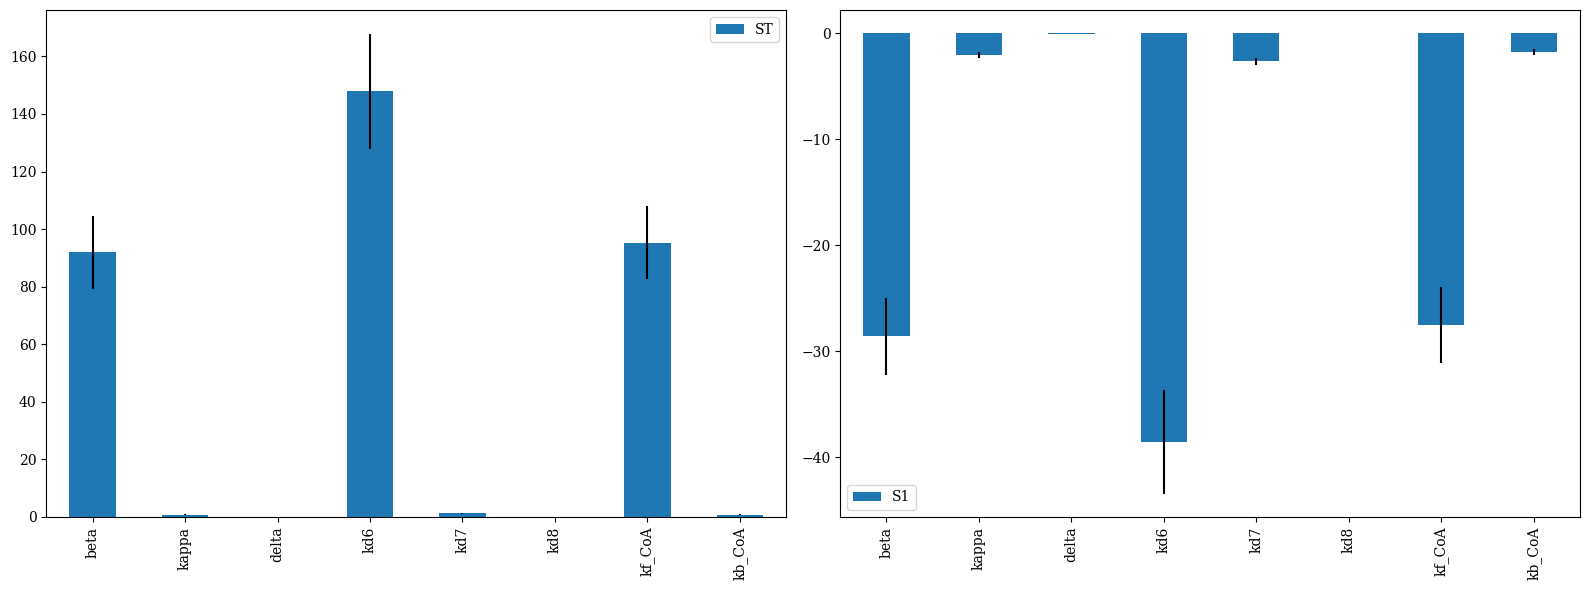

In [241]:
Saltelli_T, Saltelli_1st, Saltelli_2st = Si.to_df()

# More direct control by manually specifying figure attributes
# See Figure 2 below
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))

ax1 = barplot(Saltelli_T, ax=ax1)
ax2 = barplot(Saltelli_1st, ax=ax2)
#ax3 = barplot(Saltelli_2st, ax=ax3)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"sens_weiss_model1.pdf", dpi=300, bbox_inches="tight")


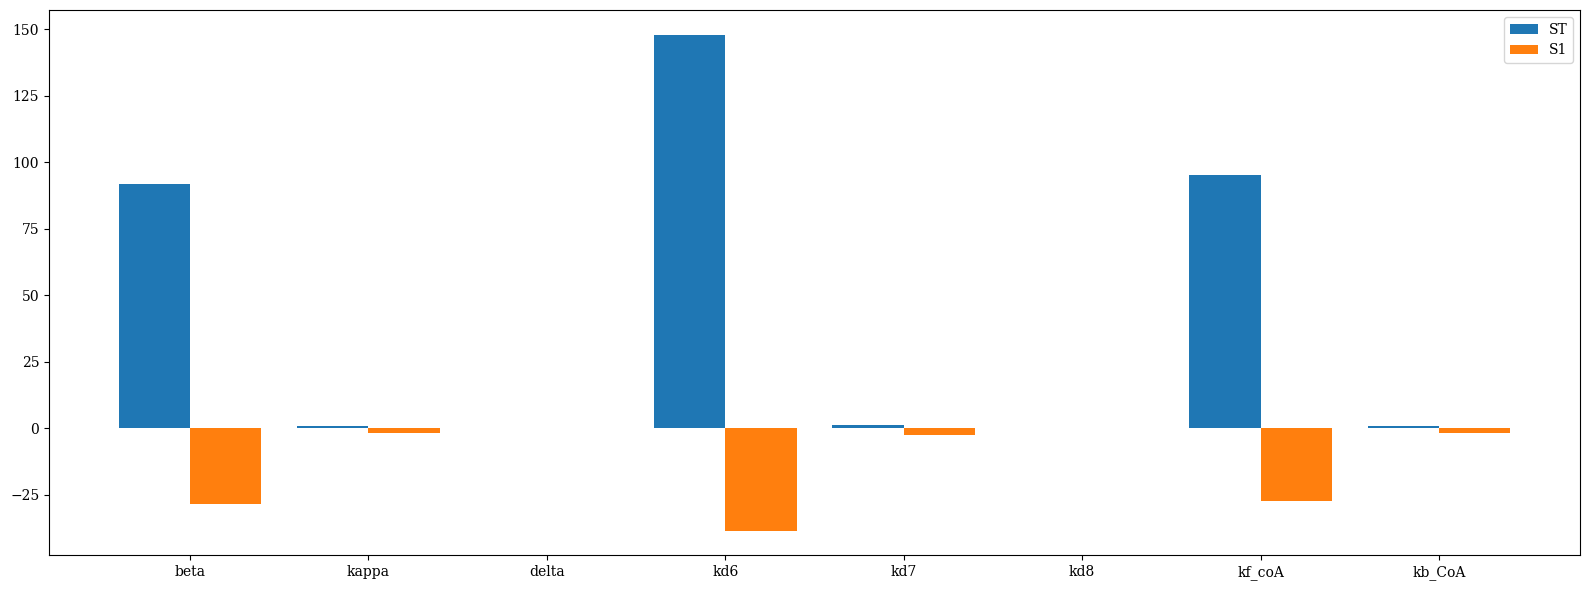

In [253]:
X = ["beta", "kappa", "delta",  "kd6", "kd7", "kd8",  "kf_coA", "kb_CoA"]
fig, ax1 = plt.subplots(1,1, figsize=(16,6))
X_axis = np.arange(len(X))
plt.bar(X_axis - 0.2, Saltelli_T["ST"], 0.4, label = 'ST')
plt.bar(X_axis + 0.2, Saltelli_1st["S1"], 0.4, label = 'S1')
plt.xticks(X_axis, X)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR /"sens_weiss_modelt.pdf", dpi=300, bbox_inches="tight")


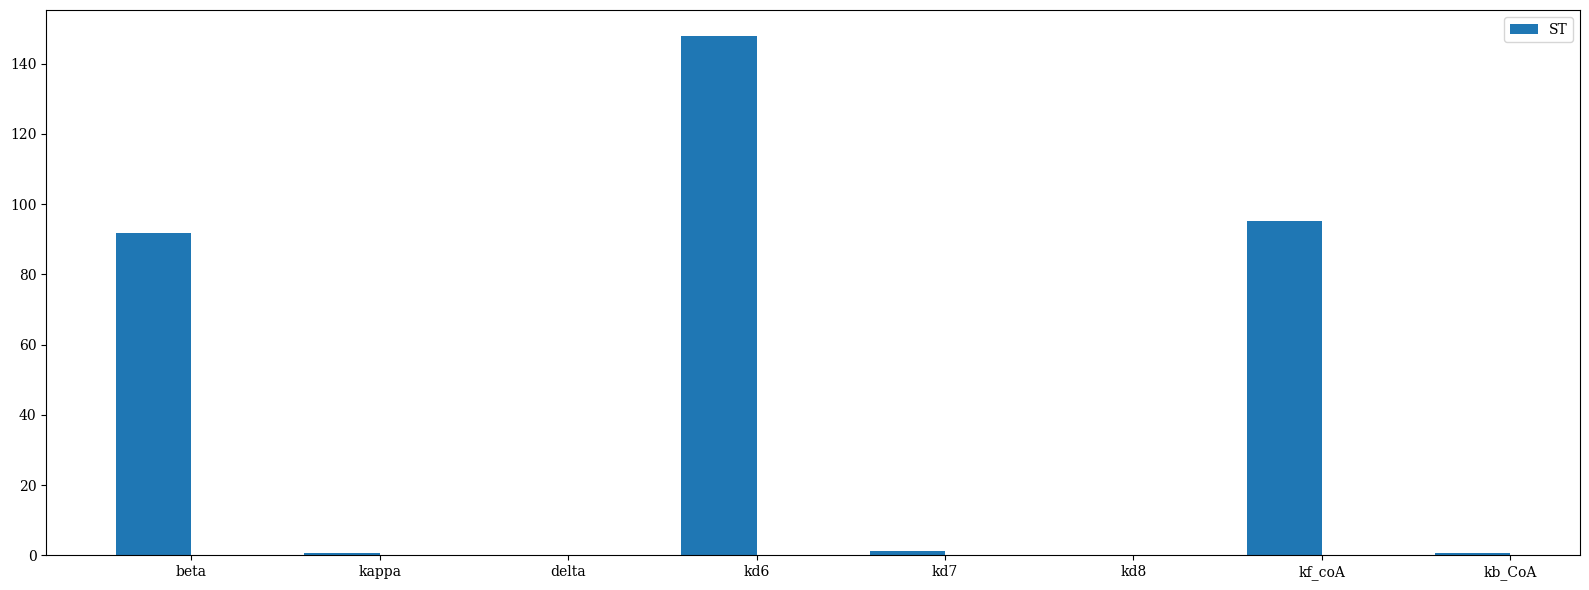

In [254]:
X = ["beta", "kappa", "delta", "kd6", "kd7", "kd8",  "kf_coA", "kb_CoA"]
fig, ax1 = plt.subplots(1,1, figsize=(16,6))
X_axis = np.arange(len(X))
plt.bar(X_axis - 0.2, Saltelli_T["ST"], 0.4, label = 'ST')
#plt.bar(X_axis + 0.2, Saltelli_1st["S1"], 0.4, label = 'S1')
plt.xticks(X_axis, X)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR /"sens_weiss_modelst.pdf", dpi=300, bbox_inches="tight")


In [244]:
# fatty_acid_of_interest(
#     system,
#    par_fit_intial_phase,
#     y0,
#     max_time=time_simulations,
#     ncp_list=time_simulations,
# )


In [245]:
print(len(param_dict)) ,print(len(par_fit_intial_phase))

8
9


(None, None)

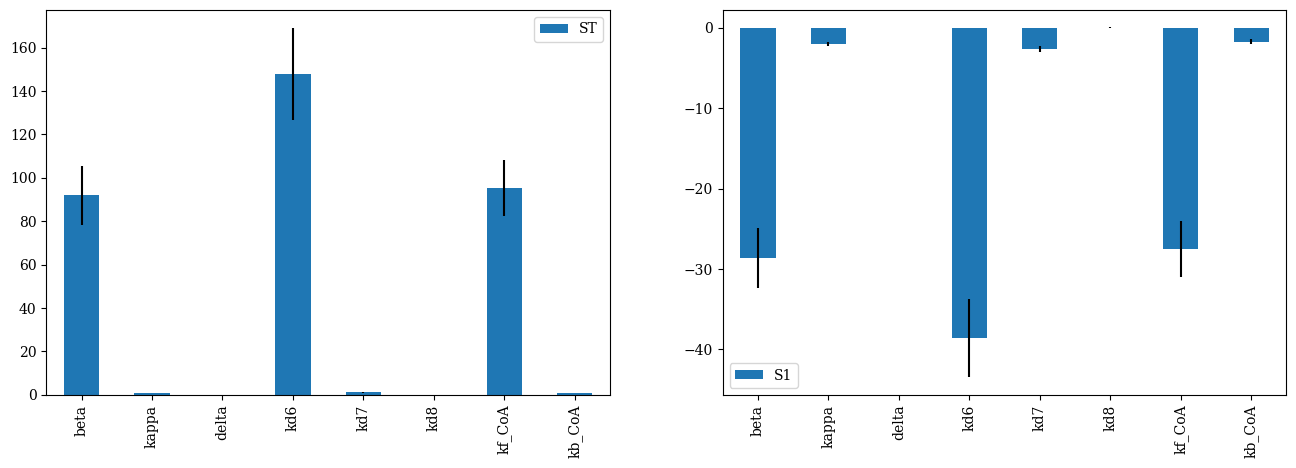

In [246]:
from SALib.plotting.bar import plot as barplot
from SALib.sample.fast_sampler import sample as fast_sampler
from SALib.analyze.fast import analyze as fast_analyzer

from SALib.test_functions import Ishigami


Si_saltelli = sobol.analyze(problem, a, print_to_console=False, calc_second_order=True)
Saltelli_T, Saltelli_1st, Saltelli_2st = Si_saltelli.to_df()

# More direct control by manually specifying figure attributes
# See Figure 2 below
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16,5))

ax1 = barplot(Saltelli_T, ax=ax1)
ax2 = barplot(Saltelli_1st, ax=ax2)


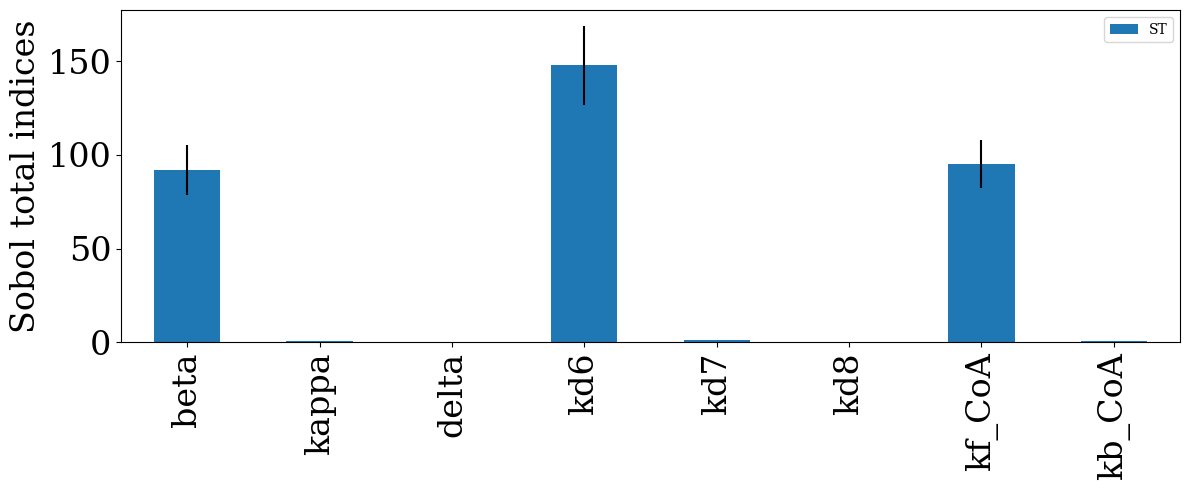

In [247]:
fig, ax1 = plt.subplots(1,1, figsize=(12,5))

ax1 = barplot(Saltelli_T, ax=ax1)
ax1.set_ylabel("Sobol total indices",fontsize=24)
ax1.tick_params(axis="both", labelsize=24)
#ax2 = barplot(Saltelli_1st, ax=ax2)
plt.tight_layout()
plt.savefig(RESULTS_DIR /"sobol_Total1.pdf")


,S2,S2_conf
"(beta, kappa)",31.708209,3.874643
"(beta, delta)",32.507714,3.926920
"(beta, kd6)",23.598235,3.087885
"(beta, kd7)",31.226642,3.861912
"(beta, kd8)",32.521096,3.928775
"(beta, kf_CoA)",25.902943,3.546779
"(beta, kb_CoA)",31.427641,3.924878
"(kappa, delta)",-41.899156,4.995829
"(kappa, kd6)",139.483305,19.808598
"(kappa, kd7)",-31.914443,3.871945


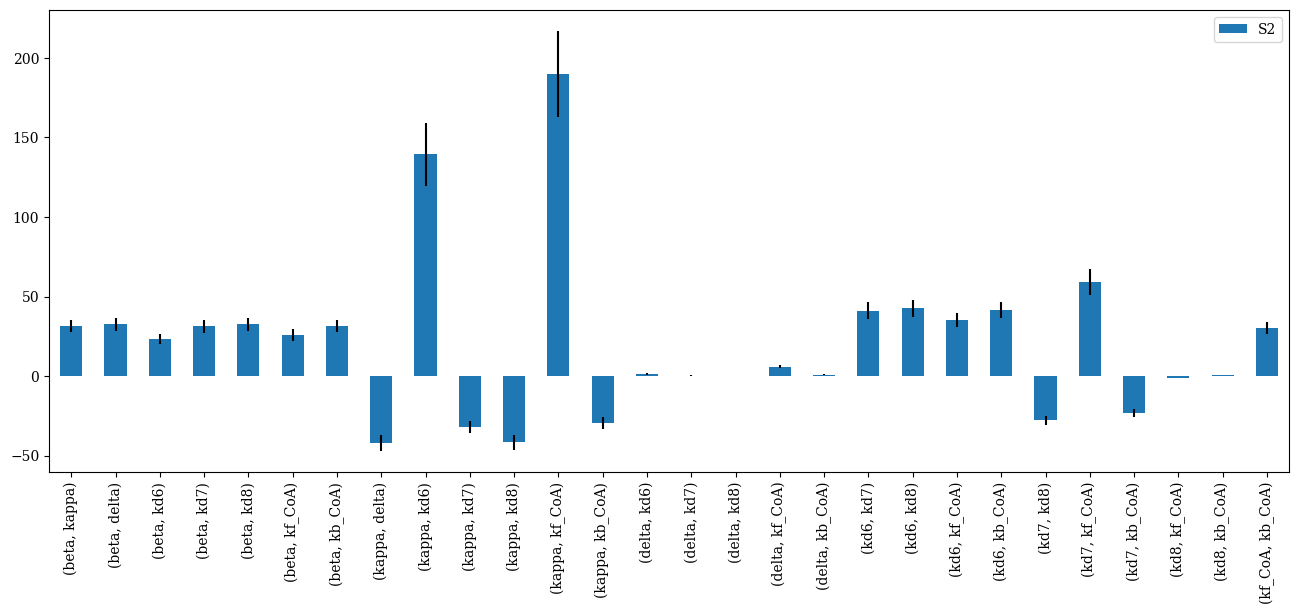

In [250]:
fig, (ax1) = plt.subplots(1,1, figsize=(16,6))
barplot(Saltelli_2st, ax = ax1)
plt.savefig(RESULTS_DIR /"sens_weiss_model1_2.pdf", dpi=300, bbox_inches="tight")
Saltelli_2st

In [251]:
Saltelli_2st["S2"]

(beta, kappa)        31.708209
(beta, delta)        32.507714
(beta, kd6)          23.598235
(beta, kd7)          31.226642
(beta, kd8)          32.521096
(beta, kf_CoA)       25.902943
(beta, kb_CoA)       31.427641
(kappa, delta)      -41.899156
(kappa, kd6)        139.483305
(kappa, kd7)        -31.914443
(kappa, kd8)        -41.667399
(kappa, kf_CoA)     189.885794
(kappa, kb_CoA)     -29.307146
(delta, kd6)          1.396498
(delta, kd7)          0.345597
(delta, kd8)          0.087940
(delta, kf_CoA)       6.055606
(delta, kb_CoA)       0.940928
(kd6, kd7)           41.240866
(kd6, kd8)           42.552723
(kd6, kf_CoA)        35.321239
(kd6, kb_CoA)        41.430136
(kd7, kd8)          -27.778879
(kd7, kf_CoA)        59.117179
(kd7, kb_CoA)       -23.155629
(kd8, kf_CoA)        -1.014428
(kd8, kb_CoA)         0.791598
(kf_CoA, kb_CoA)     30.337325
Name: S2, dtype: float64

In [252]:
Index= problem["names"]
Cols = problem["names"]
df = pd.DataFrame(Saltelli_2st["S2"].T)
df

,S2
"(beta, kappa)",31.708209
"(beta, delta)",32.507714
"(beta, kd6)",23.598235
"(beta, kd7)",31.226642
"(beta, kd8)",32.521096
"(beta, kf_CoA)",25.902943
"(beta, kb_CoA)",31.427641
"(kappa, delta)",-41.899156
"(kappa, kd6)",139.483305
"(kappa, kd7)",-31.914443
